# 2026 CITS4012 Project
**Group 5 — TweetQA: from-scratch TweetBiDAF, probability ensembling and OOF span reranking**

# Readme

This is the integrated implementation and evaluation notebook for Group 5. It follows the supplied template and contains the original source code, training logs, validation studies, attention figures, final predictions and evaluation evidence.

**Default behaviour:** run all cells to unpack embedded source/data/evidence, display saved training logs and figures, and independently verify ROUGE-L, EM and F1 from the saved predictions. No training, model fitting, model-weight download or fresh test prediction runs by default. BLEU-1/METEOR are displayed from the original saved evaluations; optional full rescoring uses NLTK/WordNet. The embedded payload removes dependence on a local repository or upload bundle.

**Optional validation inference:** set `RUN_VALIDATION_INFERENCE=True` to load the three exact QA checkpoints and original OOF reranker. A T4 GPU is recommended; CPU is slower. Models download from the pinned public repository archive or can be supplied via the same original archive filename. The same label-free prediction function was verified in the original Colab run.

**Training is disabled.** Complete training/baseline code and OOF orchestration are included for reproducibility. The training entry points are included for a separate reproduction run; this notebook deliberately refuses to train even if its training guard is changed. B3/B4 have saved validation experiments but **their fitted checkpoints and final test scores remain pending**. This notebook must not be presented as having those test evaluations.

The full class-based implementation is listed in the appendix at the bottom, as requested by the template. An embedded, checksum-verified copy is materialised before imports so that the notebook still runs top to bottom. Relative module imports remain isolated instead of merging conflicting function names into one namespace.

**Finalisation still required:** confirm B3/B4 inclusion with the report and run this notebook in clean Colab. Saved outputs here identify when they re-display historical experiments versus perform a new evidence check.

# 1.Dataset Processing

## 1.1 Runtime switches and embedded implementation
CPU is sufficient for the default evidence review. No extra files are required. The payload contains the assignment CSVs, source and supporting records, not pretrained model weights.

In [1]:
TRAIN = False
RUN_VALIDATION_INFERENCE = False
RESCORE_ALL_METRICS = False  # True installs NLTK if needed and requests WordNet for METEOR.

import os, sys, io, json, csv, base64, hashlib, zipfile, tempfile, statistics, platform
from pathlib import Path
from collections import Counter
import numpy as np
import torch
from IPython.display import display, Markdown, Image
WORK = Path(tempfile.mkdtemp(prefix="cits4012_group5_"))
os.chdir(WORK)
print("Group 5 | Python", platform.python_version(), "| PyTorch", torch.__version__)
print("Default: saved evidence verification; training:", TRAIN, "| fresh validation inference:", RUN_VALIDATION_INFERENCE)

Group 5 | Python 3.13.5 | PyTorch 2.14.0
Default: saved evidence verification; training: False | fresh validation inference: False


In [2]:
EMBEDDED_ZIP_BASE64 = '...'
assert hashlib.sha256(base64.b64decode(EMBEDDED_ZIP_BASE64)).hexdigest() == '9224285fbda5f10b0b346bd29cf6b1e4823cbb623731dcb5d8f0aa0c462c0e36'
with zipfile.ZipFile(io.BytesIO(base64.b64decode(EMBEDDED_ZIP_BASE64))) as z:
    for name in z.namelist():
        assert not Path(name).is_absolute() and ".." not in Path(name).parts
    z.extractall(WORK)
manifest = json.loads(Path("embedded_manifest.json").read_text())
for name, expected in manifest.items():
    assert hashlib.sha256(Path(name).read_bytes()).hexdigest() == expected, name
for name in list(sys.modules):
    if name == "src" or name.startswith("src."): del sys.modules[name]
sys.path.insert(0, str(WORK))
os.environ["TWEETQA_DIR"] = str(WORK / "data")
os.environ["A2_RESULTS"] = str(WORK / "new_runtime_results")
os.environ["A2_CKPT"] = str(WORK / "new_runtime_checkpoints")
from src import data as D, train as T, model as M, rerank as R
from src.evaluate import evaluate, normalize_answer
assert D.TEST_LOCKED is True
print("PASS:", len(manifest), "embedded files verified; source, datasets and recorded outputs available")

PASS: 420 embedded files verified; source, datasets and recorded outputs available


## 1.2 Task, splits and preprocessing

TweetQA supplies a tweet, a question and short free-text reference answers. The provided train file contains 10,692 rows. Exact duplicates are removed before a 10% tweet-grouped validation split, stratified by question word, with seed 4012. Questions about the same tweet stay in the same training/validation partition. Repeated question IDs are not treated as duplicate examples.

The tokenizer preserves raw character offsets. Word lookup can normalise handles, URLs, hashtags and elongated words, while character features retain raw token identity. Eight flags include token type, capitalisation, byline position and matching words in the other sequence. Vocabularies and in-domain FastText use the training portion only. No additional training dataset is introduced.

Reference answers are not always contiguous tweet spans. Training uses automatically selected **silver spans**, not human-annotated span positions: enumerate spans of at most 15 tokens, select by token F1 with deterministic tie-breaking, and retain examples meeting the training threshold. V2 uses one best span. The oracle measures an extractive ceiling; it is not model prediction.

In [3]:
train_rows, val_rows = D.get_splits()
assert len(train_rows) == 9570 and len(val_rows) == 1076
assert len({r["tweet"] for r in val_rows}) == 511
assert not ({r["tweet"] for r in train_rows} & {r["tweet"] for r in val_rows})
assert hashlib.sha1(Path("data/train.csv").read_bytes().replace(b"\r\n", b"\n")).hexdigest() == "8a52bb7dff56b11fdad1ab6fd3b848fbadc22849"
assert len({r["row_id"] for r in val_rows}) == 1076
print("Training:",len(train_rows),"questions /",len({r["tweet"] for r in train_rows}),"tweets")
print("Validation:",len(val_rows),"questions / 511 tweets; seed",D.SPLIT_SEED)
print("Question types:",dict(Counter(D._question_word(r["question"]) for r in train_rows)))
display(Markdown(Path("historical/results/DATA_REPORT.md").read_text()))

Training: 9570 questions / 4608 tweets
Validation: 1076 questions / 511 tweets; seed 4012
Question types: {'other': 703, 'what': 4050, 'when': 206, 'who': 2703, 'which': 238, 'where': 670, 'how': 744, 'why': 256}


# TweetQA data report (Stage 0)

Generated by `scripts/data_report.py`. Statistics are computed on **train only**. For test, only size, format and gold-answer presence are checked.

## Files and splits

| file | rows | unique tweets | unique qids | gold answers present |
|---|---|---|---|---|
| train.csv | 10692 | 5119 | 10526 | 10692/10692 |
| test.csv | 1086 | 583 | 1082 | 1086/1086 |

- Columns: `Question, Answer, Tweet, qid`. `Answer` is a numpy-array repr of one or more strings, e.g. `['w nj' 'w nj']`. The items are separated by a space or newline and quoted with `'` or `"`. Every row parses.
- **There is no validation split.** The sizes match the original TweetQA train (10,692) and dev (1,086) sets, so `test.csv` is the public dev set. It **has gold answers**.
- Tweets shared between train and test: 3.
- Train has 46 exact-duplicate rows. 166 rows share a qid, because qid is a hash of the question text and generic questions repeat across tweets.
- Train has 4 annotation-noise rows with question/answer 'tweet does not exist'.
- Questions per tweet (train): mean 2.09, max 8. **Any train/validation split must group by tweet** to avoid leakage.

- Test gold answers per example: {2: 1086}

## Lengths in tokens (train; Twitter-aware regex tokeniser)

| | p50 | p75 | p90 | p95 | p99 | max |
|---|---|---|---|---|---|---|
| tweet (unique) | 32 | 37 | 41 | 43 | 55 | 77 |
| question | 8 | 9 | 11 | 12 | 15 | 27 |
| answer | 2 | 3 | 5 | 7 | 9 | 19 |

Answers ≤ 10 tokens: 99.8%; ≤ 15: 100.0%; ≤ 20: 100.0%.

Gold answers per example (train): {1: 10692}

## Extractiveness (train)

- At least one gold answer is a case-insensitive substring of the tweet: **57.5%**
- After normalisation (lowercase, strip ASCII+Unicode punctuation and articles, collapse whitespace; whole-token match): **64.8%**
- All gold answers are raw substrings: 57.5%
- Every normalised answer token appears somewhere in the tweet (any order): 67.8%. At least half the tokens appear: 81.8%. No tokens appear: 13.7%
- The remaining examples are abstractive or paraphrased, so an extractive model's ceiling sits below 100. Stage 1 measures that ceiling (the oracle).

- Tweets ending in a `Name (@handle) Month D, YYYY` byline: 97.1%. An answer lies inside the byline in 24.9% of all train examples (who/when questions about the poster).

## Top 15 question first-words (train)

| word | count | % |
|---|---|---|
| what | 4526 | 42.3 |
| who | 2999 | 28.0 |
| how | 833 | 7.8 |
| where | 748 | 7.0 |
| why | 279 | 2.6 |
| which | 260 | 2.4 |
| when | 231 | 2.2 |
| whose | 81 | 0.8 |
| who's | 61 | 0.6 |
| is | 50 | 0.5 |
| the | 48 | 0.4 |
| in | 37 | 0.3 |
| what's | 26 | 0.2 |
| tweet | 20 | 0.2 |
| did | 19 | 0.2 |

## Answer types (train, first gold answer)

- mention/handle: 2.7%
- hashtag: 5.1%
- number: 7.8%
- date: 1.6%

## Tweet surface phenomena (train, unique tweets)

- contains @mention: 100.0%
- contains #hashtag: 38.2%
- contains URL: 0.0%
- contains elongation (char ×3+): 2.0%
- contains HTML entity (`&amp;` etc.): 0.0%
- contains emoji: 6.7%
- gold answers containing an emoji: 0; containing `#`: 124; containing `@`: 152

## 10 random train examples (raw)

- **Q:** who is the funny person who passed away?  
  **A:** ['alan rickman']  
  **Tweet:** Terribly sad news about the passing of Alan Rickman. A funny and engaging person who put a shy young actor at ease when I was on HP.— Oliver Phelps (@OliverPhelps) January 14, 2016
- **Q:** what does alistair brownlee do after a good race?  
  **A:** ['reflect']  
  **Tweet:** This is the way to get back from and reflect on a good race. Alistair Brownlee (@AliBrownleetri) July 24, 2014
- **Q:** tweet is in spanish  
  **A:** ['tweet is in spanish']  
  **Tweet:** La creatividad de los FIELES peregrinos hacia #RomeroBeato RT Beato Mons. Romero (@san_MonsRomero) May 23, 2015
- **Q:** who was the author of the tweet?  
  **A:** ['reuben frank']  
  **Tweet:** Chip: "We didn't coach well. we didn't do anything well." — Reuben Frank (@RoobCSN) November 26, 2015
- **Q:** what is obama not buying?  
  **A:** ['peas']  
  **Tweet:** respect the nyt, but not buying peas in guac. onions, garlic, hot peppers. classic. President Obama (@POTUS) July 1, 2015
- **Q:** what show does amanda say she loves?  
  **A:** ['svu']  
  **Tweet:** Reasons why I love SVU they talk about IMPORTANT matters and have heroes like @VP on the show to guest star besides @Mariska ❤️ #TrustFin— Amanda (@xo_amanda03) September 29, 2016
- **Q:** where were the iraqi citizens trapped?  
  **A:** ['mount sinjar']  
  **Tweet:** Rescued Yezidis aboard Iraqi Air Force helicopter that evacuated trapped civilians from Mount Sinjar Ivan Watson (@IvanCNN) August 11, 2014
- **Q:** what community in texas had devastating news  
  **A:** ['sutherland springs community']  
  **Tweet:** Devastating news from Texas today. Praying for the victims, the heroic first responders, and the whole Sutherland Springs community.— Rep. Steve Scalise (@SteveScalise) November 5, 2017
- **Q:** how long can you go to the game?  
  **A:** ['5 minutes']  
  **Tweet:** You can never go 5min of a soccer game without this happening 😂😂😂"@EpicSportVines: Minion Soccer | Richard Torres (@richee_torres) June 19, 2014
- **Q:** what did mirki and roger share?  
  **A:** ['twins were born']  
  **Tweet:** Mirka and I are so incredibly happy to share that Leo and Lenny were born this evening! #TwinsAgain #Miracle— Roger Federer (@rogerfederer) May 6, 2014

## Template notebook (`template.ipynb`)

Required section headings, which must not be modified:
1. `# 2026 CITS4012 Project` (title cell; rename the file with the group id)
2. `# Readme` (notes to the marker; OOP code goes at the bottom of the notebook)
3. `# 1.Dataset Processing`
4. `# 2. Model Implementation`
5. `# 3.Testing and Evaluation`

Any number of code and markdown cells may be added under each heading.


The dataset report above is a historical record. Its statement that test was not yet used applies to that development stage. The final test has since been evaluated with the frozen system. There are three tweets shared by the supplied train/test files; the grouping guarantees training–validation separation, not complete disjointness across all supplied files.

# 2. Model Implementation

## 2.1 Main model and selected inference system

Each tweet/question token is represented by a 100-dimensional word vector, a 150-dimensional character-CNN representation (50 filters at widths 3/4/5), and eight flags. A two-layer highway feeds a shared bidirectional LSTM (128 hidden units per direction). Trilinear similarity computes context-to-question and question-to-context attention. A projection and gated four-head self-attention feed modelling LSTMs and start/end span heads.

The neural architecture adapts BiDAF (Seo et al., 2017) and gated self-attention ideas associated with R-Net (Wang et al., 2017). The task-specific combination includes raw-character features alongside normalised words, tweet/byline flags and silver-span supervision. These established components must be credited; the entire BiDAF mechanism is not an original invention.

Training uses Adam, learning rate 0.0005, batch size 32, dropout 0.2, gradient clipping at 5, up to 30 epochs and early stopping on validation ROUGE-L with patience 4. FastText is trained from scratch on the training split. All three final models use single-span supervision and their own stored vocabularies.

The selected final predictor averages the **start probabilities** across seeds 1–3 and separately averages their end probabilities. It proposes the Top-10 legal spans (maximum 15 tokens). An OOF-trained LambdaMART reranker uses 30 fixed candidate features and selects one raw tweet substring. No majority vote or logit averaging is used. Fold models used for OOF training are not substituted for the three full-training inference checkpoints.

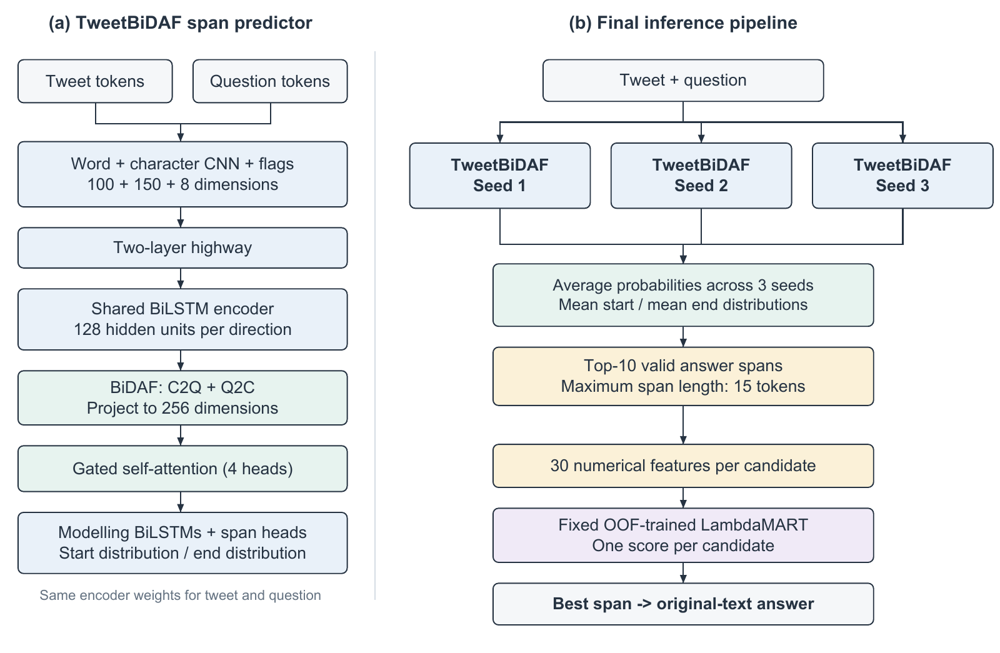

In [4]:
display(Image(filename="figures/architecture.png", width=1050))

In [5]:
frozen = json.loads(Path("historical/results/FROZEN_CONFIG.json").read_text())
FROZEN_CFG = {k:v for k,v in frozen.items() if not k.startswith("_")}
print("Frozen base-model configuration:")
print(json.dumps(FROZEN_CFG, indent=2))
print("Reranker feature order:", list(R.FEATURE_NAMES))
assert len(R.FEATURE_NAMES) == 30

Frozen base-model configuration:
{
  "attn_heads": 4,
  "batch_size": 32,
  "biattn_mode": "both",
  "char_dim": 32,
  "char_filters": 50,
  "char_widths": [
    3,
    4,
    5
  ],
  "dropout": 0.2,
  "epochs": 30,
  "grad_clip": 5.0,
  "hidden": 128,
  "lr": 0.0005,
  "max_span_len": 15,
  "min_freq": 2,
  "n_flags": 8,
  "patience": 4,
  "soft_spans": false,
  "tau": 0.5,
  "use_char_cnn": true,
  "use_normaliser": true,
  "use_self_attn": true,
  "use_token_flags": true,
  "weight_decay": 0.0,
  "word_dim": 100,
  "word_init": "fasttext"
}
Reranker feature order: ['base_score', 'score_margin', 'reciprocal_rank', 'start_logp', 'end_logp', 'length', 'length_fraction', 'start_fraction', 'end_fraction', 'distance_from_end', 'question_overlap', 'question_jaccard', 'context_overlap', 'context_jaccard', 'starts_word', 'ends_word', 'contains_mention', 'contains_url', 'contains_number', 'qtype_what', 'qtype_who', 'qtype_how', 'qtype_where', 'qtype_why', 'qtype_which', 'qtype_when', 'qtype_

## 2.2 OOF training, baselines and execution controls

OOF candidate generation uses three tweet-grouped training folds. Each fold model trains only on the other folds, with its own inner tweet-grouped early-stopping split. The held-out fold supplies candidates for reranker training. Fixed validation remains outside model fitting. The final reranker is trained with 150 trees, learning rate 0.05, depth 4, 15 leaves and regularisation 1.0. This workflow is fully included in `scripts/make_oof_reranker_notebooks.py` below; it is not executed by Run all.

| Baseline | Original workflow | Current evidence |
|---|---|---|
| B1 | Lexical proximity and answer-type rules; settings selected on training | Validation and test complete |
| B2 | Task-specific components disabled; three independently trained seeds | Validation and test complete; report mean ± sample SD |
| B3 | BERTweet fine-tuned with a span head; 3 epochs, lr 3e-5 | Saved validation logs; fitted weights/test results pending |
| B4 | T5-small fine-tuned to generate answers; 5 epochs, lr 3e-4, beam 4 | Saved validation logs; fitted weights/test results pending |
| B5 | Qwen2.5-1.5B-Instruct, four fixed training examples, greedy decoding, max 16 new tokens | Validation and test complete |

Qwen is a pretrained baseline, not the required from-scratch main model. B3–B5 use pretrained weights, but no additional project training data. All baseline scores below come from team-run experiments.

**B1 compatibility:** the original run used Python 3.11. Newer built-in floating-point summation changed four near-tie choices. A module-local left-to-right sum reproduces the original rules without changing settings or metric tolerances. This was diagnosed on validation before test.

In [6]:
from src.baselines import b1_lexical as B1

def b1_original_sum(values, start=0):
    total = start
    for value in values: total += value
    return total
B1.sum = b1_original_sum

# Training entry points remain available but are never called by default.
if TRAIN:
    raise RuntimeError("Training is intentionally disabled in this final-evaluation notebook. Use the included training implementation in a separate reproduction run; do not overwrite historical models.")
print("Training disabled. Full implementations and orchestration are included in the appendix.")

Training disabled. Full implementations and orchestration are included in the appendix.


## 2.3 Original saved training and baseline logs
These records are read from historical files, not generated by new training. The Kaggle ablations and later Colab attention runs are separate batches and retain their own identities.

In [7]:
def read_csv(path):
    with Path(path).open(encoding="utf-8-sig", newline="") as f: return list(csv.DictReader(f))
all_runs = read_csv("historical/results/runs.csv")
gpu_runs = [r for r in all_runs if r["split"] == "val" and "kaggle-gpu-run" in r["notes"]]
print("=== Selected final QA checkpoints: original per-epoch logs ===")
for p in sorted(Path("attention/results/history").glob("A5_single_span*.json")):
    h=json.loads(p.read_text()); print("\n",p.name)
    for e in h["history"]: print("epoch",e["epoch"],"train_loss",round(e["train_loss"],6),"val ROUGE-L",round(e["rougeL"],6))
print("\n=== Original comparison / ablation training logs ===")
for r in gpu_runs:
    p=Path("historical/results/history")/(r["run_id"]+".json")
    if p.exists():
        h=json.loads(p.read_text()); print("\n",r["run_id"],"seed",r["seed"])
        for e in h["history"]: print("epoch",e["epoch"],"loss",round(e["train_loss"],5),"val ROUGE-L",round(e["rougeL"],5))
print("\n=== Original pretrained-baseline logs (saved text) ===")
for p in sorted(Path("historical/results/logs").glob("stage6_*.log")):
    print("\n",p.name); print(p.read_text())

=== Selected final QA checkpoints: original per-epoch logs ===

 A5_single_span-s1-20261014-071243.json
epoch 1 train_loss 5.058313 val ROUGE-L 33.108293
epoch 2 train_loss 4.134743 val ROUGE-L 37.821773
epoch 3 train_loss 3.711341 val ROUGE-L 40.993039
epoch 4 train_loss 3.374552 val ROUGE-L 43.084241
epoch 5 train_loss 3.063647 val ROUGE-L 42.367654
epoch 6 train_loss 2.778071 val ROUGE-L 43.466063
epoch 7 train_loss 2.557848 val ROUGE-L 43.494045
epoch 8 train_loss 2.331269 val ROUGE-L 42.997025
epoch 9 train_loss 2.170227 val ROUGE-L 42.424249
epoch 10 train_loss 2.008647 val ROUGE-L 44.382511
epoch 11 train_loss 1.867161 val ROUGE-L 43.315572
epoch 12 train_loss 1.726235 val ROUGE-L 41.707229
epoch 13 train_loss 1.614258 val ROUGE-L 42.408105
epoch 14 train_loss 1.495098 val ROUGE-L 42.212033

 A5_single_span-s2-20261014-071828.json
epoch 1 train_loss 5.040581 val ROUGE-L 32.711864
epoch 2 train_loss 4.177327 val ROUGE-L 35.615758
epoch 3 train_loss 3.699831 val ROUGE-L 38.904759


# 3.Testing and Evaluation

## 3.1 Metrics and model selection on validation

Every metric is computed per example against each reference answer, retaining the highest value, then averaged and multiplied by 100. BLEU-1 measures unigram precision with a brevity penalty; METEOR also considers recall, alignment and WordNet matches; ROUGE-L measures ordered overlap using longest common subsequences (β=1.2). EM requires equality after normalisation, and token F1 balances overlap precision and recall. Normalisation lowercases, replaces Unicode/ASCII punctuation with spaces, removes articles, and collapses whitespace.

ROUGE-L was the headline selection metric. These overlap metrics reward partial answers, but can penalise valid paraphrases or credit incomplete spans. The provided test has two references per question; validation carved from train has one. Higher test scores do not by themselves show a model improvement.

The one-factor development sweep selected a lower learning rate and in-domain FastText. Single-span training subsequently outperformed wide soft-span supervision, yielding v2. Historical selection rows and their configurations remain in the payload; they must not be mixed with independent later retraining batches.

In [8]:
METRICS=("bleu1","meteor","rougeL","em","f1")
def aggregate(rows):
    assert rows
    return {m:(statistics.mean(float(r[m]) for r in rows),statistics.stdev(float(r[m]) for r in rows) if len(rows)>1 else None) for m in METRICS}
def show_table(rows, title):
    text="### "+title+"\n\n| System | n | BLEU-1 | METEOR | ROUGE-L | EM | F1 |\n|---|---:|---:|---:|---:|---:|---:|"
    for label,rs in rows:
        a=aggregate(rs)
        text+="\n| "+label+" | "+str(len(rs))+" | "+" | ".join(f"{a[m][0]:.2f}"+(f" ± {a[m][1]:.2f}" if a[m][1] is not None else "") for m in METRICS)+" |"
    display(Markdown(text))
validation=[r for r in all_runs if r["split"]=="val"]
local=[r for r in validation if "kaggle-gpu-run" not in r["notes"]]
show_table([(name,[r for r in local if r["model"] in names]) for name,names in [
    ("Initial configuration",["main_v1","sw_base"]),
    ("Lower learning rate",["sw_lr5e-4"]),
    ("Lower learning rate + in-domain FastText",["cand_lr5e-4_ft"])]],"Original hyperparameter development (local batch)")
show_table([(label,[r for r in gpu_runs if r["model"]==name]) for label,name in [
    ("Single-span v2 (original Kaggle batch)","A5_single_span"),("B2 simplified","B2_vanilla"),
    ("B3 fine-tuned BERTweet","B3_bertweet-base"),("B4 fine-tuned T5-small","B4_t5-small"),
    ("B5 four-shot Qwen","B5_Qwen2.5-1.5B-Instruct_4shot")]],"Validation baseline comparison — original experiments")

### Original hyperparameter development (local batch)

| System | n | BLEU-1 | METEOR | ROUGE-L | EM | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Initial configuration | 3 | 34.10 ± 0.58 | 29.30 ± 0.34 | 40.19 ± 0.52 | 22.24 ± 0.94 | 40.35 ± 0.55 |
| Lower learning rate | 3 | 35.13 ± 0.37 | 30.45 ± 0.64 | 41.00 ± 0.45 | 22.71 ± 0.27 | 41.08 ± 0.43 |
| Lower learning rate + in-domain FastText | 3 | 36.71 ± 0.97 | 31.77 ± 0.94 | 42.57 ± 0.84 | 24.38 ± 0.94 | 42.59 ± 0.87 |

### Validation baseline comparison — original experiments

| System | n | BLEU-1 | METEOR | ROUGE-L | EM | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Single-span v2 (original Kaggle batch) | 3 | 39.04 ± 0.09 | 33.31 ± 0.72 | 44.51 ± 0.11 | 27.94 ± 0.75 | 44.65 ± 0.11 |
| B2 simplified | 3 | 25.66 ± 0.22 | 23.62 ± 0.04 | 30.14 ± 0.29 | 15.95 ± 0.47 | 30.06 ± 0.30 |
| B3 fine-tuned BERTweet | 1 | 55.01 | 44.59 | 59.98 | 43.12 | 60.23 |
| B4 fine-tuned T5-small | 1 | 52.64 | 43.65 | 56.93 | 38.01 | 57.06 |
| B5 four-shot Qwen | 1 | 61.30 | 49.07 | 66.45 | 49.16 | 66.91 |

## 3.2 Controlled ablations

A1 tests character representations for rare/OOV tokens. A2 removes normalisation and flags together, so it does not separate their individual effects. A3 removes self-attention; A4 removes Q2C while retaining C2Q; A5 replaces single-span supervision with wide soft targets. All comparisons below use the matching original GPU batch with three seeds and fixed validation—not ensemble test results.

In [9]:
ablation_names=[("Full single-span v2","A5_single_span"),("A1: no character CNN","S_A1_no_char"),
("A2: no normaliser/flags","S_A2_no_norm_flags"),("A3: no self-attention","S_A3_no_selfattn"),
("A4: no Q2C","S_A4_c2q_only"),("A5: wide soft targets","cand_lr5e-4_ft"),("B2: simplified","B2_vanilla")]
show_table([(label,[r for r in gpu_runs if r["model"]==name]) for label,name in ablation_names],"Controlled v2 ablations — validation")
reference=aggregate([r for r in gpu_runs if r["model"]=="A5_single_span"])["rougeL"][0]
for label,name in ablation_names[1:]:
    value=aggregate([r for r in gpu_runs if r["model"]==name])["rougeL"][0]
    print(label,"ΔROUGE-L",f"{value-reference:+.2f}")

### Controlled v2 ablations — validation

| System | n | BLEU-1 | METEOR | ROUGE-L | EM | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Full single-span v2 | 3 | 39.04 ± 0.09 | 33.31 ± 0.72 | 44.51 ± 0.11 | 27.94 ± 0.75 | 44.65 ± 0.11 |
| A1: no character CNN | 3 | 38.13 ± 0.21 | 33.12 ± 0.19 | 43.56 ± 0.39 | 26.43 ± 0.23 | 43.68 ± 0.36 |
| A2: no normaliser/flags | 3 | 28.12 ± 0.74 | 25.66 ± 0.43 | 32.82 ± 0.69 | 18.22 ± 0.74 | 32.77 ± 0.73 |
| A3: no self-attention | 3 | 37.31 ± 0.96 | 32.07 ± 0.21 | 42.52 ± 0.84 | 26.15 ± 1.77 | 42.60 ± 0.92 |
| A4: no Q2C | 3 | 38.10 ± 0.74 | 32.85 ± 0.20 | 43.50 ± 0.70 | 26.61 ± 1.02 | 43.61 ± 0.78 |
| A5: wide soft targets | 3 | 36.81 ± 0.24 | 31.99 ± 0.63 | 42.95 ± 0.47 | 23.95 ± 0.38 | 43.01 ± 0.46 |
| B2: simplified | 3 | 25.66 ± 0.22 | 23.62 ± 0.04 | 30.14 ± 0.29 | 15.95 ± 0.47 | 30.06 ± 0.30 |

A1: no character CNN ΔROUGE-L -0.94
A2: no normaliser/flags ΔROUGE-L -11.68
A3: no self-attention ΔROUGE-L -1.99
A4: no Q2C ΔROUGE-L -1.01
A5: wide soft targets ΔROUGE-L -1.56
B2: simplified ΔROUGE-L -14.37


Normalisation/flags have the largest measured contribution. Character features, self-attention and Q2C also improve mean performance in these controlled comparisons. This supports the combined design, but ablations change parameter counts and optimisation behaviour, so the differences should not be interpreted as perfectly isolated causal mechanisms.

## 3.3 Ensemble/reranker selection and validation reproduction

The selected ensemble alone scores 45.72 validation ROUGE-L; the original OOF reranker raises it to 47.11. Additional features and matched ensemble-OOF training did not beat the selected configuration. The +1.39 reranking effect has a tweet-cluster bootstrap 95% interval of approximately [+0.27,+2.52]. This interval does not account for repeated validation-based exploration. Top-K oracle values use reference answers to choose candidates and are diagnostic ceilings, not model performance.

In [10]:
selection=json.loads(Path("experiments/ensemble_feature_artifacts/summary.json").read_text())
show_table([(name,[scores]) for name,scores in selection["scores"].items()],"Ensemble feature comparison — validation")
check=json.loads(Path("evidence/01_validation/validation_checks.json").read_text())
assert check["passed"] and check["exact_matches"]==1076 and check["mismatch_count"]==0
print("Recorded independent Colab validation reproduction: 1076/1076 exact answers; all five metrics matched")
print("Recorded validation scores:",check["scores"])
for label,file in [("B1","evidence/03_B1_B5/B1_validation_checks.json"),("B5","evidence/03_B1_B5/B5_validation_checks.json")]+[(f"B2 seed {s}",f"evidence/04_B2/B2_s{s}_val_checks.json") for s in (1,2,3)]:
    saved=json.loads(Path(file).read_text());assert saved["passed"];print(label,"validation PASS",saved.get("exact_matches","aggregate metrics"))

### Ensemble feature comparison — validation

| System | n | BLEU-1 | METEOR | ROUGE-L | EM | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Ensemble_base | 1 | 40.13 | 34.08 | 45.72 | 28.53 | 45.89 |
| Ensemble_original | 1 | 41.61 | 34.86 | 47.11 | 30.11 | 47.32 |
| Ensemble_enhanced | 1 | 41.48 | 34.93 | 46.70 | 30.67 | 46.89 |

Recorded independent Colab validation reproduction: 1076/1076 exact answers; all five metrics matched
Recorded validation scores: {'bleu1': 41.611863196854394, 'meteor': 34.857259256122916, 'rougeL': 47.111843224551954, 'em': 30.111524163568774, 'f1': 47.31876525048259}
B1 validation PASS aggregate metrics
B5 validation PASS 1076
B2 seed 1 validation PASS 1076
B2 seed 2 validation PASS 1076
B2 seed 3 validation PASS 1076


## 3.4 Final test comparison

The configurations were frozen before test evaluation. Test prediction inputs used empty answer placeholders; reference answers were retained separately for scoring. All 1,086 rows were preserved, including repeated question IDs. Predictions were saved before scoring. The table below reads the completed result archives; it does not generate new answers.

B2 is mean ± sample SD across three individual models. The main row is one probability ensemble plus reranker, not a seed average. B3/B4 test scores are unavailable and are not replaced by their validation values.

In [11]:
summary=json.loads(Path("test_results.json").read_text())
text="| System | BLEU-1 | METEOR | ROUGE-L | EM | F1 |\n|---|---:|---:|---:|---:|---:|"
for s in summary["systems"]:
    text+="\n| "+s["label"]+" | "+" | ".join(f"{s['scores'][m]:.2f}"+(f" ± {s['sd'][m]:.2f}" if "sd" in s else "") for m in METRICS)+" |"
display(Markdown(text))
print("Pending test evaluations:",", ".join(summary["pending"]))
print("Main system ROUGE-L:",summary["systems"][2]["scores"]["rougeL"])

| System | BLEU-1 | METEOR | ROUGE-L | EM | F1 |
|---|---:|---:|---:|---:|---:|
| B1: lexical rules | 21.76 | 17.16 | 26.14 | 14.46 | 26.16 |
| B2: simplified neural model | 30.73 ± 0.98 | 27.81 ± 0.49 | 35.14 ± 1.01 | 21.82 ± 0.96 | 34.96 ± 1.06 |
| TweetBiDAF v2 ensemble + original OOF LambdaMART | 50.99 | 42.81 | 56.17 | 39.96 | 56.13 |
| B5: four-shot Qwen2.5-1.5B-Instruct | 72.08 | 56.35 | 75.72 | 63.54 | 75.93 |

Pending test evaluations: B3: fine-tuned BERTweet, B4: fine-tuned T5-small
Main system ROUGE-L: 56.17193575384544


The full selected system outperforms lexical B1 and average simplified B2. The main–B2 test difference includes architectural components, ensembling and reranking, so the controlled validation ablations—not this aggregate difference—support claims about individual components. Qwen is the strongest completed test baseline. Its advantage contextualises the benefits of large-scale pretraining; it cannot replace the required from-scratch main model.

### Verify saved predictions against the supplied references

Default verification recalculates ROUGE-L, EM and F1 for all completed test runs and main validation. BLEU-1/METEOR remain the original recorded values unless full rescoring is enabled. No model weights are loaded and no predictions are regenerated.

In [12]:
if RESCORE_ALL_METRICS:
    import importlib.util,subprocess
    if importlib.util.find_spec("nltk") is None:
        subprocess.check_call([sys.executable,"-m","pip","install","-q","nltk==3.9.1"])
    checked_metrics=METRICS
else:
    checked_metrics=("rougeL","em","f1")
# Final test labels are read solely for scoring saved, already-frozen predictions.
D.TEST_LOCKED=False
try: test_rows=D.load_test()
finally: D.TEST_LOCKED=True
assert len(test_rows)==1086
files_to_check=[("main","evidence/02_main_test/test/test_predictions.json","evidence/02_main_test/test/test_metrics.json"),
("B1","evidence/03_B1_B5/B1_test_predictions.json","evidence/03_B1_B5/B1_test_metrics.json"),
("B5","evidence/03_B1_B5/B5_test_predictions.json","evidence/03_B1_B5/B5_test_metrics.json")]+[
(f"B2 seed {s}",f"evidence/04_B2/B2_s{s}_test_predictions.json",f"evidence/04_B2/B2_s{s}_test_metrics.json") for s in (1,2,3)]
for label,pred_path,metric_path in files_to_check:
    records=json.loads(Path(pred_path).read_text());expected=json.loads(Path(metric_path).read_text())
    assert len(records)==1086 and [r["row_id"] for r in records]==[r["row_id"] for r in test_rows]
    assert [r["qid"] for r in records]==[r["qid"] for r in test_rows]
    actual=evaluate([r["prediction"] for r in records],[r["answers"] for r in test_rows],metrics=checked_metrics)
    assert all(abs(actual[m]-expected[m])<1e-4 for m in checked_metrics),(label,actual,expected)
    print("PASS saved-prediction score check:",label,actual)
records=json.loads(Path("evidence/01_validation/validation_predictions.json").read_text())
assert [r["row_id"] for r in records]==[r["row_id"] for r in val_rows]
actual=evaluate([r["prediction"] for r in records],[r["answers"] for r in val_rows],metrics=checked_metrics)
assert all(abs(actual[m]-check["scores"][m])<1e-4 for m in checked_metrics)
print("PASS saved main validation predictions:",actual)
assert D.TEST_LOCKED is True

PASS saved-prediction score check: main {'rougeL': 56.17193575384544, 'em': 39.96316758747698, 'f1': 56.134970813250234}
PASS saved-prediction score check: B1 {'rougeL': 26.144181542900473, 'em': 14.456721915285451, 'f1': 26.16434823617144}


PASS saved-prediction score check: B5 {'rougeL': 75.71524836420596, 'em': 63.53591160220994, 'f1': 75.93358620820435}
PASS saved-prediction score check: B2 seed 1 {'rougeL': 35.10331083445072, 'em': 22.375690607734807, 'f1': 34.948694824406815}
PASS saved-prediction score check: B2 seed 2 {'rougeL': 36.1737320210122, 'em': 22.375690607734807, 'f1': 36.029585445840176}


PASS saved-prediction score check: B2 seed 3 {'rougeL': 34.14539042753091, 'em': 20.718232044198896, 'f1': 33.91402790086573}
PASS saved main validation predictions: {'rougeL': 47.111843224551954, 'em': 30.111524163568774, 'f1': 47.31876525048259}


## 3.5 Qualitative attention analysis

These figures come from the identified single v2 checkpoint `A5_single_span-s1-20261014-071243`, not the complete ensemble/reranker. Their questions, tweets, references and predictions are printed in each image. The three successes illustrate entity/location extraction; failures illustrate author/body confusion, non-extractive answers and lexical variation. Attention patterns are diagnostic associations, not causal explanations. A component's utility is better supported by the repeated ablation.

### Success Who
Successful entity extraction: compare the predicted boundaries with the named person in the tweet.

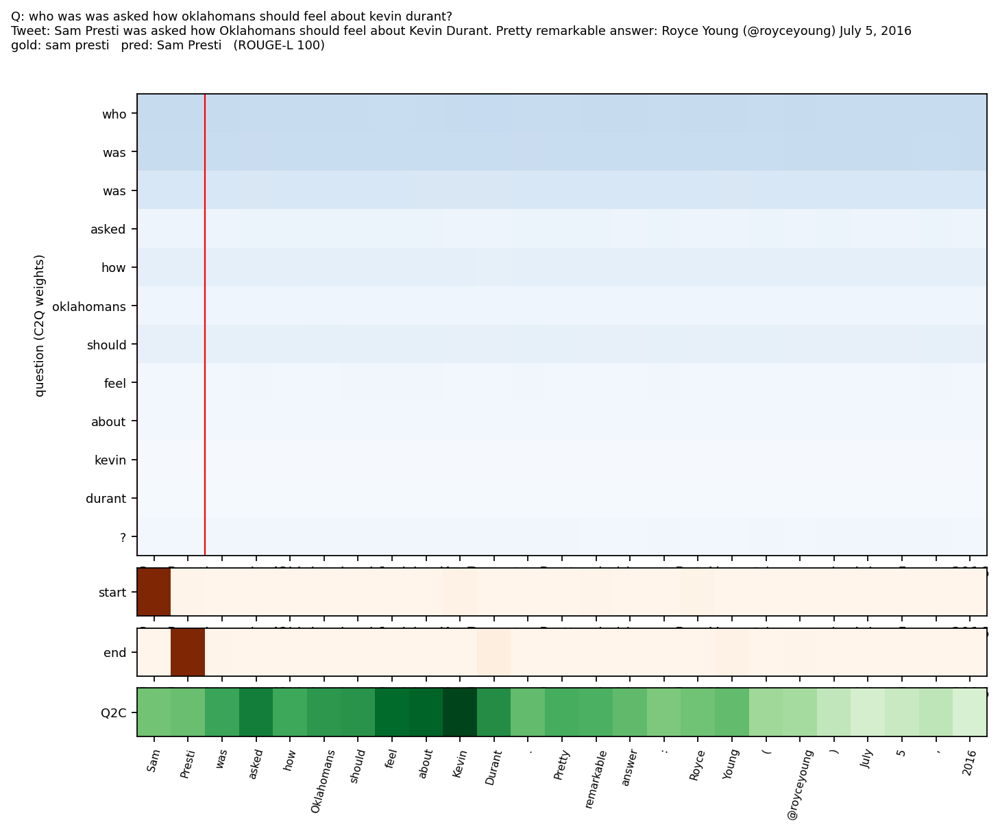

In [13]:
display(Image(filename="attention/results/figures/attn_success_who.png", width=1000))

### Success What
Successful short-answer extraction: the output heads select the relevant entity rather than the entire surrounding sentence.

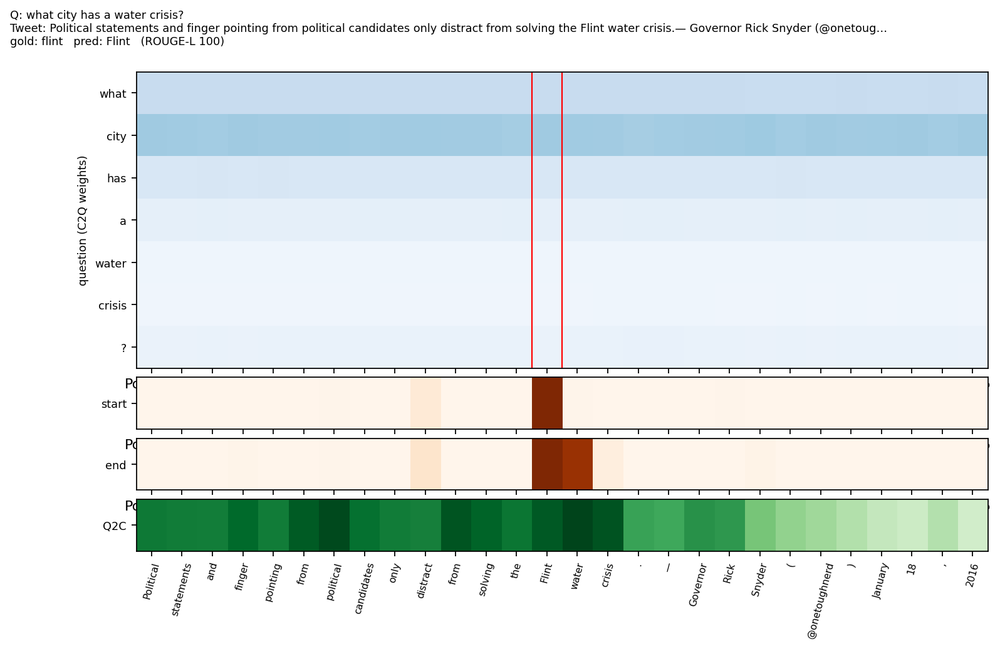

In [14]:
display(Image(filename="attention/results/figures/attn_success_what.png", width=1000))

### Success Where
Successful location extraction: the predicted span retains the complete place name.

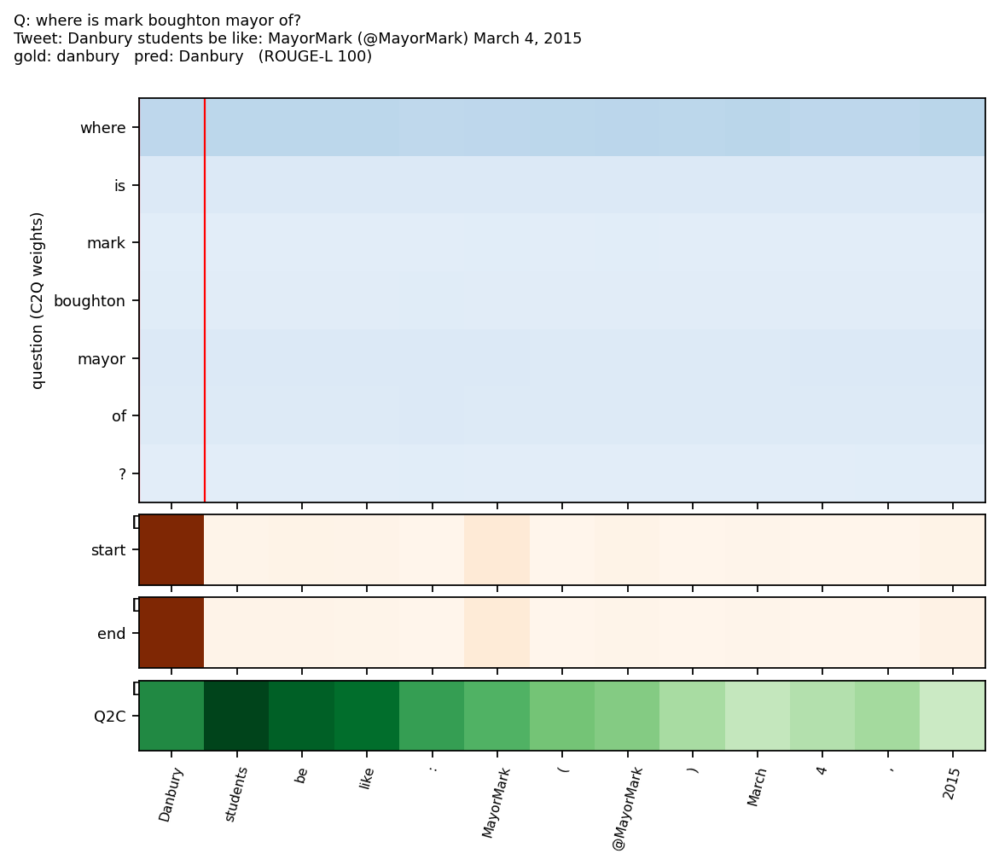

In [15]:
display(Image(filename="attention/results/figures/attn_success_where.png", width=1000))

### Fail Username
Author/body confusion: the model selects “DUDES” instead of the author “Lauren Graham”. The boundary heads favour the beginning of the tweet despite the author information being present in the byline.

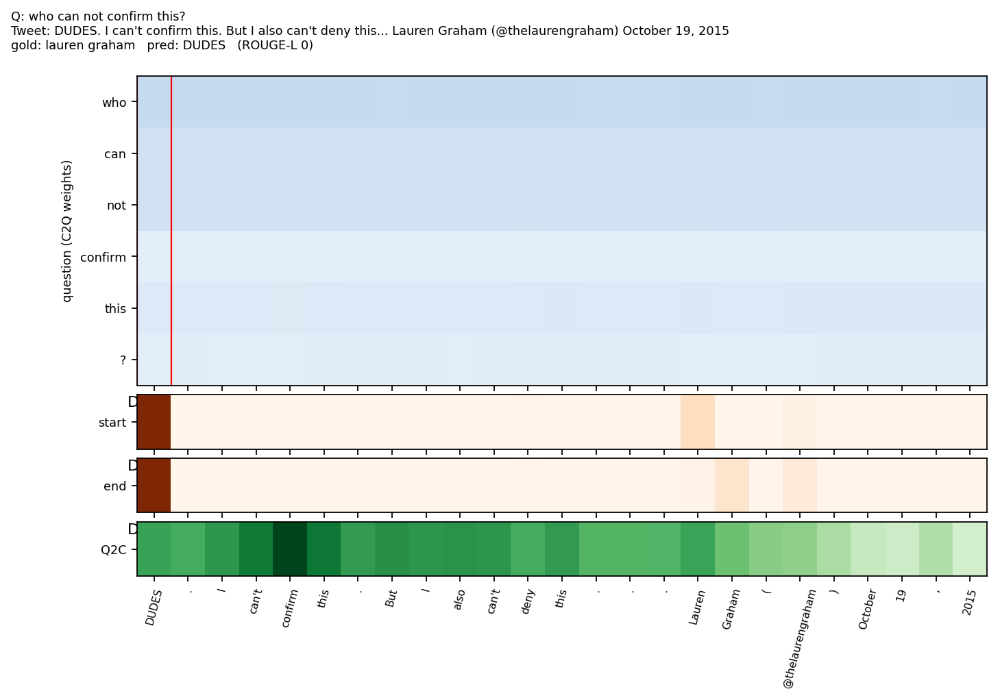

In [16]:
display(Image(filename="attention/results/figures/attn_fail_username.png", width=1000))

### Fail Abstractive
This selected failure illustrates the limitations of a span-only output. Read the reference and tweet to distinguish missing span coverage from selecting the wrong existing span.

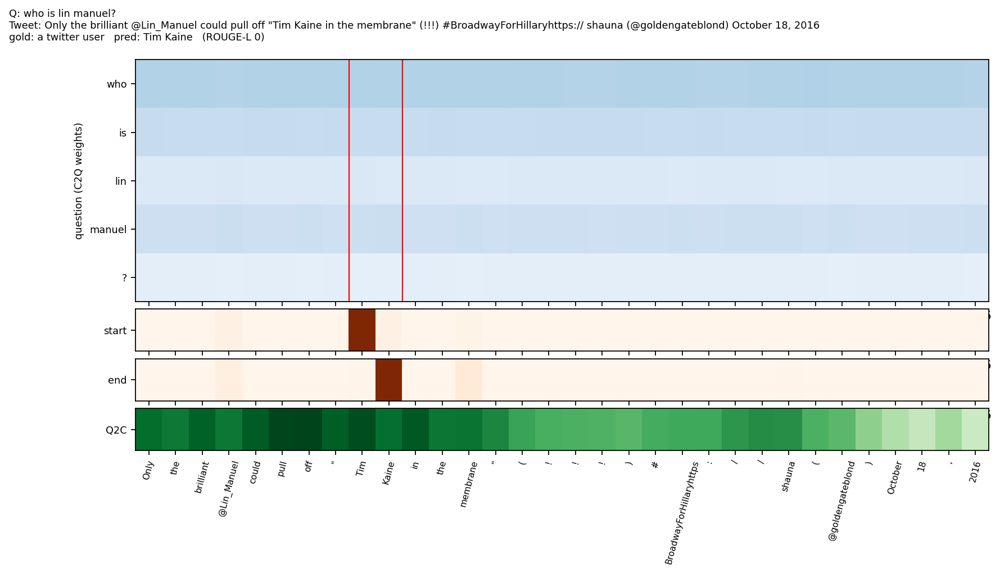

In [17]:
display(Image(filename="attention/results/figures/attn_fail_abstractive.png", width=1000))

### Fail Slang Misspelt
This failure was selected by a lexical-similarity heuristic. The category is a diagnostic lead, not a manually confirmed causal explanation.

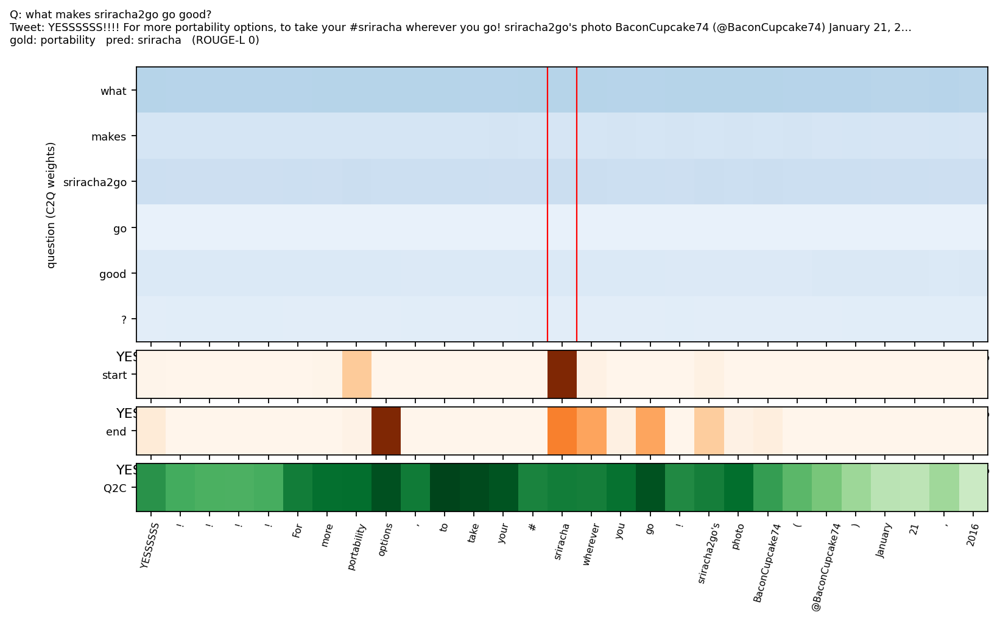

In [18]:
display(Image(filename="attention/results/figures/attn_fail_slang_misspelt.png", width=1000))

### Self-attention comparison and training dynamics
The self-attention comparison uses separately trained full and ablated models. It is not a test-time intervention on one fixed model. Training curves describe the saved seed runs and early stopping.

self_attn_A3


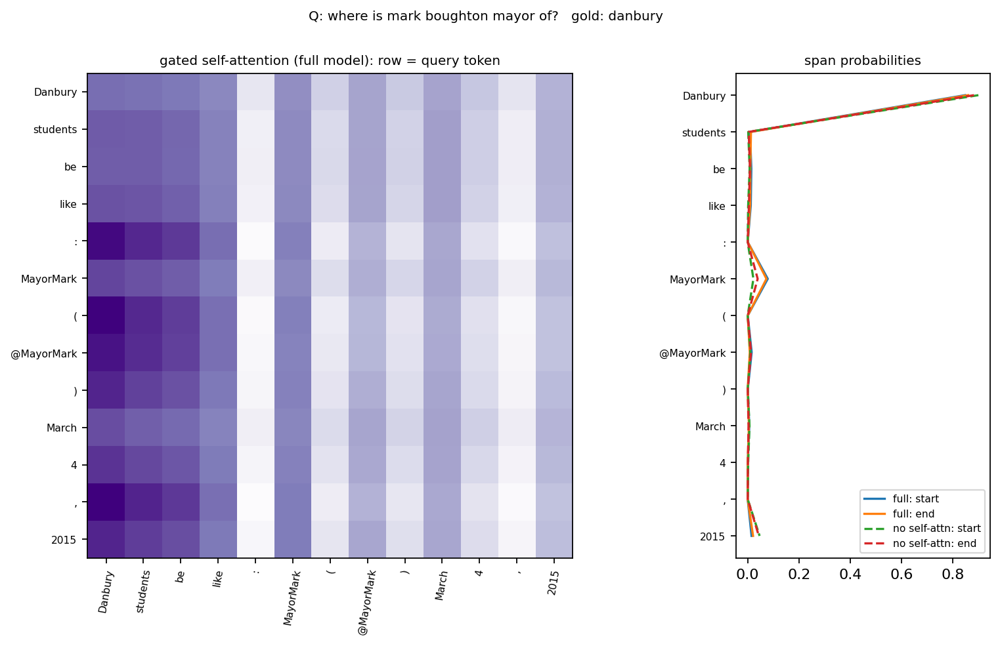

training_curves


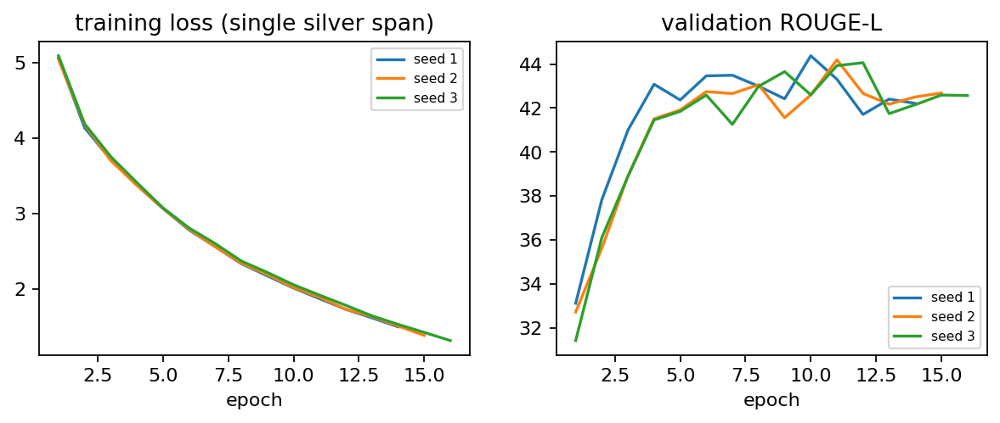

In [19]:
for name in ["self_attn_A3","training_curves"]:
    print(name);display(Image(filename=f"attention/results/figures/{name}.png",width=1000))

## 3.6 Error analysis and limitations

The 100-example validation error sample contains automatic pre-tags. These are **not manual human labels** and must not be described as such. Categories overlap conceptually; the tagging code assigns them in a fixed precedence. The sample concerns a single base model, not necessarily the final ensemble's failure distribution.

In [20]:
attention=json.loads(Path("attention/results/stage7_summary.json").read_text())
print("Analysis checkpoint:",attention["full_run"])
print("Errors (EM=0):",attention["n_errors"],"/ 1076 validation questions")
print("Automatic categories in the 100-error sample:",attention["auto_tags"])
error_rows=read_csv("attention/results/error_sample.csv")
assert len(error_rows)==100
for row in error_rows[:8]:
    print({k:v for k,v in row.items() if k in ["question","gold","pred","auto_tag","error_cause"]})
print("Question-type breakdown:")
for word,values in attention["qtype"].items():print(word,values)

Analysis checkpoint: A5_single_span-s1-20261014-071243
Errors (EM=0): 786 / 1076 validation questions
Automatic categories in the 100-error sample: {'wrong span (no overlap)': 26, 'boundary / partial overlap': 40, 'abstractive gold (no good span)': 23, 'byline vs body confusion': 11}
{'question': 'what did kallis end there?', 'gold': 'his illustrious career', 'pred': '1995 at Kingsmead', 'error_cause': '', 'auto_tag': 'wrong span (no overlap)'}
{'question': 'what is rihanna being praised for?', 'gold': 'showing what inclusive means to the makeup industry', 'pred': 'inclusive', 'error_cause': '', 'auto_tag': 'boundary / partial overlap'}
{'question': "what embassy changed it's picture to je suis charlie?", 'gold': 'france', 'pred': 'Twitter', 'error_cause': '', 'auto_tag': 'wrong span (no overlap)'}
{'question': 'who went with jimmy to a haunted house?', 'gold': 'kevin hart', 'pred': '@KevinHart4real', 'error_cause': '', 'auto_tag': 'abstractive gold (no good span)'}
{'question': 'at wh

The dominant automatic categories are partial-boundary errors and wrong spans, with further non-extractive and body/byline errors. Extractive decoding cannot freely paraphrase; rare names, ambiguous references and weak lexical matches remain difficult. Small “why” and other question-type slices should not drive model selection.

The pretrained baselines and main model differ in scale, prior data and adaptation strategy; their comparisons do not isolate architecture alone. B3–B5 have one original run, so their seed variability is not established. Repeated validation exploration can yield optimistic selection; the final test was reserved for reporting the frozen systems. The supplied train/test tweet overlap is an additional dataset limitation.

## 3.7 Optional fresh validation inference — disabled by default

This section uses the exact original checkpoint/reranker identities. Downloading or uploading weights is unnecessary for default Run all. It never performs fresh test prediction. If enabled, it must reproduce all 1,076 saved validation answer strings before its scores are accepted. No replacement reranker or new threshold search is permitted.

In [21]:
if RUN_VALIDATION_INFERENCE:
    import subprocess,urllib.request
    subprocess.check_call([sys.executable,"-m","pip","install","-q","lightgbm==4.6.0","scikit-learn==1.6.1","joblib==1.6.0"])
    import joblib
    PINNED="84b85d90a997cc98632dc06a822cd42a5c19ec17"
    archives={"a2_v2_colab_artifacts.zip":"6fc46dc5ef256426d8c4b95da2898483edba34687a62013bc2889cd59c9badd4",
              "oof_span_reranker_artifacts.zip":"83436c4eff8604c8ebed3f898fab5874e5e67972097743b13389e4fcd05e4c00"}
    for name,digest in archives.items():
        p=Path(name)
        if not p.exists():
            url=f"https://raw.githubusercontent.com/James-h95/A2/{PINNED}/{name}"
            try: urllib.request.urlretrieve(url,p)
            except Exception as error:
                print("Archive download failed; upload the original",name,"Error:",error)
                from google.colab import files
                up=files.upload();assert name in up;p.write_bytes(up[name])
        assert hashlib.sha256(p.read_bytes()).hexdigest()==digest,name
    members=["checkpoints/A5_single_span-s1-20261014-071243.pt","checkpoints/A5_single_span-s2-20261014-071828.pt","checkpoints/A5_single_span-s3-20261014-072428.pt"]
    with zipfile.ZipFile("a2_v2_colab_artifacts.zip") as z:
        for name in members:
            p=Path(name);p.parent.mkdir(parents=True,exist_ok=True);p.write_bytes(z.read(name))
    member="oof_reranker_results/oof_lambdamart_reranker.joblib"
    with zipfile.ZipFile("oof_span_reranker_artifacts.zip") as z:
        p=Path(member);p.parent.mkdir(parents=True,exist_ok=True);p.write_bytes(z.read(member))
    reranker=joblib.load(member);assert reranker.n_features_in_==30
    from src.selected_inference import predict_selected_system
    outputs,_=predict_selected_system(val_rows,[Path(p) for p in members],reranker,device="cuda" if torch.cuda.is_available() else "cpu")
    reference=json.loads(Path("evidence/01_validation/validation_predictions.json").read_text())
    ref={r["row_id"]:r["prediction"] for r in reference}
    assert len(outputs)==1076 and set(ref)=={r["row_id"] for r in outputs}
    assert all(r["prediction"]==ref[r["row_id"]] for r in outputs)
    print("PASS: fresh selected-model validation inference matches 1076/1076 reference answers")
else:
    print("Fresh model inference skipped; original successful Colab validation evidence is embedded above.")

Fresh model inference skipped; original successful Colab validation evidence is embedded above.


## 3.8 References and submission status

- Xiong et al. (2019), **TweetQA: A Social Media Focused Question Answering Dataset** — task/data motivation.
- Seo et al. (2017), **Bidirectional Attention Flow for Machine Comprehension** — BiDAF attention.
- Wang et al. (2017), **R-NET: Machine Reading Comprehension with Self-Matching Networks** — self-matching/gated-attention precedent.
- Nguyen et al. (2020), **BERTweet: A pre-trained language model for English Tweets** — B3.
- Raffel et al. (2020), **Exploring the Limits of Transfer Learning with a Unified Text-to-Text Transformer** — T5 baseline.
- Qwen2.5-1.5B-Instruct and LightGBM are identified by the saved run manifests and implementation.

The report should use complete BibTeX references and accurately distinguish these established components from task-specific adaptations.

**Before final upload:** resolve B3/B4 test status consistently with the report, verify the optional model-download route in Colab, and check every reported number against these saved outputs. This notebook is named for Group 5; the required report filename is `CITS4012_5.pdf`. Team contributions should describe completed work, not proposed tasks.

## Appendix — complete source implementation

The following cells contain the complete original modules and reproduction orchestration. They use `%%writefile` so relative imports remain correct. The same bytes were restored and hash-checked at the start; these cells only write those identical definitions again. They do not run their CLI entry points, train models, or execute experiments. Keeping the class implementations here follows the supplied template's request for OOP code at the bottom.

### src/__init__.py

In [22]:
%%writefile src/__init__.py
# package marker


Overwriting src/__init__.py


### src/analysis.py

In [23]:
%%writefile src/analysis.py
"""Analysis utilities: hypothesis slices, ablation tables, attention heatmaps, error sampling."""
import csv
import json
import math
import random
import statistics
from collections import defaultdict
from pathlib import Path

import torch

try:
    from . import data as D
    from .evaluate import METRICS, evaluate, normalize_answer, score_example
    from .runlog import RESULTS_DIR, read_runs
except ImportError:
    import data as D
    from evaluate import METRICS, evaluate, normalize_answer, score_example
    from runlog import RESULTS_DIR, read_runs

FIG_DIR = RESULTS_DIR / "figures"
TAB_DIR = RESULTS_DIR / "tables"
FAR_N = 8   # A3 slice: answer more than FAR_N tokens from the nearest question-word match


# ------------------------------------------------------------------ slices

def _answer_far_or_byline(ex):
    if ex["best"] is None:
        return False
    i, j = ex["best"]
    if i >= ex["byline_from"]:
        return True
    qwords = {w for t in ex["q_tokens"] for w in normalize_answer(t["raw"]).split()} - D._STOP
    anchors = [p for p, t in enumerate(ex["t_tokens"])
               if set(normalize_answer(t["raw"]).split()) & qwords and not (i <= p <= j)]
    if not anchors:
        return True
    return min(i - p if p < i else p - j for p in anchors) > FAR_N


def _answer_is_handle_or_tag(ex):
    if ex["best"] is None:
        return any(a.strip().startswith(("@", "#")) for a in ex["answers"])
    i, j = ex["best"]
    toks = ex["t_tokens"][i:j + 1]
    return (any(t["kind"] in ("mention", "hashtag") for t in toks) or i >= ex["byline_from"]
            or any(a.strip().startswith(("@", "#")) for a in ex["answers"]))


def slices(examples, wvocab):
    """row_id sets for the hypothesis-driven slices (validation examples)."""
    out = defaultdict(set)
    for ex in examples:
        rid = ex["row_id"]
        out["all"].add(rid)
        ans_words = {t["word"] for a in ex["answers"] for t in D.normalise_tokens(D.tokenize(a))}
        if any(wvocab(w) == 1 for w in ans_words if normalize_answer(w)):
            out["A1_answer_oov"].add(rid)
        if _answer_is_handle_or_tag(ex):
            out["A2_handle_tag_username"].add(rid)
        if _answer_far_or_byline(ex):
            out["A3_far_or_byline"].add(rid)
        if not any(a.lower().strip() in ex["tweet"].lower() for a in ex["answers"]):
            out["A5_not_substring"].add(rid)
    return dict(out)


def slice_scores(pred_file, examples, slice_sets, metric="rougeL"):
    preds = {p["row_id"]: p["pred"] for p in json.loads(Path(pred_file).read_text())}
    per = {ex["row_id"]: score_example(preds.get(ex["row_id"], ""), ex["answers"], (metric,))[metric]
           for ex in examples}
    return {name: 100 * sum(per[r] for r in ids) / max(1, len(ids)) for name, ids in slice_sets.items()}


# ------------------------------------------------------------------ tables

def mean_sd(xs):
    return (statistics.mean(xs), statistics.stdev(xs) if len(xs) > 1 else 0.0)


def runs_by_name(names, split="val"):
    groups = defaultdict(list)
    for r in read_runs():
        if r["model"] in names and r["split"] == split:
            groups[r["model"]].append(r)
    return groups


def latex_table(rows, caption, label, cols=METRICS, header=None):
    """rows: [(label, {metric: (mean, sd) or value})]"""
    header = header or ["BLEU-1", "METEOR", "ROUGE-L", "EM", "F1"]
    lines = [r"\begin{table}[t]", r"\centering\small", r"\begin{tabular}{l" + "c" * len(cols) + "}",
             r"\toprule", "Model & " + " & ".join(header) + r" \\", r"\midrule"]
    for name, vals in rows:
        if name == "---":
            lines.append(r"\midrule")
            continue
        cells = []
        for c in cols:
            v = vals.get(c)
            if v is None:
                cells.append("--")
            elif isinstance(v, tuple):
                cells.append(f"{v[0]:.1f}$\\pm${v[1]:.1f}")
            else:
                cells.append(f"{v:.1f}")
        lines.append(name + " & " + " & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{caption}}}", rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(lines)


# ------------------------------------------------------------------ figures

def _short(s, n=110):
    return s if len(s) <= n else s[:n - 1] + "…"


@torch.no_grad()
def attention_figure(model, ex, device, path, title_extra="", max_span_len=15):
    """Tweet x question similarity S and C2Q weights, plus Q2C and start/end probability strips."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    try:
        from .model import decode
    except ImportError:
        from model import decode
    model.eval()
    batch = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in D.collate([ex]).items()}
    o = model(batch, return_attn=True)
    (i, j), = decode(o["start_logits"], o["end_logits"], max_span_len)[0].tolist()
    pred = D.span_text(ex, i, j)
    t_lab = [t["raw"] for t in ex["t_tokens"]]
    q_lab = [t["raw"] for t in ex["q_tokens"]]
    c2q = o["c2q"][0].cpu().numpy()
    ps = torch.softmax(o["start_logits"][0], -1).cpu().numpy()
    pe = torch.softmax(o["end_logits"][0], -1).cpu().numpy()
    q2c = o["q2c"][0].cpu().numpy() if o["q2c"] is not None else None
    n_strips = 3 if q2c is not None else 2
    T = len(t_lab)
    fig = plt.figure(figsize=(max(8, 0.32 * T + 2), 3.2 + 0.28 * len(q_lab) + 0.35 * n_strips))
    gs = fig.add_gridspec(1 + n_strips, 1, height_ratios=[max(2, 0.28 * len(q_lab))] + [0.35] * n_strips, hspace=0.08)
    ax = fig.add_subplot(gs[0])
    ax.imshow(c2q.T, aspect="auto", cmap="Blues", vmin=0, vmax=1)
    ax.set_yticks(range(len(q_lab)), q_lab, fontsize=8)
    ax.set_xticks([])
    ax.set_ylabel("question (C2Q weights)", fontsize=8)
    strips = [("start", ps), ("end", pe)] + ([("Q2C", q2c)] if q2c is not None else [])
    for k, (name, v) in enumerate(strips):
        a = fig.add_subplot(gs[1 + k], sharex=ax)
        a.imshow(v[None, :T], aspect="auto", cmap="Oranges" if name != "Q2C" else "Greens", vmin=0)
        a.set_yticks([0], [name], fontsize=8)
        if k < len(strips) - 1:
            a.set_xticks([])
        else:
            a.set_xticks(range(T), t_lab, rotation=75, fontsize=7)
    for x in (i - 0.5, j + 0.5):
        ax.axvline(x, color="red", lw=1)
    gold = " | ".join(ex["answers"])
    ok = score_example(pred, ex["answers"], ("rougeL",))["rougeL"]
    fig.suptitle(f"Q: {_short(ex['question'])}\nTweet: {_short(ex['tweet'], 150)}\n"
                 f"gold: {gold}   pred: {pred}   (ROUGE-L {100*ok:.0f}) {title_extra}", fontsize=8, x=0.01, ha="left")
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(f"{path}.{ext}", bbox_inches="tight", dpi=160)
    plt.close(fig)
    return pred


@torch.no_grad()
def self_attention_figure(model_on, model_off, ex, device, path):
    """Self-attention map of the full model, beside the start/end distributions with and without A3."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    batch = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in D.collate([ex]).items()}
    model_on.eval(); model_off.eval()
    on = model_on(batch, return_attn=True)
    off = model_off(batch, return_attn=True)
    t_lab = [t["raw"] for t in ex["t_tokens"]]
    T = len(t_lab)
    sa = on["self_attn"][0].cpu().numpy()[:T, :T]
    fig, axes = plt.subplots(1, 2, figsize=(max(12, 0.5 * T), max(6, 0.3 * T)),
                             gridspec_kw=dict(width_ratios=[3, 1.2]))
    axes[0].imshow(sa, cmap="Purples")
    axes[0].set_xticks(range(T), t_lab, rotation=80, fontsize=7)
    axes[0].set_yticks(range(T), t_lab, fontsize=7)
    axes[0].set_title("gated self-attention (full model): row = query token", fontsize=9)
    for name, o, c in (("full: start", on, "C0"), ("full: end", on, "C1"), ("no self-attn: start", off, "C2"),
                       ("no self-attn: end", off, "C3")):
        key = "start_logits" if "start" in name else "end_logits"
        axes[1].plot(torch.softmax(o[key][0], -1).cpu().numpy()[:T], range(T), label=name, color=c,
                     ls="-" if "full" in name else "--")
    axes[1].invert_yaxis()
    axes[1].set_yticks(range(T), t_lab, fontsize=7)
    axes[1].legend(fontsize=7)
    axes[1].set_title("span probabilities", fontsize=9)
    fig.suptitle(f"Q: {ex['question']}   gold: {' | '.join(ex['answers'])}", fontsize=9)
    for ext in ("pdf", "png"):
        fig.savefig(f"{path}.{ext}", bbox_inches="tight", dpi=160)
    plt.close(fig)


# ------------------------------------------------------------------ errors

def export_error_sample(examples, pred_file, path, n=100, seed=4012):
    preds = {p["row_id"]: p["pred"] for p in json.loads(Path(pred_file).read_text())}
    errs = []
    for ex in examples:
        p = preds.get(ex["row_id"], "")
        s = score_example(p, ex["answers"], ("rougeL", "em"))
        if s["em"] < 1:
            errs.append((ex, p, s["rougeL"]))
    random.Random(seed).shuffle(errs)
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["row_id", "question", "tweet", "gold", "pred", "rougeL", "extractive_gold",
                     "question_type", "error_cause"])
        for ex, p, r in errs[:n]:
            w.writerow([ex["row_id"], ex["question"], ex["tweet"], " | ".join(ex["answers"]), p, f"{100*r:.0f}",
                        int(ex["trainable"]), D._question_word(ex["question"]), ""])
    return len(errs)


Overwriting src/analysis.py


### src/baselines/__init__.py

In [24]:
%%writefile src/baselines/__init__.py
# package marker


Overwriting src/baselines/__init__.py


### src/baselines/b1_lexical.py

In [25]:
%%writefile src/baselines/b1_lexical.py
"""B1: lexical sliding-window baseline (no learning).

For every candidate window of 1..max_len tokens that starts and ends on a
content token and contains no question content word, the score is:

  proximity = sum over tweet positions p matching a question content word
              of 1 / (1 + distance(p, window))
  + type_bonus if the window fits the expected answer type
    (who -> capitalised / @mention, when -> number / month,
     how many / how much -> number, where -> capitalised)
  - length_penalty * (window length - 1)

The two free parameters (max_len, length_penalty) are picked on the
*training* split. No learning is involved, so the validation split stays
clean for reporting.
"""
import re

try:
    from ..data import _STOP
    from ..evaluate import normalize_answer
except ImportError:
    from data import _STOP
    from evaluate import normalize_answer

_MONTHS = set("january february march april may june july august september october november december "
              "jan feb mar apr jun jul aug sep sept oct nov dec monday tuesday wednesday thursday friday "
              "saturday sunday today tonight yesterday tomorrow".split())


def _qtype(question):
    q = question.lower()
    if re.match(r"\s*(how many|how much|how old|how long)", q):
        return "num"
    first = (q.split() or [""])[0]
    return {"who": "who", "whose": "who", "who's": "who", "whom": "who",
            "when": "when", "where": "where"}.get(first, "other")


def _type_ok(qtype, toks):
    if qtype == "who" or qtype == "where":
        return all(t["raw"][:1].isupper() or t["kind"] == "mention" for t in toks)
    if qtype == "when":
        return any(t["kind"] == "number" or t["word"] in _MONTHS for t in toks)
    if qtype == "num":
        return any(t["kind"] == "number" or t["word"] in {"one", "two", "three", "four", "five", "six",
                                                          "seven", "eight", "nine", "ten"} for t in toks)
    return False


def b1_predict_one(ex, max_len=3, length_penalty=0.2, type_bonus=1.0):
    toks = ex["t_tokens"]
    qwords = {w for t in ex["q_tokens"] for w in normalize_answer(t["raw"]).split()} - _STOP
    tnorm = [set(normalize_answer(t["raw"]).split()) for t in toks]
    content = [bool(s) and not s <= _STOP for s in tnorm]
    anchors = [p for p, s in enumerate(tnorm) if s & qwords]
    qtype = _qtype(ex["question"])
    best, best_score = None, float("-inf")
    for i in range(len(toks)):
        if not content[i] or tnorm[i] & qwords:
            continue
        for j in range(i, min(len(toks), i + max_len)):
            if tnorm[j] & qwords:
                break
            if not content[j]:
                continue
            prox = sum(1.0 / (1 + (i - p if p < i else p - j)) for p in anchors)
            score = prox - length_penalty * (j - i)
            if _type_ok(qtype, toks[i:j + 1]):
                score += type_bonus
            if score > best_score:
                best, best_score = (i, j), score
    if best is None:
        return ""
    return ex["tweet"][toks[best[0]]["start"]:toks[best[1]]["end"]]


def b1_predict(examples, **kw):
    return [b1_predict_one(ex, **kw) for ex in examples]


Overwriting src/baselines/b1_lexical.py


### src/baselines/b3_extractive_ft.py

In [26]:
%%writefile src/baselines/b3_extractive_ft.py
"""B3: fine-tuned pretrained encoder (vinai/bertweet-base, fallback roberta-base)
with a span head, trained on the same silver spans as the main model.

Each of our word tokens is BPE-encoded separately. That keeps a subword -> word
map, so the predicted subword span maps back to our tokens and then to raw
tweet text through the same char offsets the main model uses. This works with
BERTweet's slow tokenizer, which has no offset mapping.

Input: <s> question </s></s> tweet </s>, truncated to max_len subwords
(the tweet is truncated first; this is rare at 128).
"""
import argparse
import json
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(ROOT))
from src import data as D  # noqa: E402
from src.evaluate import evaluate, fmt  # noqa: E402
from src.runlog import log_run  # noqa: E402
from src.train import get_device  # noqa: E402

B3_CFG = dict(model="vinai/bertweet-base", lr=3e-5, epochs=3, batch_size=16, max_len=128,
           warmup=0.1, weight_decay=0.01, max_answer_subwords=30)


def b3_word_piece(tok, t):
    raw = t["raw"]
    if t["kind"] == "mention":
        raw = "@USER" if "bertweet" in tok.name_or_path else raw
    elif t["kind"] == "url":
        raw = "HTTPURL" if "bertweet" in tok.name_or_path else raw
    ids = tok.encode(" " + raw if "roberta" in tok.name_or_path else raw, add_special_tokens=False)
    return ids or [tok.unk_token_id]


def b3_featurise(tok, ex, max_len):
    q_ids = [i for t in ex["q_tokens"] for i in b3_word_piece(tok, t)][:40]
    ids = [tok.cls_token_id] + q_ids + [tok.sep_token_id, tok.sep_token_id]
    word_of = [-1] * len(ids)
    budget = max_len - len(ids) - 1
    for w, t in enumerate(ex["t_tokens"]):
        p = b3_word_piece(tok, t)
        if len(p) > budget:
            break
        ids += p
        word_of += [w] * len(p)
        budget -= len(p)
    ids.append(tok.sep_token_id)
    word_of.append(-1)
    ys = ye = -1
    if ex["best"] is not None:
        i, j = ex["best"]
        if i in word_of and j in word_of:
            ys = word_of.index(i)
            ye = len(word_of) - 1 - word_of[::-1].index(j)
    return dict(ids=ids, word_of=word_of, ys=ys, ye=ye)


def b3_batches(feats, bs, shuffle, rng, pad_id):
    order = list(range(len(feats)))
    if shuffle:
        rng.shuffle(order)
    for k in range(0, len(order), bs):
        fs = [feats[i] for i in order[k:k + bs]]
        T = max(len(f["ids"]) for f in fs)
        ids = torch.full((len(fs), T), pad_id, dtype=torch.long)
        att = torch.zeros(len(fs), T, dtype=torch.long)
        ctx = torch.zeros(len(fs), T, dtype=torch.bool)
        for b, f in enumerate(fs):
            ids[b, :len(f["ids"])] = torch.tensor(f["ids"])
            att[b, :len(f["ids"])] = 1
            ctx[b, :len(f["ids"])] = torch.tensor([w >= 0 for w in f["word_of"]])
        yield order[k:k + bs], ids, att, ctx, torch.tensor([f["ys"] for f in fs]), torch.tensor([f["ye"] for f in fs])


class SpanModel(torch.nn.Module):
    def __init__(self, name):
        super().__init__()
        from transformers import AutoModel
        self.enc = AutoModel.from_pretrained(name)
        self.head = torch.nn.Linear(self.enc.config.hidden_size, 2)

    def forward(self, ids, att, ctx):
        h = self.enc(input_ids=ids, attention_mask=att).last_hidden_state
        s, e = self.head(h).unbind(-1)
        return s.masked_fill(~ctx, -1e4), e.masked_fill(~ctx, -1e4)


@torch.no_grad()
def b3_predict(model, exs, feats, device, cfg, pad_id):
    model.eval()
    preds = [""] * len(exs)
    for idx, ids, att, ctx, _, _ in b3_batches(feats, 64, False, None, pad_id):
        s, e = model(ids.to(device), att.to(device), ctx.to(device))
        ls, le = F.log_softmax(s, -1), F.log_softmax(e, -1)
        T = ls.size(1)
        sc = ls.unsqueeze(2) + le.unsqueeze(1)
        r = torch.arange(T, device=device)
        band = (r[None] >= r[:, None]) & (r[None] - r[:, None] < cfg["max_answer_subwords"])
        flat = sc.masked_fill(~band, -1e9).view(len(idx), -1).argmax(-1).tolist()
        for k, f in zip(idx, flat):
            i, j = feats[k]["word_of"][f // T], feats[k]["word_of"][f % T]
            if i >= 0 and j >= i:
                preds[k] = D.span_text(exs[k], i, j)
    return preds


def b3_run(cfg, seed=1, split="val", limit=None, log=print):
    from transformers import AutoTokenizer, get_linear_schedule_with_warmup
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    device = get_device()
    try:
        tok = AutoTokenizer.from_pretrained(cfg["model"], use_fast=False)
    except Exception as e:  # noqa: BLE001
        log(f"could not load {cfg['model']} ({e}); falling back to roberta-base")
        cfg = {**cfg, "model": "roberta-base"}
        tok = AutoTokenizer.from_pretrained(cfg["model"])
    train_rows, val_rows = D.get_splits()
    eval_rows = val_rows if split == "val" else D.load_test()
    if limit:
        train_rows, eval_rows = train_rows[:limit], eval_rows[:limit]
    tr, ev = D.preprocess(train_rows), D.preprocess(eval_rows)
    ftr = [b3_featurise(tok, e, cfg["max_len"]) for e in tr if e["trainable"]]
    ftr = [f for f in ftr if f["ys"] >= 0]
    fev = [b3_featurise(tok, e, cfg["max_len"]) for e in ev]
    model = SpanModel(cfg["model"]).to(device)
    nd = ["bias", "LayerNorm.weight", "norm"]
    groups = [dict(params=[p for n, p in model.named_parameters() if not any(x in n for x in nd)],
                   weight_decay=cfg["weight_decay"]),
              dict(params=[p for n, p in model.named_parameters() if any(x in n for x in nd)], weight_decay=0.0)]
    opt = torch.optim.AdamW(groups, lr=cfg["lr"])
    steps = cfg["epochs"] * ((len(ftr) + cfg["batch_size"] - 1) // cfg["batch_size"])
    sched = get_linear_schedule_with_warmup(opt, int(cfg["warmup"] * steps), steps)
    rng = random.Random(seed)
    log(f"B3 {cfg['model']} device={device} train_feats={len(ftr)} eval={len(fev)} steps={steps}")
    t0 = time.time()
    for ep in range(cfg["epochs"]):
        model.train()
        tot = n = 0
        for _, ids, att, ctx, ys, ye in b3_batches(ftr, cfg["batch_size"], True, rng, tok.pad_token_id):
            ids, att, ctx, ys, ye = (x.to(device) for x in (ids, att, ctx, ys, ye))
            s, e = model(ids, att, ctx)
            loss = F.cross_entropy(s, ys) + F.cross_entropy(e, ye)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            tot += loss.item() * len(ys); n += len(ys)
        preds = b3_predict(model, ev, fev, device, cfg, tok.pad_token_id)
        s = evaluate(preds, [e["answers"] for e in ev])
        log(f"B3 epoch {ep+1} loss={tot/n:.4f} {split} {fmt(s)} ({(time.time()-t0)/60:.1f} min)")
    return s, preds, time.time() - t0, cfg, ev


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--seed", type=int, default=1)
    ap.add_argument("--split", default="val")
    ap.add_argument("--smoke", action="store_true")
    ap.add_argument("--model", default=B3_CFG["model"])
    a = ap.parse_args()
    cfg = {**B3_CFG, "model": a.model}
    if a.smoke:
        cfg["epochs"] = 1
    s, preds, tt, cfg, ev = b3_run(cfg, a.seed, a.split, limit=200 if a.smoke else None,
                                log=lambda x: print(x, flush=True))
    if not a.smoke:
        rid = log_run("B3_" + cfg["model"].split("/")[-1], cfg, a.seed, a.split, s, tt,
                      notes="fine-tuned pretrained encoder + span head on silver spans (final epoch)")
        out = ROOT / "results" / "preds"
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{rid}.json").write_text(json.dumps([dict(qid=e["qid"], row_id=e["row_id"], pred=p)
                                                     for e, p in zip(ev, preds)]))
    print("DONE", fmt(s), flush=True)


Overwriting src/baselines/b3_extractive_ft.py


### src/baselines/b4_t5_ft.py

In [27]:
%%writefile src/baselines/b4_t5_ft.py
"""B4: fine-tuned generative seq2seq (t5-small; google/flan-t5-base optional).

Input "question: <q> context: <tweet>" -> the gold answer string. Unlike the
extractive models it can produce answers that are not in the tweet
(about 35% of TweetQA). Beam search 4, max 16 new tokens.
"""
import argparse
import json
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch

ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(ROOT))
from src import data as D  # noqa: E402
from src.evaluate import evaluate, fmt  # noqa: E402
from src.runlog import log_run  # noqa: E402
from src.train import get_device  # noqa: E402

B4_CFG = dict(model="t5-small", lr=3e-4, epochs=5, batch_size=16, max_src=160, max_tgt=24,
           beams=4, max_new_tokens=16, weight_decay=0.0)


def b4_src_text(r):
    return f"question: {r['question']} context: {r['tweet']}"


@torch.no_grad()
def b4_generate(model, tok, rows, device, cfg, bs=64):
    model.eval()
    out = []
    for k in range(0, len(rows), bs):
        enc = tok([b4_src_text(r) for r in rows[k:k + bs]], return_tensors="pt", padding=True,
                  truncation=True, max_length=cfg["max_src"]).to(device)
        gen = model.generate(**enc, num_beams=cfg["beams"], max_new_tokens=cfg["max_new_tokens"])
        out += tok.batch_decode(gen, skip_special_tokens=True)
    return [o.strip() for o in out]


def b4_run(cfg, seed=1, split="val", limit=None, log=print):
    from transformers import AutoModelForSeq2SeqLM, AutoTokenizer, get_linear_schedule_with_warmup
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    device = get_device()
    tok = AutoTokenizer.from_pretrained(cfg["model"])
    model = AutoModelForSeq2SeqLM.from_pretrained(cfg["model"]).to(device)
    train_rows, val_rows = D.get_splits()
    eval_rows = val_rows if split == "val" else D.load_test()
    if limit:
        train_rows, eval_rows = train_rows[:limit], eval_rows[:limit]
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps = cfg["epochs"] * ((len(train_rows) + cfg["batch_size"] - 1) // cfg["batch_size"])
    sched = get_linear_schedule_with_warmup(opt, 0, steps)
    rng = random.Random(seed)
    log(f"B4 {cfg['model']} device={device} train={len(train_rows)} eval={len(eval_rows)} steps={steps}")
    t0 = time.time()
    s, preds = None, None
    for ep in range(cfg["epochs"]):
        model.train()
        order = list(range(len(train_rows)))
        rng.shuffle(order)
        tot = n = 0
        for k in range(0, len(order), cfg["batch_size"]):
            rows = [train_rows[i] for i in order[k:k + cfg["batch_size"]]]
            enc = tok([b4_src_text(r) for r in rows], return_tensors="pt", padding=True, truncation=True,
                      max_length=cfg["max_src"]).to(device)
            lab = tok([r["answers"][0] for r in rows], return_tensors="pt", padding=True, truncation=True,
                      max_length=cfg["max_tgt"]).input_ids.to(device)
            lab[lab == tok.pad_token_id] = -100
            loss = model(**enc, labels=lab).loss
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            tot += loss.item() * len(rows); n += len(rows)
        preds = b4_generate(model, tok, eval_rows, device, cfg)
        s = evaluate(preds, [r["answers"] for r in eval_rows])
        log(f"B4 epoch {ep+1} loss={tot/n:.4f} {split} {fmt(s)} ({(time.time()-t0)/60:.1f} min)")
    return s, preds, time.time() - t0, eval_rows


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--seed", type=int, default=1)
    ap.add_argument("--split", default="val")
    ap.add_argument("--smoke", action="store_true")
    ap.add_argument("--model", default=B4_CFG["model"])
    ap.add_argument("--epochs", type=int, default=B4_CFG["epochs"])
    a = ap.parse_args()
    cfg = {**B4_CFG, "model": a.model, "epochs": 1 if a.smoke else a.epochs}
    s, preds, tt, rows = b4_run(cfg, a.seed, a.split, limit=200 if a.smoke else None,
                             log=lambda x: print(x, flush=True))
    if not a.smoke:
        rid = log_run("B4_" + cfg["model"].split("/")[-1], cfg, a.seed, a.split, s, tt,
                      notes="fine-tuned seq2seq, beam 4 (final epoch)")
        out = ROOT / "results" / "preds"
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{rid}.json").write_text(json.dumps([dict(qid=r["qid"], row_id=r["row_id"], pred=p)
                                                     for r, p in zip(rows, preds)]))
    print("DONE", fmt(s), flush=True)


Overwriting src/baselines/b4_t5_ft.py


### src/baselines/b5_llm.py

In [28]:
%%writefile src/baselines/b5_llm.py
"""B5: open instruct LLM (Qwen/Qwen2.5-1.5B-Instruct) with a fixed few-shot prompt,
greedy decoding, output stripped to a short answer. No fine-tuning.

The prompt is recorded verbatim in PROMPT_SYSTEM / the few-shot block below. The
few-shot examples are fixed training-split rows chosen by row id.
"""
import argparse
import json
import re
import sys
import time
from pathlib import Path

import torch

ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(ROOT))
from src import data as D  # noqa: E402
from src.evaluate import evaluate, fmt  # noqa: E402
from src.runlog import log_run  # noqa: E402
from src.train import get_device  # noqa: E402

B5_CFG = dict(model="Qwen/Qwen2.5-1.5B-Instruct", shots=4, max_new_tokens=16, batch_size=16)
PROMPT_SYSTEM = ("You answer questions about a tweet. Reply with only the short answer "
                 "(usually a few words copied from the tweet), with no explanation.")
SHOT_QWORDS = ("who", "what", "when", "how")   # one fixed train example per question type


def pick_shots(train_rows, k):
    shots = []
    for w in SHOT_QWORDS[:k]:
        for r in train_rows:        # first train row (fixed order) with this q-word and a short extractive answer
            a = r["answers"][0]
            if r["question"].lower().startswith(w) and a.lower() in r["tweet"].lower() and len(a.split()) <= 4:
                shots.append(r)
                break
    return shots


def b5_messages(r, shots):
    msgs = [dict(role="system", content=PROMPT_SYSTEM)]
    for s in shots:
        msgs.append(dict(role="user", content=f"Tweet: {s['tweet']}\nQuestion: {s['question']}"))
        msgs.append(dict(role="assistant", content=s["answers"][0]))
    msgs.append(dict(role="user", content=f"Tweet: {r['tweet']}\nQuestion: {r['question']}"))
    return msgs


def b5_clean(text):
    text = text.strip().split("\n")[0]
    text = re.sub(r"^(answer|a)\s*:\s*", "", text, flags=re.I)
    return text.strip().strip('"').rstrip(".")


def b5_run(cfg, split="val", limit=None, log=print):
    from transformers import AutoModelForCausalLM, AutoTokenizer
    torch.manual_seed(0)
    device = get_device()
    tok = AutoTokenizer.from_pretrained(cfg["model"], padding_side="left")
    model = AutoModelForCausalLM.from_pretrained(cfg["model"], dtype=torch.float16
                                                 if device != "cpu" else torch.float32).to(device).eval()
    train_rows, val_rows = D.get_splits()
    rows = val_rows if split == "val" else D.load_test()
    if limit:
        rows = rows[:limit]
    shots = pick_shots(train_rows, cfg["shots"])
    log(f"B5 {cfg['model']} device={device} eval={len(rows)} shots={[s['row_id'] for s in shots]}")
    log("PROMPT (verbatim, last user turn is the target):\n" + json.dumps(b5_messages(rows[0], shots), indent=1))
    t0 = time.time()
    preds = []
    for k in range(0, len(rows), cfg["batch_size"]):
        chunk = rows[k:k + cfg["batch_size"]]
        texts = [tok.apply_chat_template(b5_messages(r, shots), tokenize=False, add_generation_prompt=True)
                 for r in chunk]
        enc = tok(texts, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            gen = model.generate(**enc, do_sample=False, max_new_tokens=cfg["max_new_tokens"],
                                 pad_token_id=tok.eos_token_id)
        preds += [b5_clean(t) for t in tok.batch_decode(gen[:, enc.input_ids.shape[1]:], skip_special_tokens=True)]
        if k % (cfg["batch_size"] * 10) == 0:
            log(f"  {k + len(chunk)}/{len(rows)} ({(time.time()-t0)/60:.1f} min)")
    s = evaluate(preds, [r["answers"] for r in rows])
    return s, preds, time.time() - t0, rows, shots


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--split", default="val")
    ap.add_argument("--smoke", action="store_true")
    ap.add_argument("--model", default=B5_CFG["model"])
    ap.add_argument("--shots", type=int, default=B5_CFG["shots"])
    a = ap.parse_args()
    cfg = {**B5_CFG, "model": a.model, "shots": a.shots}
    s, preds, tt, rows, shots = b5_run(cfg, a.split, limit=32 if a.smoke else None, log=lambda x: print(x, flush=True))
    for r, p in list(zip(rows, preds))[:8]:
        print(f"  Q: {r['question']} | gold: {r['answers']} | pred: {p}")
    if not a.smoke:
        cfg = {**cfg, "prompt_system": PROMPT_SYSTEM, "shot_row_ids": [x["row_id"] for x in shots]}
        rid = log_run("B5_" + cfg["model"].split("/")[-1] + f"_{cfg['shots']}shot", cfg, 0, a.split, s, tt,
                      notes="few-shot instruct LLM, greedy, no fine-tuning")
        out = ROOT / "results" / "preds"
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{rid}.json").write_text(json.dumps([dict(qid=r["qid"], row_id=r["row_id"], pred=p)
                                                     for r, p in zip(rows, preds)]))
    print("DONE", fmt(s), flush=True)


Overwriting src/baselines/b5_llm.py


### src/data.py

In [29]:
%%writefile src/data.py
"""TweetQA data pipeline: loading, splits, offset-preserving tokenisation,
tweet normalisation, token flags, silver-span labelling, vocabularies and
a padded DataLoader.

Design notes (see results/DATA_REPORT.md):
- test.csv is the original TweetQA dev set. It stays locked (TEST_LOCKED)
  until the final evaluation. Validation is 10% of train, grouped by tweet.
- Every token keeps its character offsets into the raw tweet, so a
  predicted span (i, j) maps back to tweet[start_i:end_j].
- The normaliser only changes the *word* used for the embedding lookup.
  The char-CNN always sees the raw (lowercased) token, so @handles stay
  distinguishable after @user -> <user>.
"""
import ast
import csv
import os
import random
import re
from collections import Counter, defaultdict
from pathlib import Path

import torch
from torch.utils.data import DataLoader, Dataset

try:
    from .evaluate import normalize_answer, rouge_l
except ImportError:  # inlined in the notebook / run as a script
    from evaluate import normalize_answer, rouge_l

TEST_LOCKED = True
DATA_DIR = Path(os.environ.get("TWEETQA_DIR", Path(__file__).resolve().parents[1] / "data"
                               if "__file__" in globals() else "data"))
SPLIT_SEED = 4012
VAL_FRAC = 0.10

# ------------------------------------------------------------------ loading

_ANSWER_ITEM = re.compile(r"'(?:[^'\\]|\\.)*'|\"(?:[^\"\\]|\\.)*\"", re.S)


def parse_answers(field):
    """The Answer column is a numpy-array repr: ['a' 'b'] (space/newline separated, mixed quotes)."""
    items = [ast.literal_eval(m) for m in _ANSWER_ITEM.findall(field)]
    if not items:
        raise ValueError(f"unparseable answer field: {field!r}")
    return [str(a) for a in items]


def _read_csv(name):
    with open(Path(DATA_DIR) / name, encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    return [dict(row_id=i, qid=r["qid"], question=r["Question"], tweet=r["Tweet"],
                 answers=parse_answers(r["Answer"]), answer_field=r["Answer"])
            for i, r in enumerate(rows)]


def _question_word(q):
    toks = tokenize(q.lower())
    w = toks[0][0] if toks else ""
    return w if w in {"what", "who", "how", "where", "why", "which", "when"} else "other"


def get_splits(seed=SPLIT_SEED, val_frac=VAL_FRAC):
    """Train/val from train.csv: exact duplicates dropped, grouped by tweet,
    stratified by the first question word of each tweet's first question."""
    rows, seen = [], set()
    for r in _read_csv("train.csv"):
        key = (r["question"], r["answer_field"], r["tweet"])
        if key not in seen:
            seen.add(key)
            rows.append(r)
    by_tweet = defaultdict(list)
    for r in rows:
        by_tweet[r["tweet"]].append(r)
    strata = defaultdict(list)
    for tweet in sorted(by_tweet):
        strata[_question_word(by_tweet[tweet][0]["question"])].append(tweet)
    rng = random.Random(seed)
    val_tweets = set()
    for s in sorted(strata):
        tweets = strata[s][:]
        rng.shuffle(tweets)
        val_tweets.update(tweets[:round(len(tweets) * val_frac)])
    train = [r for r in rows if r["tweet"] not in val_tweets]
    val = [r for r in rows if r["tweet"] in val_tweets]
    return train, val


def load_test():
    if TEST_LOCKED:
        raise RuntimeError("Test set is locked (TEST_LOCKED=True). It is used once, in Stage 8.")
    return _read_csv("test.csv")


# ------------------------------------------------------------- tokenisation

_URL = r"https?://\S+|www\.\S+"
_EMOJI_CHARS = "\U0001F000-\U0001FAFF☀-➿⬀-⯿️‍"
_TOKEN_RE = re.compile(
    rf"(?P<url>{_URL})"
    r"|(?P<mention>@\w+)"
    r"|(?P<hashtag>#\w+)"
    rf"|(?P<emoji>[{_EMOJI_CHARS}]+)"
    r"|(?P<number>\d+(?:[.,:/]\d+)*)"
    r"|(?P<word>\w+(?:['’]\w+)*)"
    r"|(?P<sym>[^\w\s])",
    re.UNICODE,
)
_ELONG = re.compile(r"(.)\1{2,}")


def tokenize(text):
    """Returns [(raw_token, start, end, kind)] with char offsets into text."""
    return [(m.group(0), m.start(), m.end(), m.lastgroup) for m in _TOKEN_RE.finditer(text)]


def normalise_tokens(raw_tokens, use_normaliser=True):
    """Map raw tokens to model tokens: dicts with word, raw, start, end, kind.

    Normaliser: @user -> <user>, url -> <url>, emoji -> <emoji>,
    #tag -> '#' + 'tag', elongation squashed to 2 repeats, lowercase.
    With use_normaliser=False the word is just the lowercased raw token.
    """
    out = []
    for raw, s, e, kind in raw_tokens:
        if not use_normaliser:
            out.append(dict(word=raw.lower(), raw=raw, start=s, end=e, kind=kind))
        elif kind == "mention":
            out.append(dict(word="<user>", raw=raw, start=s, end=e, kind=kind))
        elif kind == "url":
            out.append(dict(word="<url>", raw=raw, start=s, end=e, kind=kind))
        elif kind == "emoji":
            out.append(dict(word="<emoji>", raw=raw, start=s, end=e, kind=kind))
        elif kind == "hashtag":
            out.append(dict(word="#", raw="#", start=s, end=s + 1, kind=kind))
            tag = raw[1:]
            out.append(dict(word=_ELONG.sub(r"\1\1", tag.lower()), raw=tag, start=s + 1, end=e, kind=kind))
        else:
            out.append(dict(word=_ELONG.sub(r"\1\1", raw.lower()), raw=raw, start=s, end=e, kind=kind))
    return out


_BYLINE_RE = re.compile(r"\(@\w+\)\s+[A-Za-z]+\.?\s+\d{1,2},\s+\d{4}\s*$")
_BOUNDARY = {".", "!", "?", "—", "–", "-", "\"", "”", "|", ":"}


def byline_start(text, tokens):
    """Index of the first token of the trailing 'Name (@handle) Month D, YYYY'
    byline, or len(tokens) if there is none. The name is taken back to the
    previous sentence boundary, at most 6 tokens."""
    m = _BYLINE_RE.search(text)
    if not m:
        return len(tokens)
    k = next((i for i, t in enumerate(tokens) if t["start"] >= m.start()), len(tokens))
    j = k
    while j > 0 and k - j < 6 and tokens[j - 1]["raw"] not in _BOUNDARY:
        j -= 1
    return j


FLAG_NAMES = ("mention", "hashtag", "url", "emoji", "number", "capitalised", "in_byline", "in_other_seq")


def token_flags(tokens, other_words, byline_from=None):
    by = len(tokens) if byline_from is None else byline_from
    flags = []
    for i, t in enumerate(tokens):
        flags.append([
            float(t["kind"] == "mention"), float(t["kind"] == "hashtag"), float(t["kind"] == "url"),
            float(t["kind"] == "emoji"), float(t["kind"] == "number"),
            float(t["raw"][:1].isupper()), float(i >= by),
            float(t["word"] in other_words and t["word"] not in _STOP),
        ])
    return flags


_STOP = set("""a an the of to in on at for by with from and or but is are was were be been being am
do does did has have had i you he she it we they me him her us them my your his its our their this that
these those what who whom whose which when where why how not no yes so if than then there here as just
about into out up down over can will would should could may might must 's ? . , ! ' " - — : ; ( )""".split())


# ------------------------------------------------------------- silver spans

def _norm_toks(raw):
    return normalize_answer(raw).split()


def silver_spans(tokens, tweet, answers, max_len=15, tau=0.5):
    """Score every span (i, j), j - i < max_len, that starts and ends on a
    content token, by token-F1 against each gold answer (max over golds).

    Returns (best, best_f1, soft):
      best  : (i, j) with the highest F1, ties broken by ROUGE-L then length
      soft  : [(i, j, w)] for all spans with F1 >= tau, weights proportional to F1
    """
    ntok = [_norm_toks(t["raw"]) for t in tokens]
    content = [bool(x) for x in ntok]
    golds = [Counter(_norm_toks(a)) for a in answers]
    glens = [sum(g.values()) for g in golds]
    scored = []
    for i in range(len(tokens)):
        if not content[i]:
            continue
        bag, n = Counter(), 0
        for j in range(i, min(len(tokens), i + max_len)):
            bag.update(ntok[j])
            n += len(ntok[j])
            if not content[j]:
                continue
            f = 0.0
            for g, gl in zip(golds, glens):
                if gl == 0:
                    continue
                ov = sum((bag & g).values())
                if ov:
                    p, r = ov / n, ov / gl
                    f = max(f, 2 * p * r / (p + r))
            if f > 0:
                scored.append((f, i, j))
    if not scored:
        return None, 0.0, []
    top = max(f for f, _, _ in scored)
    ties = [(i, j) for f, i, j in scored if f == top]
    if len(ties) > 1:
        def key(ij):
            txt = tweet[tokens[ij[0]]["start"]:tokens[ij[1]]["end"]]
            return (max(rouge_l(txt, a) for a in answers), -(ij[1] - ij[0]), -ij[0])
        ties.sort(key=key, reverse=True)
    soft = [(i, j, f) for f, i, j in scored if f >= tau]
    z = sum(w for _, _, w in soft)
    soft = [(i, j, w / z) for i, j, w in soft]
    return ties[0], top, soft


def span_text(ex, i, j):
    return ex["tweet"][ex["t_tokens"][i]["start"]:ex["t_tokens"][j]["end"]]


# ------------------------------------------------------------------- vocab

class Vocab:
    PAD, UNK = "<pad>", "<unk>"

    def __init__(self, counter, min_freq=2, specials=()):
        self.itos = [self.PAD, self.UNK] + [s for s in specials if s not in (self.PAD, self.UNK)]
        self.itos += sorted([w for w, c in counter.items() if c >= min_freq and w not in self.itos],
                            key=lambda w: (-counter[w], w))
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def __call__(self, w):
        return self.stoi.get(w, 1)


SPECIALS = ("<user>", "<url>", "<emoji>")
MAX_WORD_CHARS = 16


def build_vocabs(examples, min_freq=2, char_min_freq=5):
    """Vocabularies come from the training split only."""
    wc, cc = Counter(), Counter()
    for ex in examples:
        for t in ex["t_tokens"] + ex["q_tokens"]:
            wc[t["word"]] += 1
            cc.update(t["raw"].lower()[:MAX_WORD_CHARS])
    return Vocab(wc, min_freq, SPECIALS), Vocab(cc, char_min_freq)


# ----------------------------------------------------------------- encoding

# tau: an example is trainable if its best silver span has F1 >= tau.
# soft_tau: minimum F1 for a span to join the soft target set (None = same as tau). Kept separate so the
# soft-set width can be varied without changing which examples are trained on.
DEFAULT_PREP = dict(use_normaliser=True, max_span_len=15, tau=0.5, soft_tau=None)


def preprocess(rows, prep=None):
    """Tokenise, normalise, flag and silver-label raw rows."""
    prep = {**DEFAULT_PREP, **(prep or {})}
    out = []
    for r in rows:
        t_tokens = normalise_tokens(tokenize(r["tweet"]), prep["use_normaliser"])
        q_tokens = normalise_tokens(tokenize(r["question"]), prep["use_normaliser"])
        by = byline_start(r["tweet"], t_tokens)
        t_words = {t["word"] for t in t_tokens}
        q_words = {t["word"] for t in q_tokens}
        soft_tau = prep["tau"] if prep.get("soft_tau") is None else prep["soft_tau"]
        best, best_f1, soft = silver_spans(t_tokens, r["tweet"], r["answers"], prep["max_span_len"], soft_tau)
        out.append(dict(
            r, t_tokens=t_tokens, q_tokens=q_tokens, byline_from=by,
            t_flags=token_flags(t_tokens, q_words, by), q_flags=token_flags(q_tokens, t_words),
            best=best, best_f1=best_f1, soft=soft,
            trainable=best is not None and best_f1 >= prep["tau"],
        ))
    return out


def encode(examples, wvocab, cvocab):
    for ex in examples:
        for side in ("t", "q"):
            toks = ex[f"{side}_tokens"]
            ex[f"{side}_ids"] = [wvocab(t["word"]) for t in toks]
            ex[f"{side}_chars"] = [[cvocab(c) for c in t["raw"].lower()[:MAX_WORD_CHARS]] or [1] for t in toks]
    return examples


class QADataset(Dataset):
    def __init__(self, examples, train=False):
        # during training, only examples with a usable silver span contribute to the loss
        self.examples = [e for e in examples if e["trainable"]] if train else list(examples)

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, i):
        return self.examples[i]


def _pad_side(batch, side, n_flags):
    B = len(batch)
    T = max(1, max(len(ex[f"{side}_ids"]) for ex in batch))
    W = max(1, max((len(c) for ex in batch for c in ex[f"{side}_chars"]), default=1))
    words = torch.zeros(B, T, dtype=torch.long)
    chars = torch.zeros(B, T, W, dtype=torch.long)
    flags = torch.zeros(B, T, n_flags)
    mask = torch.zeros(B, T, dtype=torch.bool)
    for b, ex in enumerate(batch):
        n = len(ex[f"{side}_ids"])
        words[b, :n] = torch.tensor(ex[f"{side}_ids"], dtype=torch.long)
        for k, cs in enumerate(ex[f"{side}_chars"]):
            chars[b, k, :len(cs)] = torch.tensor(cs, dtype=torch.long)
        if n:
            flags[b, :n] = torch.tensor(ex[f"{side}_flags"])
        mask[b, :n] = True
    return words, chars, flags, mask


def collate(batch):
    tw, tc, tf, tm = _pad_side(batch, "t", len(FLAG_NAMES))
    qw, qc, qf, qm = _pad_side(batch, "q", len(FLAG_NAMES))
    B, T = tw.shape
    y_start = torch.full((B,), -1, dtype=torch.long)
    y_end = torch.full((B,), -1, dtype=torch.long)
    soft_start = torch.zeros(B, T)
    soft_end = torch.zeros(B, T)
    for b, ex in enumerate(batch):
        if ex["best"] is not None:
            y_start[b], y_end[b] = ex["best"]
        for i, j, w in ex["soft"]:
            soft_start[b, i] += w
            soft_end[b, j] += w
    return dict(t_words=tw, t_chars=tc, t_flags=tf, t_mask=tm,
                q_words=qw, q_chars=qc, q_flags=qf, q_mask=qm,
                y_start=y_start, y_end=y_end, soft_start=soft_start, soft_end=soft_end,
                best_f1=torch.tensor([ex["best_f1"] for ex in batch], dtype=torch.float),
                meta=batch)


def make_loader(examples, batch_size=32, train=False, seed=0):
    ds = QADataset(examples, train=train)
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(ds, batch_size=batch_size, shuffle=train, collate_fn=collate, generator=g)


# ------------------------------------------------------------------ oracle

def oracle_predictions(examples):
    """Best silver span text for every example ('' if there is no overlapping span)."""
    return [span_text(ex, *ex["best"]) if ex["best"] is not None else "" for ex in examples]


Overwriting src/data.py


### src/evaluate.py

In [30]:
%%writefile src/evaluate.py
"""Evaluation metrics for TweetQA.

Every metric is computed per example as the max over the gold answers,
and corpus scores are the mean x 100.

- BLEU-1: nltk sentence_bleu, weights (1,0,0,0), smoothing method1
- METEOR: nltk meteor_score (needs WordNet)
- ROUGE-L: our own LCS implementation, F-measure with beta = 1.2 (the
  coco-caption convention used by the official TweetQA evaluation)
- EM and token-F1: SQuAD-style, computed on normalised text
"""
import re
import string
import unicodedata
from collections import Counter

METRICS = ("bleu1", "meteor", "rougeL", "em", "f1")
_ARTICLES = re.compile(r"\b(a|an|the)\b")
_nltk_ready = False


def _ensure_nltk():
    global _nltk_ready
    if _nltk_ready:
        return
    import nltk
    for pkg, path in [("wordnet", "corpora/wordnet"), ("omw-1.4", "corpora/omw-1.4")]:
        try:
            nltk.data.find(path)
        except LookupError:
            nltk.download(pkg, quiet=True)
    _nltk_ready = True


def normalize_answer(s):
    """Lowercase, replace ASCII and Unicode punctuation with spaces,
    drop articles, collapse whitespace."""
    s = s.lower()
    s = "".join(" " if (ch in string.punctuation or unicodedata.category(ch).startswith("P")) else ch
                for ch in s)
    s = _ARTICLES.sub(" ", s)
    return " ".join(s.split())


def norm_tokens(s):
    return normalize_answer(s).split()


# ---------------------------------------------------------------- metrics

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))


def token_f1(pred, gold):
    p, g = norm_tokens(pred), norm_tokens(gold)
    if not p or not g:
        return float(p == g)
    common = Counter(p) & Counter(g)
    overlap = sum(common.values())
    if overlap == 0:
        return 0.0
    prec, rec = overlap / len(p), overlap / len(g)
    return 2 * prec * rec / (prec + rec)


def lcs_len(a, b):
    """Length of the longest common subsequence of two token lists (O(len(a)*len(b)) DP)."""
    if not a or not b:
        return 0
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0] * (len(b) + 1)
        for j, y in enumerate(b, 1):
            cur[j] = prev[j - 1] + 1 if x == y else max(prev[j], cur[j - 1])
        prev = cur
    return prev[-1]


def rouge_l(pred, gold, beta=1.2):
    p, g = norm_tokens(pred), norm_tokens(gold)
    if not p or not g:
        return float(p == g and bool(p))
    lcs = lcs_len(p, g)
    if lcs == 0:
        return 0.0
    prec, rec = lcs / len(p), lcs / len(g)
    return (1 + beta ** 2) * prec * rec / (rec + beta ** 2 * prec)


def bleu1(pred, gold):
    from nltk.translate.bleu_score import SmoothingFunction, sentence_bleu
    p, g = norm_tokens(pred), norm_tokens(gold)
    if not p or not g:
        return 0.0
    return sentence_bleu([g], p, weights=(1, 0, 0, 0),
                         smoothing_function=SmoothingFunction().method1)


def meteor(pred, gold):
    _ensure_nltk()
    from nltk.translate.meteor_score import meteor_score
    p, g = norm_tokens(pred), norm_tokens(gold)
    if not p or not g:
        return 0.0
    return meteor_score([g], p)


_FUNCS = {"bleu1": bleu1, "meteor": meteor, "rougeL": rouge_l, "em": exact_match, "f1": token_f1}


def score_example(pred, golds, metrics=METRICS):
    """Per-example scores in [0, 1]: max over gold answers."""
    pred = pred or ""
    return {m: max(_FUNCS[m](pred, g) for g in golds) for m in metrics}


def evaluate(preds, golds_list, metrics=METRICS, return_per_example=False):
    """preds: list[str]; golds_list: list[list[str]]. Returns corpus scores (mean x 100)."""
    assert len(preds) == len(golds_list), (len(preds), len(golds_list))
    per = [score_example(p, g, metrics) for p, g in zip(preds, golds_list)]
    n = max(1, len(per))
    corpus = {m: 100.0 * sum(s[m] for s in per) / n for m in metrics}
    return (corpus, per) if return_per_example else corpus


def fmt(scores):
    return " ".join(f"{m}={scores[m]:.2f}" for m in METRICS if m in scores)


Overwriting src/evaluate.py


### src/fasttext_init.py

In [31]:
%%writefile src/fasttext_init.py
"""Optional in-domain word vectors: FastText (gensim) trained from scratch on the
*training split's* tweets and questions only. No external text and no
pretrained weights, so the main model is still trained from scratch on
TweetQA alone."""
import torch


def fasttext_vectors(wv, cfg, train_examples, epochs=20, seed=1):
    from gensim.models import FastText
    sents, seen = [], set()
    for ex in train_examples:
        if ex["tweet"] not in seen:                 # each tweet once
            seen.add(ex["tweet"])
            sents.append([t["word"] for t in ex["t_tokens"]])
        sents.append([t["word"] for t in ex["q_tokens"]])
    ft = FastText(vector_size=cfg["word_dim"], window=5, min_count=1, sg=1, epochs=epochs,
                  seed=seed, workers=1, min_n=3, max_n=5)
    ft.build_vocab(sents)
    ft.train(sents, total_examples=len(sents), epochs=epochs)
    W = torch.randn(len(wv), cfg["word_dim"]) * 0.1
    W[0] = 0.0
    for i, w in enumerate(wv.itos[2:], start=2):
        W[i] = torch.tensor(ft.wv[w])               # subword n-grams also give OOV-safe vectors
    return W


Overwriting src/fasttext_init.py


### src/generative.py

In [32]:
%%writefile src/generative.py
"""Small pointer-generator for TweetQA, trained from scratch on the provided data."""
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F

from . import data as D
from .model import BiLSTM, CharCNN, GatedSelfAttention, Highway, NEG

GEN_SPECIALS = ("<pad>", "<unk>", "<bos>", "<eos>")


class GenVocab:
    def __init__(self, tokens, min_freq=2):
        counts = Counter(tokens)
        self.itos = list(GEN_SPECIALS) + sorted(w for w, n in counts.items()
                                                 if n >= min_freq and w not in GEN_SPECIALS)
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def id(self, token):
        return self.stoi.get(token, 1)


def raw_answer_tokens(text):
    return [raw.lower() for raw, _, _, _ in D.tokenize(text)]


def build_gen_vocab(train_rows, min_freq=2):
    return GenVocab((t for r in train_rows for a in r["answers"] for t in raw_answer_tokens(a)), min_freq)


def add_generation_fields(examples, gv, max_answer_len=16):
    """Add per-example extended-vocabulary copy ids and decoder targets."""
    V = len(gv)
    for ex in examples:
        source = [t["raw"].lower() for t in ex["t_tokens"]]
        oovs, oov_to_i = [], {}
        copy_ids = []
        for token in source:
            if token in gv.stoi:
                copy_ids.append(gv.stoi[token])
            else:
                if token not in oov_to_i:
                    oov_to_i[token] = len(oovs); oovs.append(token)
                copy_ids.append(V + oov_to_i[token])
        target_tokens = raw_answer_tokens(ex["answers"][0])[:max_answer_len - 1]
        target_ext = [gv.stoi[t] if t in gv.stoi else V + oov_to_i[t] if t in oov_to_i else 1
                      for t in target_tokens] + [3]
        decoder_in = [2] + [i if i < V else 1 for i in target_ext[:-1]]
        ex.update(copy_ids=copy_ids, source_oovs=oovs, target_tokens=target_tokens,
                  target_ext=target_ext, decoder_in=decoder_in)
    return examples


def collate_generation(examples):
    batch = D.collate(examples)
    B, T = batch["t_words"].shape
    L = max(len(e["target_ext"]) for e in examples)
    copy_ids = torch.zeros(B, T, dtype=torch.long)
    decoder_in = torch.zeros(B, L, dtype=torch.long)
    target_ext = torch.zeros(B, L, dtype=torch.long)
    target_mask = torch.zeros(B, L, dtype=torch.bool)
    for b, e in enumerate(examples):
        copy_ids[b, :len(e["copy_ids"])] = torch.tensor(e["copy_ids"])
        n = len(e["target_ext"])
        decoder_in[b, :n] = torch.tensor(e["decoder_in"])
        target_ext[b, :n] = torch.tensor(e["target_ext"])
        target_mask[b, :n] = True
    batch.update(copy_ids=copy_ids, decoder_in=decoder_in, target_ext=target_ext,
                 target_mask=target_mask,
                 max_oov=max((len(e["source_oovs"]) for e in examples), default=0))
    return batch


class TweetPointerGenerator(nn.Module):
    def __init__(self, n_words, n_chars, gen_vocab_size, cfg, word_vectors=None):
        super().__init__()
        self.cfg, self.gen_vocab_size = cfg, gen_vocab_size
        H, p = cfg["hidden"], cfg["dropout"]
        self.word_emb = nn.Embedding(n_words, cfg["word_dim"], padding_idx=0)
        if word_vectors is not None:
            self.word_emb.weight.data.copy_(word_vectors)
        emb_dim = cfg["word_dim"]
        self.char_cnn = CharCNN(n_chars, cfg["char_dim"], cfg["char_filters"], cfg["char_widths"])
        emb_dim += self.char_cnn.out_dim
        if cfg["use_token_flags"]: emb_dim += cfg["n_flags"]
        self.highway = Highway(emb_dim, 2)
        self.drop = nn.Dropout(p)
        self.encoder = BiLSTM(emb_dim, H)
        self.w_sim = nn.Linear(6 * H, 1)
        self.g_proj = nn.Linear(8 * H, 2 * H)
        self.self_attn = GatedSelfAttention(2 * H, cfg["attn_heads"], p)

        dim = 2 * H
        self.dec_emb = nn.Embedding(gen_vocab_size, cfg.get("decoder_emb", 100), padding_idx=0)
        self.attn_mem = nn.Linear(dim, dim, bias=False)
        self.attn_dec = nn.Linear(dim, dim, bias=False)
        self.attn_v = nn.Linear(dim, 1, bias=False)
        self.decoder = nn.GRUCell(cfg.get("decoder_emb", 100) + dim, dim)
        self.vocab_out = nn.Linear(2 * dim, gen_vocab_size)
        self.p_gen = nn.Linear(2 * dim + cfg.get("decoder_emb", 100), 1)

    def embed(self, words, chars, flags):
        parts = [self.word_emb(words), self.char_cnn(chars)]
        if self.cfg["use_token_flags"]: parts.append(flags)
        return self.highway(self.drop(torch.cat(parts, -1)))

    def encode(self, batch):
        tm, qm = batch["t_mask"], batch["q_mask"]
        h = self.drop(self.encoder(self.embed(batch["t_words"], batch["t_chars"], batch["t_flags"]), tm))
        u = self.drop(self.encoder(self.embed(batch["q_words"], batch["q_chars"], batch["q_flags"]), qm))
        d = h.size(-1); w = self.w_sim.weight.squeeze(0)
        S = ((h @ w[:d]).unsqueeze(2) + (u @ w[d:2*d]).unsqueeze(1)
             + (h * w[2*d:]) @ u.transpose(1, 2) + self.w_sim.bias)
        a = F.softmax(S.masked_fill(~qm.unsqueeze(1), NEG), -1); c2q = a @ u
        smax = S.masked_fill(~qm.unsqueeze(1), NEG).max(-1).values
        b = F.softmax(smax.masked_fill(~tm, NEG), -1)
        q2c = (b.unsqueeze(1) @ h).expand_as(h)
        memory = self.drop(F.relu(self.g_proj(torch.cat([h, c2q, h*c2q, h*q2c], -1))))
        memory, _ = self.self_attn(memory, tm)
        return memory

    def attend(self, memory, mask, hidden):
        score = self.attn_v(torch.tanh(self.attn_mem(memory) + self.attn_dec(hidden).unsqueeze(1))).squeeze(-1)
        attn = F.softmax(score.masked_fill(~mask, NEG), -1)
        context = torch.bmm(attn.unsqueeze(1), memory).squeeze(1)
        return context, attn

    def step(self, prev_ids, hidden, memory, mask, copy_ids, max_oov):
        prev_base = prev_ids.masked_fill(prev_ids >= self.gen_vocab_size, 1)
        emb = self.dec_emb(prev_base)
        context, _ = self.attend(memory, mask, hidden)
        hidden = self.decoder(torch.cat([emb, context], -1), hidden)
        context, attn = self.attend(memory, mask, hidden)
        vocab = F.softmax(self.vocab_out(torch.cat([hidden, context], -1)), -1)
        p = torch.sigmoid(self.p_gen(torch.cat([hidden, context, emb], -1)))
        final = vocab.new_zeros(vocab.size(0), self.gen_vocab_size + max_oov)
        final[:, :self.gen_vocab_size] = p * vocab
        final.scatter_add_(1, copy_ids, (1 - p) * attn)
        return final, hidden, attn, p

    def forward(self, batch):
        memory = self.encode(batch); mask = batch["t_mask"]
        hidden = (memory * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True).clamp_min(1)
        distributions = []
        for t in range(batch["decoder_in"].size(1)):
            dist, hidden, _, _ = self.step(batch["decoder_in"][:, t], hidden, memory, mask,
                                           batch["copy_ids"], batch["max_oov"])
            distributions.append(dist)
        return torch.stack(distributions, 1)

    @torch.no_grad()
    def generate(self, batch, max_len=16):
        memory = self.encode(batch); mask = batch["t_mask"]
        hidden = (memory * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True).clamp_min(1)
        prev = torch.full((memory.size(0),), 2, dtype=torch.long, device=memory.device)
        outputs, finished = [], torch.zeros(memory.size(0), dtype=torch.bool, device=memory.device)
        for _ in range(max_len):
            dist, hidden, _, _ = self.step(prev, hidden, memory, mask, batch["copy_ids"], batch["max_oov"])
            prev = dist.argmax(-1); outputs.append(prev)
            finished |= prev.eq(3)
            if finished.all(): break
        return torch.stack(outputs, 1)


def generation_loss(distributions, targets, mask):
    prob = distributions.gather(2, targets.unsqueeze(-1)).squeeze(-1).clamp_min(1e-12)
    return -(prob.log() * mask).sum() / mask.sum().clamp_min(1)


Overwriting src/generative.py


### src/model.py

In [33]:
%%writefile src/model.py
"""TweetBiDAF: an extractive QA model for tweets, trained from scratch.

  1. Embedding: word embedding ⊕ char-CNN over the *raw* token ⊕ token flags
     -> 2-layer highway                                    (A1: use_char_cnn, A2: use_token_flags)
  2. Shared BiLSTM contextual encoder for tweet (H) and question (U)
  3. Trilinear similarity S_ij = w^T [h_i; u_j; h_i ∘ u_j]
     C2Q = softmax_j(S) U,  Q2C = softmax_i(max_j S) H
     G = [h; c2q; h ∘ c2q; h ∘ q2c]                        (A4: biattn_mode "c2q" drops Q2C)
  4. Configurable multi-head self-attention over the projected G,
     residual + LayerNorm                                   (A3: use_self_attn)
  5. 2-layer modelling BiLSTM, start head, 1 more BiLSTM layer, end head,
     padding masks, best (i, j) with i <= j < i + L

The design follows BiDAF (Seo et al., 2017) with gated self-attention in the
style of R-Net (Wang et al., 2017). The tweet-specific parts are written for
this project: a char-CNN on raw tokens with a normalised word vocabulary,
token flags (including the byline flag), soft silver-span training, and
self-attention for long-range links between the tweet body and its byline.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

NEG = -1e30

DEFAULT_MODEL = dict(
    word_dim=100, char_dim=32, char_filters=50, char_widths=(3, 4, 5), n_flags=8,
    hidden=128, dropout=0.2, attn_heads=4, max_span_len=15,
    use_char_cnn=True, use_token_flags=True, use_self_attn=True,
    self_attn_mode="gated", biattn_mode="both",
    condition_end_on_start=False,
    use_joint_span_scorer=False, span_scorer_dim=64,
)


class CharCNN(nn.Module):
    def __init__(self, n_chars, char_dim, filters, widths):
        super().__init__()
        self.emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.convs = nn.ModuleList(nn.Conv1d(char_dim, filters, w, padding=w // 2) for w in widths)
        self.out_dim = filters * len(widths)

    def forward(self, chars):                      # (B, T, W)
        B, T, W = chars.shape
        x = self.emb(chars.view(B * T, W)).transpose(1, 2)            # (BT, c, W)
        cmask = (chars.view(B * T, 1, W) != 0)
        outs = []
        for conv in self.convs:
            y = F.relu(conv(x))[:, :, :W]
            y = y.masked_fill(~cmask, 0.0)          # ReLU output >= 0, so masked max-pool is safe
            outs.append(y.max(dim=2).values)
        return torch.cat(outs, -1).view(B, T, -1)


class Highway(nn.Module):
    def __init__(self, dim, n_layers=2):
        super().__init__()
        self.lin = nn.ModuleList(nn.Linear(dim, dim) for _ in range(n_layers))
        self.gate = nn.ModuleList(nn.Linear(dim, dim) for _ in range(n_layers))

    def forward(self, x):
        for lin, gate in zip(self.lin, self.gate):
            g = torch.sigmoid(gate(x))
            x = g * F.relu(lin(x)) + (1 - g) * x
        return x


def reverse_padded(x, mask):
    """Reverse each sequence within its own length; padding stays at the end."""
    T = x.size(1)
    lengths = mask.sum(1, keepdim=True)                                  # (B, 1)
    t = torch.arange(T, device=x.device).unsqueeze(0)                    # (1, T)
    idx = torch.where(t < lengths, lengths - 1 - t, t)                   # (B, T)
    return x.gather(1, idx.unsqueeze(-1).expand_as(x))


class BiLSTM(nn.Module):
    """BiLSTM over right-padded batches, padding-exact without packing.

    The forward LSTM reads valid tokens before any padding, so its outputs at
    valid positions are exact. The backward direction runs a forward LSTM over
    each sequence reversed *within its length*, then un-reverses the output.
    The result equals a packed BiLSTM, but runs ~4x faster on MPS.
    """

    def __init__(self, in_dim, hidden, layers=1, dropout=0.0):
        super().__init__()
        self.fw = nn.ModuleList(nn.LSTM(in_dim if l == 0 else 2 * hidden, hidden, batch_first=True)
                                for l in range(layers))
        self.bw = nn.ModuleList(nn.LSTM(in_dim if l == 0 else 2 * hidden, hidden, batch_first=True)
                                for l in range(layers))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask):
        for l, (fw, bw) in enumerate(zip(self.fw, self.bw)):
            if l > 0:
                x = self.drop(x)
            f = fw(x)[0]
            b = reverse_padded(bw(reverse_padded(x, mask))[0], mask)
            x = torch.cat([f, b], -1) * mask.unsqueeze(-1)
        return x


class ResidualSelfAttention(nn.Module):
    """Standard multi-head self-attention with dropout, residual, and LayerNorm."""

    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.mha = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.norm = nn.LayerNorm(dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask, question=None, question_mask=None):
        attended, w = self.mha(x, x, x, key_padding_mask=~mask,
                               need_weights=True, average_attn_weights=True)
        return self.norm(x + self.drop(attended)), w


class GatedSelfAttention(nn.Module):
    """Multi-head self-attention, then a sigmoid gate on [x; attended], then residual + LayerNorm."""

    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.mha = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.gate = nn.Linear(2 * dim, dim)
        self.norm = nn.LayerNorm(dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask, question=None, question_mask=None):
        attended, w = self.mha(x, x, x, key_padding_mask=~mask,
                               need_weights=True, average_attn_weights=True)
        g = torch.sigmoid(self.gate(torch.cat([x, attended], -1)))
        return self.norm(x + self.drop(g * attended)), w


class QuestionConditionedSelfAttention(nn.Module):
    """Gated self-attention whose queries include a masked question summary.

    The tweet remains the key/value sequence.  Adding a learned projection of
    the question to every tweet query biases attention toward tweet tokens that
    are relevant to that question, while retaining the current gated residual.
    """

    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.question_proj = nn.Linear(dim, dim)
        self.mha = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.gate = nn.Linear(2 * dim, dim)
        self.norm = nn.LayerNorm(dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask, question=None, question_mask=None):
        if question is None or question_mask is None:
            raise ValueError("question-conditioned attention requires question states and mask")
        weights = question_mask.unsqueeze(-1).to(question.dtype)
        summary = (question * weights).sum(1) / weights.sum(1).clamp_min(1.0)
        query = x + self.question_proj(summary).unsqueeze(1)
        attended, w = self.mha(query, x, x, key_padding_mask=~mask,
                               need_weights=True, average_attn_weights=True)
        g = torch.sigmoid(self.gate(torch.cat([x, attended], -1)))
        return self.norm(x + self.drop(g * attended)), w


class TweetBiDAF(nn.Module):
    def __init__(self, n_words, n_chars, cfg=None, word_vectors=None):
        super().__init__()
        self.cfg = cfg = {**DEFAULT_MODEL, **(cfg or {})}
        H, p = cfg["hidden"], cfg["dropout"]
        self.word_emb = nn.Embedding(n_words, cfg["word_dim"], padding_idx=0)
        if word_vectors is not None:
            self.word_emb.weight.data.copy_(word_vectors)
        emb_dim = cfg["word_dim"]
        if cfg["use_char_cnn"]:
            self.char_cnn = CharCNN(n_chars, cfg["char_dim"], cfg["char_filters"], cfg["char_widths"])
            emb_dim += self.char_cnn.out_dim
        if cfg["use_token_flags"]:
            emb_dim += cfg["n_flags"]
        self.highway = Highway(emb_dim, 2)
        self.drop = nn.Dropout(p)
        self.encoder = BiLSTM(emb_dim, H)
        self.w_sim = nn.Linear(6 * H, 1)           # trilinear: w^T [h; u; h∘u]
        g_dim = 8 * H if cfg["biattn_mode"] == "both" else 6 * H
        self.g_proj = nn.Linear(g_dim, 2 * H)
        if cfg["use_self_attn"]:
            modes = {
                "residual": ResidualSelfAttention,
                "gated": GatedSelfAttention,
                "question_gated": QuestionConditionedSelfAttention,
            }
            if cfg["self_attn_mode"] not in modes:
                raise ValueError(f"unknown self_attn_mode: {cfg['self_attn_mode']!r}")
            self.self_attn = modes[cfg["self_attn_mode"]](2 * H, cfg["attn_heads"], p)
        self.model1 = BiLSTM(2 * H, H, layers=2, dropout=p)
        self.model2 = BiLSTM(2 * H, H)
        self.start_head = nn.Linear(4 * H, 1)
        # Optional boundary-aware head: the predicted start distribution forms a
        # differentiable summary of the likely answer start.  Each end candidate
        # is scored jointly with that summary and their elementwise interaction.
        end_dim = 8 * H if cfg["condition_end_on_start"] else 4 * H
        self.end_head = nn.Linear(end_dim, 1)
        if cfg["use_joint_span_scorer"]:
            self.span_start = nn.Linear(2 * H, cfg["span_scorer_dim"], bias=False)
            self.span_end = nn.Linear(2 * H, cfg["span_scorer_dim"], bias=False)
            self.span_length_bias = nn.Embedding(cfg["max_span_len"], 1)

    # ---------------------------------------------------------------- layers
    def embed(self, words, chars, flags):
        parts = [self.word_emb(words)]
        if self.cfg["use_char_cnn"]:
            parts.append(self.char_cnn(chars))
        if self.cfg["use_token_flags"]:
            parts.append(flags)
        return self.highway(self.drop(torch.cat(parts, -1)))

    def similarity(self, h, u):
        """S_ij = w_h·h_i + w_u·u_j + w_hu·(h_i∘u_j), computed without materialising [h; u; h∘u]."""
        d = h.size(-1)
        w = self.w_sim.weight.squeeze(0)
        wh, wu, whu = w[:d], w[d:2 * d], w[2 * d:]
        return (h @ wh).unsqueeze(2) + (u @ wu).unsqueeze(1) + (h * whu) @ u.transpose(1, 2) + self.w_sim.bias

    def forward(self, batch, return_attn=False):
        tm, qm = batch["t_mask"], batch["q_mask"]
        h = self.drop(self.encoder(self.embed(batch["t_words"], batch["t_chars"], batch["t_flags"]), tm))
        u = self.drop(self.encoder(self.embed(batch["q_words"], batch["q_chars"], batch["q_flags"]), qm))

        S = self.similarity(h, u)                                        # (B, T, J)
        a = F.softmax(S.masked_fill(~qm.unsqueeze(1), NEG), dim=-1)      # C2Q weights
        c2q = a @ u
        parts = [h, c2q, h * c2q]
        b = None
        if self.cfg["biattn_mode"] == "both":
            smax = S.masked_fill(~qm.unsqueeze(1), NEG).max(-1).values    # (B, T)
            b = F.softmax(smax.masked_fill(~tm, NEG), dim=-1)            # Q2C weights
            q2c = (b.unsqueeze(1) @ h).expand_as(h)
            parts.append(h * q2c)
        x = self.drop(F.relu(self.g_proj(torch.cat(parts, -1))))

        sa = None
        if self.cfg["use_self_attn"]:
            x, sa = self.self_attn(x, tm, u, qm)

        m1 = self.drop(self.model1(x, tm))
        m2 = self.drop(self.model2(m1, tm))
        start = self.start_head(torch.cat([x, m1], -1)).squeeze(-1).masked_fill(~tm, NEG)
        if self.cfg["condition_end_on_start"]:
            start_prob = F.softmax(start, dim=-1)
            start_summary = torch.bmm(start_prob.unsqueeze(1), m1).expand_as(m2)
            end_features = torch.cat([x, m2, start_summary, m2 * start_summary], -1)
        else:
            start_prob = None
            end_features = torch.cat([x, m2], -1)
        end = self.end_head(end_features).squeeze(-1).masked_fill(~tm, NEG)
        span_logits = None
        if self.cfg["use_joint_span_scorer"]:
            ps = self.span_start(m1)
            pe = self.span_end(m2)
            pair = torch.einsum("bih,bjh->bij", ps, pe) / (ps.size(-1) ** 0.5)
            T = start.size(1)
            idx = torch.arange(T, device=start.device)
            length = idx.unsqueeze(0) - idx.unsqueeze(1)
            valid = ((length >= 0) & (length < self.cfg["max_span_len"]))
            valid = valid.unsqueeze(0) & tm.unsqueeze(2) & tm.unsqueeze(1)
            length_bias = self.span_length_bias(length.clamp(0, self.cfg["max_span_len"] - 1)).squeeze(-1)
            span_logits = (start.unsqueeze(2) + end.unsqueeze(1) + pair + length_bias).masked_fill(~valid, NEG)
        out = dict(start_logits=start, end_logits=end, span_logits=span_logits)
        if return_attn:
            out.update(S=S, c2q=a, q2c=b, self_attn=sa,
                       start_prob_for_end=start_prob)
        return out


# ------------------------------------------------------------------ loss / decode

def span_loss(out, batch, soft=True, cfg=None):
    cfg = cfg or {}
    ls = F.log_softmax(out["start_logits"], -1)
    le = F.log_softmax(out["end_logits"], -1)
    if soft:
        per_example = -(batch["soft_start"] * ls).sum(-1) - (batch["soft_end"] * le).sum(-1)
    else:
        per_example = F.nll_loss(ls, batch["y_start"], reduction="none") + F.nll_loss(le, batch["y_end"], reduction="none")
    weights = batch["best_f1"] if cfg.get("use_quality_weight", False) else torch.ones_like(per_example)
    loss = (per_example * weights).sum() / weights.sum().clamp_min(1e-8)

    if out.get("span_logits") is not None and cfg.get("use_joint_span_loss", False):
        B, T, _ = out["span_logits"].shape
        flat = out["span_logits"].reshape(B, -1)
        gold_idx = batch["y_start"] * T + batch["y_end"]
        joint = F.cross_entropy(flat, gold_idx, reduction="none")
        loss = loss + cfg.get("joint_span_weight", 0.5) * (joint * weights).sum() / weights.sum().clamp_min(1e-8)
        if cfg.get("use_hard_negative", False):
            gold_score = flat.gather(1, gold_idx.unsqueeze(1)).squeeze(1)
            negatives = flat.clone()
            negatives.scatter_(1, gold_idx.unsqueeze(1), NEG)
            hardest = negatives.max(1).values
            margin = F.relu(cfg.get("hard_negative_margin", 1.0) - gold_score + hardest)
            loss = loss + cfg.get("hard_negative_weight", 0.2) * (margin * weights).sum() / weights.sum().clamp_min(1e-8)
    return loss


@torch.no_grad()
def decode(start_logits, end_logits, max_len=15):
    """argmax over i <= j < i + max_len of log p_s(i) + log p_e(j). Returns (B, 2) indices and scores."""
    ls = F.log_softmax(start_logits, -1)
    le = F.log_softmax(end_logits, -1)
    T = ls.size(1)
    scores = ls.unsqueeze(2) + le.unsqueeze(1)                           # (B, T, T)
    idx = torch.arange(T, device=ls.device)
    band = (idx.unsqueeze(0) >= idx.unsqueeze(1)) & (idx.unsqueeze(0) - idx.unsqueeze(1) < max_len)
    scores = scores.masked_fill(~band, NEG)
    flat = scores.view(scores.size(0), -1)
    best = flat.argmax(-1)
    return torch.stack([best // T, best % T], -1), flat.max(-1).values


@torch.no_grad()
def decode_joint(span_logits):
    """Decode a globally scored span matrix whose invalid entries are already masked."""
    B, T, _ = span_logits.shape
    flat = span_logits.reshape(B, -1)
    best = flat.argmax(-1)
    return torch.stack([best // T, best % T], -1), flat.max(-1).values


Overwriting src/model.py


### src/rerank.py

In [34]:
%%writefile src/rerank.py
"""Deterministic lightweight reranking for TweetBiDAF Top-K spans.

The base QA model proposes spans.  A linear pairwise logistic model then
reorders them using fixed, interpretable features.  Validation gold answers
are never used to fit the reranker.
"""
import math
import re

import numpy as np
import torch

try:
    from . import data as D
    from .evaluate import normalize_answer, score_example
    from .train import to_device
except ImportError:
    import data as D
    from evaluate import normalize_answer, score_example
    from train import to_device


QUESTION_TYPES = ("what", "who", "how", "where", "why", "which", "when", "other")
REGIONS = ("body", "byline", "cross")
BASE_FEATURES = (
    "base_score", "score_margin", "reciprocal_rank", "start_logp", "end_logp",
    "length", "length_fraction", "start_fraction", "end_fraction", "distance_from_end",
    "question_overlap", "question_jaccard", "context_overlap", "context_jaccard",
    "starts_word", "ends_word", "contains_mention", "contains_url", "contains_number",
)
FEATURE_NAMES = (BASE_FEATURES
                 + tuple(f"qtype_{x}" for x in QUESTION_TYPES)
                 + tuple(f"region_{x}" for x in REGIONS))


def _tokens(text):
    return normalize_answer(text).split()


def _overlap(a, b):
    a, b = set(_tokens(a)), set(_tokens(b))
    if not a or not b:
        return 0.0, 0.0
    inter = len(a & b)
    return inter / len(a), inter / len(a | b)


def span_region(ex, start, end):
    boundary = ex["byline_from"]
    if boundary is None or end < boundary:
        return "body"
    if start >= boundary:
        return "byline"
    return "cross"


@torch.no_grad()
def topk_candidates(model, examples, device, top_k=10, batch_size=64, max_span_len=15):
    """Return Top-K legal spans and decomposed base scores for each example."""
    model.eval()
    records = []
    for batch in D.make_loader(examples, batch_size=batch_size):
        meta = batch["meta"]
        out = model(to_device(batch, device))
        start = torch.log_softmax(out["start_logits"], -1)
        end = torch.log_softmax(out["end_logits"], -1)
        padded = start.size(1)
        positions = torch.arange(padded, device=start.device)
        span_width = positions.unsqueeze(0) - positions.unsqueeze(1)
        legal_band = (span_width >= 0) & (span_width < max_span_len)
        combined = start.unsqueeze(2) + end.unsqueeze(1)
        combined = combined.masked_fill(~legal_band.unsqueeze(0), -1e30)
        for b, ex in enumerate(meta):
            length = len(ex["t_tokens"])
            legal_count = sum(min(max_span_len, length - i) for i in range(length))
            values, flat_indices = combined[b].reshape(-1).topk(min(top_k, legal_count))
            spans = []
            for value, flat in zip(values.tolist(), flat_indices.tolist()):
                i, j = flat // padded, flat % padded
                spans.append(dict(
                    start=i, end=j, text=D.span_text(ex, i, j),
                    start_logp=float(start[b, i]), end_logp=float(end[b, j]),
                    base_score=value, region=span_region(ex, i, j),
                ))
            records.append(dict(row_id=ex["row_id"], qid=ex["qid"], candidates=spans))
    return records


def candidate_features(ex, candidate, rank, top_score):
    """Fixed numeric feature vector; no corpus statistics or fitted parameters."""
    i, j = candidate["start"], candidate["end"]
    n = max(1, len(ex["t_tokens"])); width = j - i + 1
    question = ex["question"]; text = candidate["text"]
    left, right = max(0, i - 3), min(n - 1, j + 3)
    context = D.span_text(ex, left, right)
    q_overlap, q_jaccard = _overlap(question, text)
    c_overlap, c_jaccard = _overlap(question, context)
    raw_start = ex["t_tokens"][i]["raw"] if ex["t_tokens"] else ""
    raw_end = ex["t_tokens"][j]["raw"] if ex["t_tokens"] else ""
    values = [
        candidate["base_score"], candidate["base_score"] - top_score, 1.0 / rank,
        candidate["start_logp"], candidate["end_logp"], width, width / n,
        i / n, j / n, (n - 1 - j) / n,
        q_overlap, q_jaccard, c_overlap, c_jaccard,
        float(bool(re.search(r"\w", raw_start))), float(bool(re.search(r"\w", raw_end))),
        float("@" in text), float(bool(re.search(r"https?://|www\.", text, re.I))),
        float(bool(re.search(r"\d", text))),
    ]
    qtype = D._question_word(question)
    values.extend(float(qtype == x) for x in QUESTION_TYPES)
    values.extend(float(candidate["region"] == x) for x in REGIONS)
    return np.asarray(values, dtype=np.float64)


def feature_matrix(examples, records):
    by_id = {ex["row_id"]: ex for ex in examples}
    matrices = []
    for record in records:
        ex = by_id[record["row_id"]]
        top_score = record["candidates"][0]["base_score"]
        matrices.append(np.stack([candidate_features(ex, c, rank, top_score)
                                  for rank, c in enumerate(record["candidates"], 1)]))
    return matrices


def fit_pairwise_reranker(examples, records, regularization=1.0):
    """Fit one standardized linear ranking model from pairwise preferences.

    For each question, the candidate with maximum gold ROUGE-L is preferred to
    candidates with strictly lower ROUGE-L.  Reversed pairs balance the binary
    labels exactly.  `regularization` is fixed to 1.0 in the experiment.
    """
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    by_id = {ex["row_id"]: ex for ex in examples}
    matrices = feature_matrix(examples, records)
    pairs, labels = [], []
    useful = 0
    for record, matrix in zip(records, matrices):
        ex = by_id[record["row_id"]]
        quality = np.asarray([score_example(c["text"], ex["answers"], ("rougeL",))["rougeL"]
                              for c in record["candidates"]])
        best = int(quality.argmax())
        made_pair = False
        for other in range(len(quality)):
            if quality[best] <= quality[other] + 1e-12:
                continue
            diff = matrix[best] - matrix[other]
            pairs.extend((diff, -diff)); labels.extend((1, 0)); made_pair = True
        useful += int(made_pair)
    if not pairs:
        raise ValueError("no strict candidate preferences available for reranker training")
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0 / regularization, solver="lbfgs", max_iter=1000,
                           random_state=4012),
    )
    model.fit(np.stack(pairs), np.asarray(labels))
    return model, dict(pair_rows=len(pairs), useful_questions=useful,
                       total_questions=len(records), regularization=regularization)


def fit_lambdamart_reranker(examples, records):
    """Fit one conservative LambdaMART model with a fixed shallow tree setup.

    Relevance is gold ROUGE-L quantised to five grades (0..4).  Query groups
    are passed explicitly, so the objective learns ordering within each
    question rather than a global answer-quality scale.
    """
    from lightgbm import LGBMRanker

    by_id = {ex["row_id"]: ex for ex in examples}
    matrices = feature_matrix(examples, records)
    labels, groups = [], []
    for record in records:
        ex = by_id[record["row_id"]]
        quality = [score_example(c["text"], ex["answers"], ("rougeL",))["rougeL"]
                   for c in record["candidates"]]
        labels.extend(min(4, int(round(4 * value))) for value in quality)
        groups.append(len(record["candidates"]))
    model = LGBMRanker(
        objective="lambdarank", metric="ndcg", n_estimators=150,
        learning_rate=0.05, num_leaves=15, max_depth=4,
        min_child_samples=50, reg_lambda=1.0,
        random_state=4012, deterministic=True, force_col_wise=True,
        verbosity=-1, n_jobs=-1,
    )
    model.fit(np.concatenate(matrices), np.asarray(labels, dtype=np.int32), group=groups)
    return model, dict(candidate_rows=len(labels), total_questions=len(records),
                       relevance_levels=5, fixed_trees=150, fixed_max_depth=4)


def rerank(model, examples, records):
    matrices = feature_matrix(examples, records)
    predictions, selections = [], []
    for record, matrix in zip(records, matrices):
        scores = (model.decision_function(matrix) if hasattr(model, "decision_function")
                  else model.predict(matrix))
        index = int(np.argmax(scores))
        predictions.append(record["candidates"][index]["text"])
        selections.append(dict(row_id=record["row_id"], qid=record["qid"],
                               selected_rank=index + 1, rerank_score=float(scores[index]),
                               **record["candidates"][index]))
    return predictions, selections


def linear_weights(model):
    """Return coefficients in standardized feature space for interpretation."""
    classifier = model.named_steps["logisticregression"]
    return sorted(zip(FEATURE_NAMES, classifier.coef_[0].tolist()),
                  key=lambda item: abs(item[1]), reverse=True)


def tree_importances(model):
    """Return fixed LambdaMART split importances for descriptive reporting."""
    return sorted(zip(FEATURE_NAMES, model.feature_importances_.tolist()),
                  key=lambda item: item[1], reverse=True)


Overwriting src/rerank.py


### src/runlog.py

In [35]:
%%writefile src/runlog.py
"""Append-only experiment log: every reported number must come from a row in results/runs.csv."""
import csv
import json
import os
import time
from pathlib import Path

RESULTS_DIR = Path(os.environ.get("A2_RESULTS", Path(__file__).resolve().parents[1] / "results"
                                  if "__file__" in globals() else "results"))
RUNS_CSV = RESULTS_DIR / "runs.csv"
FIELDS = ["run_id", "timestamp", "model", "config", "seed", "split",
          "bleu1", "meteor", "rougeL", "em", "f1", "train_time_s", "notes"]


def log_run(model, config, seed, split, scores, train_time_s=0.0, run_id=None, notes=""):
    RUNS_CSV.parent.mkdir(parents=True, exist_ok=True)
    new = not RUNS_CSV.exists()
    run_id = run_id or f"{model}-{split}-s{seed}-{time.strftime('%Y%m%d-%H%M%S')}"
    row = dict(run_id=run_id, timestamp=time.strftime("%Y-%m-%d %H:%M:%S"), model=model,
               config=json.dumps(config, sort_keys=True, default=str), seed=seed, split=split,
               train_time_s=round(train_time_s, 1), notes=notes,
               **{m: round(scores[m], 4) for m in ("bleu1", "meteor", "rougeL", "em", "f1")})
    with open(RUNS_CSV, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow(row)
    return run_id


def read_runs():
    if not RUNS_CSV.exists():
        return []
    with open(RUNS_CSV, encoding="utf-8") as f:
        return list(csv.DictReader(f))


Overwriting src/runlog.py


### src/selected_inference.py

In [36]:
%%writefile src/selected_inference.py
"""Selected inference procedure from the team handoff; no training at import."""
from . import data as D, train as T, rerank as R
import torch
import numpy as np
def predict_selected_system(raw_rows, checkpoint_paths, reranker, device="cuda"):
    import json
    assert len(checkpoint_paths) == 3
    assert len({r["row_id"] for r in raw_rows}) == len(raw_rows)
    assert reranker.n_features_in_ == len(R.FEATURE_NAMES) == 30
    rows = [dict(r, answers=[""], answer_field="") for r in raw_rows]
    reference_examples = None
    all_probabilities = []
    reference_cfg = None

    def effective(cfg):
        return json.loads(json.dumps(
            {**T.DEFAULT_TRAIN, **T._default_model(), **cfg}, sort_keys=True
        ))

    for path in checkpoint_paths:
        model, cfg, wv, cv = T.load_checkpoint(path, device)
        if reference_cfg is None:
            reference_cfg = effective(cfg)
        assert effective(cfg) == reference_cfg
        assert cfg["max_span_len"] == 15
        assert not cfg.get("use_joint_span_scorer", False)
        examples = D.preprocess(rows, dict(
            use_normaliser=cfg["use_normaliser"],
            max_span_len=cfg["max_span_len"],
            tau=cfg["tau"], soft_tau=cfg.get("soft_tau"),
        ))
        assert all(e["t_tokens"] and e["q_tokens"] for e in examples)
        D.encode(examples, wv, cv)
        if reference_examples is None:
            reference_examples = examples
        else:
            assert [e["row_id"] for e in examples] == [
                e["row_id"] for e in reference_examples
            ]
            assert [e["t_tokens"] for e in examples] == [
                e["t_tokens"] for e in reference_examples
            ]
            assert [e["q_tokens"] for e in examples] == [
                e["q_tokens"] for e in reference_examples
            ]
        values = []
        model.eval()
        with torch.no_grad():
            for batch in D.make_loader(examples, batch_size=64, train=False):
                out = model(T.to_device(batch, device))
                for b, ex in enumerate(batch["meta"]):
                    n = len(ex["t_tokens"])
                    values.append((
                        ex["row_id"],
                        torch.softmax(out["start_logits"][b, :n], -1).cpu(),
                        torch.softmax(out["end_logits"][b, :n], -1).cpu(),
                    ))
        assert [v[0] for v in values] == [r["row_id"] for r in rows]
        all_probabilities.append(values)
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    records = []
    for k, ex in enumerate(reference_examples):
        items = [values[k] for values in all_probabilities]
        assert all(item[0] == ex["row_id"] for item in items)
        start = torch.stack([x[1] for x in items]).mean(0).clamp_min(1e-30).log()
        end = torch.stack([x[2] for x in items]).mean(0).clamp_min(1e-30).log()
        n = len(start)
        positions = torch.arange(n)
        width = positions[None, :] - positions[:, None]
        legal = (width >= 0) & (width < 15)
        scores = (start[:, None] + end[None, :]).masked_fill(~legal, -float("inf"))
        best_scores, indices = scores.flatten().topk(min(10, int(legal.sum())))
        candidates = []
        for score, flat in zip(best_scores.tolist(), indices.tolist()):
            i, j = divmod(flat, n)
            candidates.append(dict(
                start=i, end=j, text=D.span_text(ex, i, j),
                start_logp=float(start[i]), end_logp=float(end[j]),
                base_score=score, region=R.span_region(ex, i, j),
            ))
        records.append(dict(row_id=ex["row_id"], qid=ex["qid"], candidates=candidates))

    predictions, selections = R.rerank(reranker, reference_examples, records)
    assert len(predictions) == len(raw_rows)
    assert all(np.isfinite(s["rerank_score"]) for s in selections)
    outputs = []
    for ex, pred, selection in zip(reference_examples, predictions, selections):
        i, j = selection["start"], selection["end"]
        char_start = ex["t_tokens"][i]["start"]
        char_end = ex["t_tokens"][j]["end"]
        assert pred == ex["tweet"][char_start:char_end]
        outputs.append(dict(
            row_id=ex["row_id"], qid=ex["qid"], prediction=pred,
            selected_rank=selection["selected_rank"],
            start_token=i, end_token=j,
            start_char=char_start, end_char_exclusive=char_end,
            base_score=selection["base_score"],
            rerank_score=selection["rerank_score"],
        ))
    return outputs, records


Overwriting src/selected_inference.py


### src/train.py

In [37]:
%%writefile src/train.py
"""Training loop for TweetBiDAF: config dict -> train / early stop / checkpoint / runs.csv.

Usage (from A2/):
  python -m src.train --name main --seed 1                        # full run
  python -m src.train --name smoke --smoke                        # 200 examples, 2 epochs
  python -m src.train --name a3 --set use_self_attn=false --seed 2
"""
import argparse
import json
import os
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch

try:
    from . import data as D
    from .evaluate import evaluate, fmt
    from .model import TweetBiDAF, decode, decode_joint, span_loss
    from .runlog import RESULTS_DIR, log_run
except ImportError:
    import data as D
    from evaluate import evaluate, fmt
    from model import TweetBiDAF, decode, decode_joint, span_loss
    from runlog import RESULTS_DIR, log_run

DEFAULT_TRAIN = dict(
    lr=1e-3, batch_size=32, epochs=30, patience=4, grad_clip=5.0, weight_decay=0.0,
    use_normaliser=True, tau=0.5, soft_tau=None, soft_spans=True, min_freq=2, word_init="random",
    max_span_len=15,
    use_quality_weight=False, use_joint_span_loss=False, joint_span_weight=0.5,
    use_hard_negative=False, hard_negative_weight=0.2, hard_negative_margin=1.0,
)
CKPT_DIR = Path(os.environ.get("A2_CKPT", RESULTS_DIR.parent / "checkpoints"))


def get_device():
    return "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    if hasattr(torch, "mps") and torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


def to_device(batch, device):
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}


def prepare_data(cfg, train_rows=None, val_rows=None, limit=None):
    """Preprocess and encode the train/val splits. Vocab comes from the training split only."""
    if train_rows is None:
        train_rows, val_rows = D.get_splits()
    if limit:
        train_rows, val_rows = train_rows[:limit], val_rows[:limit]
    prep = dict(use_normaliser=cfg["use_normaliser"], max_span_len=cfg["max_span_len"], tau=cfg["tau"],
                soft_tau=cfg.get("soft_tau"))
    tr, va = D.preprocess(train_rows, prep), D.preprocess(val_rows, prep)
    wv, cv = D.build_vocabs(tr, min_freq=cfg["min_freq"])
    D.encode(tr, wv, cv)
    D.encode(va, wv, cv)
    return tr, va, wv, cv


@torch.no_grad()
def predict(model, examples, device, batch_size=64, max_span_len=15):
    model.eval()
    preds, spans = [], []
    for batch in D.make_loader(examples, batch_size=batch_size):
        meta = batch["meta"]
        out = model(to_device(batch, device))
        idx, _ = (decode_joint(out["span_logits"]) if out.get("span_logits") is not None
                  else decode(out["start_logits"], out["end_logits"], max_span_len))
        for ex, (i, j) in zip(meta, idx.tolist()):
            spans.append((i, j))
            preds.append(D.span_text(ex, i, j))
    return preds, spans


def build_model(cfg, wv, cv, word_vectors=None):
    mcfg = {k: cfg[k] for k in _default_model() if k in cfg}
    return TweetBiDAF(len(wv), len(cv), mcfg, word_vectors)


def train(cfg=None, seed=1, name="main", limit=None, data=None, log=print, save=True):
    """Train one model. Returns dict(best scores, history, checkpoint path, run_id)."""
    cfg = {**DEFAULT_TRAIN, **_default_model(), **(cfg or {})}
    seed_everything(seed)
    device = get_device()
    tr, va, wv, cv = data if data is not None else prepare_data(cfg, limit=limit)
    wvecs = None
    if cfg["word_init"] == "fasttext":
        try:
            from .fasttext_init import fasttext_vectors
        except ImportError:
            from fasttext_init import fasttext_vectors
        wvecs = fasttext_vectors(wv, cfg, tr, seed=seed)
    model = build_model(cfg, wv, cv, wvecs).to(device)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loader = D.make_loader(tr, batch_size=cfg["batch_size"], train=True, seed=seed)
    golds = [e["answers"] for e in va]
    run_id = f"{name}-s{seed}-{time.strftime('%Y%m%d-%H%M%S')}"
    log(f"[{run_id}] device={device} params={n_params:,} train_used={len(loader.dataset)}/{len(tr)} "
        f"val={len(va)} vocab={len(wv)} chars={len(cv)}")
    log(f"[{run_id}] config={json.dumps(cfg, sort_keys=True)}")

    best, best_epoch, bad, history, best_preds = None, -1, 0, [], []
    ckpt = CKPT_DIR / f"{run_id}.pt"
    t_start = time.time()
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        t0, tot, n = time.time(), 0.0, 0
        for batch in loader:
            batch = to_device(batch, device)
            loss = span_loss(model(batch), batch, soft=cfg["soft_spans"], cfg=cfg)
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()
            tot += loss.item() * batch["t_words"].size(0)
            n += batch["t_words"].size(0)
        train_time = time.time() - t0
        preds, spans = predict(model, va, device, max_span_len=cfg["max_span_len"])
        scores = evaluate(preds, golds)
        history.append(dict(epoch=epoch, train_loss=tot / max(1, n), epoch_time=train_time, **scores))
        improved = best is None or scores["rougeL"] > best["rougeL"]
        log(f"[{run_id}] epoch {epoch:2d} loss={tot / max(1, n):.4f} time={train_time:.1f}s val {fmt(scores)}"
            + (" *" if improved else ""))
        if improved:
            best, best_epoch, bad = scores, epoch, 0
            best_preds = [dict(row_id=e["row_id"], qid=e["qid"], pred=p, span=sp)
                          for e, p, sp in zip(va, preds, spans)]
            if save:
                CKPT_DIR.mkdir(parents=True, exist_ok=True)
                torch.save(dict(state_dict=model.state_dict(), cfg=cfg, seed=seed, epoch=epoch,
                                vocab=wv.itos, chars=cv.itos), ckpt)
        else:
            bad += 1
            if bad >= cfg["patience"]:
                log(f"[{run_id}] early stop at epoch {epoch} (best epoch {best_epoch})")
                break
    total = time.time() - t_start
    log(f"[{run_id}] best epoch {best_epoch}: val {fmt(best)} | total {total/60:.1f} min")
    if save:   # smoke tests (save=False) leave no files behind, so results/ only holds logged runs
        hist_dir = RESULTS_DIR / "history"
        hist_dir.mkdir(parents=True, exist_ok=True)
        (hist_dir / f"{run_id}.json").write_text(json.dumps(dict(cfg=cfg, seed=seed, history=history,
                                                                 best_epoch=best_epoch), indent=1))
        pred_dir = RESULTS_DIR / "preds"
        pred_dir.mkdir(parents=True, exist_ok=True)
        (pred_dir / f"{run_id}.json").write_text(json.dumps(best_preds))
        log_run(name, cfg, seed, "val", best, total, run_id=run_id,
                notes=f"best_epoch={best_epoch} params={n_params} limit={limit} device={device}"
                + (f":{torch.cuda.get_device_name(0)}" if device == "cuda" else ""))
    return dict(best=best, best_epoch=best_epoch, history=history, ckpt=str(ckpt), run_id=run_id,
                model=model, data=(tr, va, wv, cv))


def _default_model():
    try:
        from .model import DEFAULT_MODEL
    except ImportError:
        from model import DEFAULT_MODEL
    return dict(DEFAULT_MODEL)


def load_checkpoint(path, device=None):
    device = device or get_device()
    ck = torch.load(path, map_location="cpu", weights_only=False)
    wv, cv = D.Vocab({}, 1), D.Vocab({}, 1)
    wv.itos, cv.itos = ck["vocab"], ck["chars"]
    wv.stoi = {w: i for i, w in enumerate(wv.itos)}
    cv.stoi = {c: i for i, c in enumerate(cv.itos)}
    model = build_model(ck["cfg"], wv, cv)
    model.load_state_dict(ck["state_dict"])
    return model.to(device).eval(), ck["cfg"], wv, cv


def _parse_set(items):
    """Parse key=json_value overrides. Unknown keys and values whose type doesn't match the default
    (e.g. a bool flag given a string) are errors, so a typo can never silently change an experiment."""
    defaults = {**DEFAULT_TRAIN, **_default_model()}
    out = {}
    for it in items or []:
        k, v = it.split("=", 1)
        if k not in defaults:
            raise SystemExit(f"--set: unknown config key {k!r}")
        try:
            val = json.loads(v)
        except json.JSONDecodeError:
            val = v
        d = defaults[k]
        ok = (d is None or val is None or isinstance(val, type(d))
              or (isinstance(d, float) and isinstance(val, int) and not isinstance(val, bool))
              or (isinstance(d, tuple) and isinstance(val, list)))
        if isinstance(d, bool) and not isinstance(val, bool):
            ok = False
        if not ok:
            raise SystemExit(f"--set: {k}={v!r} has type {type(val).__name__}, expected {type(d).__name__}")
        out[k] = val
    return out


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--name", default="main")
    ap.add_argument("--seed", type=int, default=1)
    ap.add_argument("--smoke", action="store_true", help="200 examples, 2 epochs, no runs.csv entry")
    ap.add_argument("--set", nargs="*", help="config overrides key=json_value")
    args = ap.parse_args()
    cfg = _parse_set(args.set)
    if args.smoke:
        cfg.update(epochs=2, patience=99)
    res = train(cfg, seed=args.seed, name=args.name, limit=200 if args.smoke else None,
                log=lambda s: print(s, flush=True), save=not args.smoke)
    if args.smoke:
        h = res["history"]
        assert h[-1]["train_loss"] < h[0]["train_loss"], "smoke test: loss did not decrease"
        tr, va, wv, cv = res["data"]
        model = res["model"]
        batch = to_device(D.collate(va[:4]), get_device())
        with torch.no_grad():
            model.eval()
            o = model(batch, return_attn=True)
        B, T = batch["t_words"].shape
        J = batch["q_words"].shape[1]
        assert o["S"].shape == (B, T, J) and o["c2q"].shape == (B, T, J)
        if o["q2c"] is not None:
            assert o["q2c"].shape == (B, T)
        if o["self_attn"] is not None:
            assert o["self_attn"].shape == (B, T, T)
        assert torch.allclose(o["c2q"].sum(-1), torch.ones(B, T, device=o["c2q"].device), atol=1e-4)
        print(f"SMOKE OK: loss {h[0]['train_loss']:.3f} -> {h[-1]['train_loss']:.3f}; "
              f"attn shapes S{tuple(o['S'].shape)} self{tuple(o['self_attn'].shape) if o['self_attn'] is not None else None}")
    sys.exit(0)


Overwriting src/train.py


### src/train_generative.py

In [38]:
%%writefile src/train_generative.py
"""Train the from-scratch TweetQA pointer-generator on validation only."""
import json, os, random, time
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import DataLoader

from . import data as D
from .evaluate import evaluate, fmt
from .fasttext_init import fasttext_vectors
from .generative import (TweetPointerGenerator, add_generation_fields, build_gen_vocab,
                         collate_generation, generation_loss)
from .runlog import RESULTS_DIR, log_run


def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False


def move(batch, device):
    return {k: v.to(device) if torch.is_tensor(v) else v for k, v in batch.items()}


def decode_ids(ids, ex, gv):
    out = []
    for i in ids:
        if i == 3: break
        if i in (0, 2): continue
        out.append(gv.itos[i] if i < len(gv) else ex["source_oovs"][i-len(gv)]
                   if i-len(gv) < len(ex["source_oovs"]) else "<unk>")
    return " ".join(out)


@torch.no_grad()
def predict(model, examples, gv, device, batch_size=64, max_len=16):
    model.eval(); out = []
    for start in range(0, len(examples), batch_size):
        chunk = examples[start:start+batch_size]
        batch = move(collate_generation(chunk), device)
        ids = model.generate(batch, max_len).cpu().tolist()
        out.extend(decode_ids(x, e, gv) for x, e in zip(ids, chunk))
    return out


def train(cfg, seed=1, smoke=False):
    seed_all(seed); device = "cuda" if torch.cuda.is_available() else "cpu"
    train_rows, val_rows = D.get_splits()
    if smoke: train_rows, val_rows = train_rows[:200], val_rows[:200]
    prep = dict(use_normaliser=True, max_span_len=cfg["max_span_len"], tau=cfg["tau"])
    tr, va = D.preprocess(train_rows, prep), D.preprocess(val_rows, prep)
    wv, cv = D.build_vocabs(tr, min_freq=cfg["min_freq"])
    D.encode(tr, wv, cv); D.encode(va, wv, cv)
    gv = build_gen_vocab(train_rows, cfg["gen_min_freq"])
    add_generation_fields(tr, gv, cfg["max_answer_len"])
    add_generation_fields(va, gv, cfg["max_answer_len"])
    vectors = fasttext_vectors(wv, cfg, tr, seed=seed)
    model = TweetPointerGenerator(len(wv), len(cv), len(gv), cfg, vectors).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    loader = DataLoader(tr, batch_size=cfg["batch_size"], shuffle=True,
                        collate_fn=collate_generation,
                        generator=torch.Generator().manual_seed(seed))
    run_id = f"PointerGenerator-s{seed}-{time.strftime('%Y%m%d-%H%M%S')}"
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(run_id, "device", device, "params", n_params, "gen_vocab", len(gv), flush=True)
    best = None; bad = 0; history = []; best_preds = []; t0 = time.time()
    epochs = 2 if smoke else cfg["epochs"]
    for epoch in range(1, epochs+1):
        model.train(); total = tokens = 0
        for batch in loader:
            batch = move(batch, device); dist = model(batch)
            loss = generation_loss(dist, batch["target_ext"], batch["target_mask"])
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"]); opt.step()
            total += loss.item() * batch["target_mask"].sum().item(); tokens += batch["target_mask"].sum().item()
        preds = predict(model, va, gv, device, max_len=cfg["max_answer_len"])
        scores = evaluate(preds, [e["answers"] for e in va])
        history.append(dict(epoch=epoch, train_loss=total/max(1,tokens), **scores))
        improved = best is None or scores["rougeL"] > best["rougeL"]
        print(epoch, f"loss={total/max(1,tokens):.4f}", fmt(scores), "*" if improved else "", flush=True)
        if improved:
            best=scores; bad=0; best_preds=preds
            if not smoke:
                ckpt=Path(os.environ["A2_CKPT"]); ckpt.mkdir(parents=True,exist_ok=True)
                torch.save(dict(state_dict=model.state_dict(), cfg=cfg, seed=seed,
                                vocab=wv.itos, chars=cv.itos, gen_vocab=gv.itos), ckpt/f"{run_id}.pt")
        else:
            bad += 1
            if bad >= cfg["patience"]: break
    if smoke:
        assert history[-1]["train_loss"] < history[0]["train_loss"]
        print("GENERATOR SMOKE PASSED"); return
    (RESULTS_DIR/"history").mkdir(parents=True,exist_ok=True)
    (RESULTS_DIR/"preds").mkdir(parents=True,exist_ok=True)
    (RESULTS_DIR/"history"/f"{run_id}.json").write_text(json.dumps(history,indent=1))
    records=[dict(row_id=e["row_id"],qid=e["qid"],pred=p,gold=e["answers"])
             for e,p in zip(va,best_preds)]
    (RESULTS_DIR/"preds"/f"{run_id}.json").write_text(json.dumps(records))
    log_run("PointerGenerator",cfg,seed,"val",best,time.time()-t0,run_id,
            f"params={n_params} device={device}:{torch.cuda.get_device_name(0) if device=='cuda' else ''}")
    print("BEST",fmt(best),run_id)


if __name__ == "__main__":
    cfg=json.loads(Path("generator_config.json").read_text())
    train(cfg, seed=1, smoke="--smoke" in os.sys.argv)


Overwriting src/train_generative.py


### scripts/run_queue.py

In [39]:
%%writefile scripts/run_queue.py
"""Run a list of training jobs as subprocesses (N in parallel), one log per job.

  python scripts/run_queue.py jobs.json --parallel 2 --tag stage4

jobs.json: [{"name": "lr5e-4", "seed": 1, "set": {"lr": 5e-4}}, ...]
Each job must pass a smoke test first unless "--no-smoke" is given.
"""
import argparse
import json
import subprocess
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
LOGS = ROOT / "results" / "logs"


def cmd(job, smoke=False):
    c = [sys.executable, "-m", "src.train", "--name", job["name"], "--seed", str(job.get("seed", 1))]
    if smoke:
        c.append("--smoke")
    if job.get("set"):
        c += ["--set"] + [f"{k}={json.dumps(v)}" for k, v in job["set"].items()]
    return c


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("jobs")
    ap.add_argument("--parallel", type=int, default=1)
    ap.add_argument("--tag", default="queue")
    ap.add_argument("--no-smoke", action="store_true")
    ap.add_argument("--gpus", type=int, default=0, help="spread parallel jobs over this many CUDA GPUs")
    a = ap.parse_args()
    jobs = json.loads(Path(a.jobs).read_text())
    LOGS.mkdir(parents=True, exist_ok=True)
    env = {"PYTHONUNBUFFERED": "1", **__import__("os").environ}
    if not a.no_smoke:
        seen = set()
        for j in jobs:
            key = json.dumps(j.get("set", {}), sort_keys=True)
            if key in seen:
                continue
            seen.add(key)
            r = subprocess.run(cmd(j, smoke=True), cwd=ROOT, env=env, capture_output=True, text=True)
            ok = r.returncode == 0 and "SMOKE OK" in r.stdout
            print(f"[{a.tag}] smoke {j['name']}: {'OK' if ok else 'FAILED'}", flush=True)
            if not ok:
                print(r.stdout[-2000:], r.stderr[-3000:], flush=True)
                sys.exit(1)
    pending, running = list(jobs), []
    while pending or running:
        while pending and len(running) < a.parallel:
            j = pending.pop(0)
            log = LOGS / f"{a.tag}_{j['name']}_s{j.get('seed', 1)}.log"
            f = open(log, "w")
            jenv = dict(env)
            if a.gpus:
                load = [sum(1 for r in running if r[4] == g) for g in range(a.gpus)]
                gpu = load.index(min(load))                     # least-loaded GPU
                jenv["CUDA_VISIBLE_DEVICES"] = str(gpu)
            else:
                gpu = None
            p = subprocess.Popen(cmd(j), cwd=ROOT, env=jenv, stdout=f, stderr=subprocess.STDOUT)
            running.append((p, j, f, time.time(), gpu))
            print(f"[{a.tag}] started {j['name']} s{j.get('seed', 1)} -> {log.name}", flush=True)
        time.sleep(5)
        for item in running[:]:
            p, j, f, t0, _ = item
            if p.poll() is not None:
                f.close()
                running.remove(item)
                print(f"[{a.tag}] finished {j['name']} s{j.get('seed', 1)} rc={p.returncode} "
                      f"({(time.time()-t0)/60:.1f} min)", flush=True)
    print(f"[{a.tag}] ALL DONE", flush=True)


if __name__ == "__main__":
    main()


Overwriting scripts/run_queue.py


### scripts/stage1_oracle.py

In [40]:
%%writefile scripts/stage1_oracle.py
"""Stage 1: split sizes, silver-span statistics and the extractive oracle ceiling."""
import json
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

from src import data as D  # noqa: E402
from src.evaluate import evaluate, fmt  # noqa: E402
from src.runlog import log_run  # noqa: E402

train_rows, val_rows = D.get_splits()
print(f"split sizes: train={len(train_rows)} ({len({r['tweet'] for r in train_rows})} tweets) "
      f"val={len(val_rows)} ({len({r['tweet'] for r in val_rows})} tweets)")
(ROOT / "results" / "splits.json").write_text(json.dumps(
    dict(seed=D.SPLIT_SEED, val_frac=D.VAL_FRAC,
         train_row_ids=[r["row_id"] for r in train_rows], val_row_ids=[r["row_id"] for r in val_rows])))

summary = {}
for prep in [dict(max_span_len=15), dict(max_span_len=10), dict(max_span_len=20),
             dict(max_span_len=15, use_normaliser=False)]:
    t0 = time.time()
    tr = D.preprocess(train_rows, prep)
    va = D.preprocess(val_rows, prep)
    full = {**D.DEFAULT_PREP, **prep}
    for name, exs in [("train", tr), ("val", va)]:
        s = evaluate(D.oracle_predictions(exs), [e["answers"] for e in exs])
        n_tr = sum(e["trainable"] for e in exs)
        n_any = sum(e["best"] is not None for e in exs)
        mean_soft = sum(len(e["soft"]) for e in exs if e["trainable"]) / max(1, n_tr)
        line = (f"oracle {name:5s} {json.dumps(full)}: {fmt(s)} | span>0: {100*n_any/len(exs):.1f}% "
                f"| trainable (F1>=tau): {100*n_tr/len(exs):.1f}% | soft spans/ex: {mean_soft:.1f}")
        print(line)
        summary[f"{name}|{json.dumps(full)}"] = dict(scores=s, trainable=n_tr / len(exs), any=n_any / len(exs))
        log_run("oracle", full, 0, name, s, notes="best silver span vs gold (extractive ceiling)")
    print(f"  ({time.time()-t0:.1f}s)")

# vocab / OOV statistics for the default preprocessing
tr = D.preprocess(train_rows)
va = D.preprocess(val_rows)
wv, cv = D.build_vocabs(tr)
oov_tok = sum(wv(t["word"]) == 1 for e in va for t in e["t_tokens"]) / sum(len(e["t_tokens"]) for e in va)
ans_oov = 0
for e in va:
    if e["best"] is not None:
        i, j = e["best"]
        ans_oov += any(wv(t["word"]) == 1 for t in e["t_tokens"][i:j + 1])
print(f"vocab: words={len(wv)} chars={len(cv)} | val tweet-token OOV={100*oov_tok:.1f}% "
      f"| val examples whose best span has an OOV token={100*ans_oov/len(va):.1f}%")
(ROOT / "results" / "stage1_summary.json").write_text(json.dumps(
    dict(summary=summary, vocab_words=len(wv), vocab_chars=len(cv), val_tok_oov=oov_tok,
         val_span_oov=ans_oov / len(va)), indent=1))


Overwriting scripts/stage1_oracle.py


### scripts/stage2_b1.py

In [41]:
%%writefile scripts/stage2_b1.py
"""Stage 2: B1 lexical baseline. Parameters are chosen on train, results reported on val."""
import itertools
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

from src import data as D  # noqa: E402
from src.baselines import b1_lexical as B1  # noqa: E402
from src.evaluate import evaluate, fmt  # noqa: E402
from src.runlog import log_run  # noqa: E402

train_rows, val_rows = D.get_splits()
tr, va = D.preprocess(train_rows), D.preprocess(val_rows)

t0 = time.time()
grid = []
for max_len, lp, tb in itertools.product([1, 2, 3, 4, 5], [0.0, 0.1, 0.3], [0.0, 1.0]):
    s = evaluate(B1.b1_predict(tr, max_len=max_len, length_penalty=lp, type_bonus=tb),
                 [e["answers"] for e in tr], metrics=("rougeL",))
    grid.append((s["rougeL"], dict(max_len=max_len, length_penalty=lp, type_bonus=tb)))
    print(f"train grid {grid[-1][1]} rougeL={s['rougeL']:.2f}")
grid.sort(key=lambda x: -x[0])
cfg = grid[0][1]
print("chosen on train:", cfg)
for name, exs in [("train", tr), ("val", va)]:
    s = evaluate(B1.b1_predict(exs, **cfg), [e["answers"] for e in exs])
    print(f"B1 {name}: {fmt(s)}")
    log_run("B1_lexical", cfg, 0, name, s, time.time() - t0, notes="params chosen on train ROUGE-L")
cfg_nt = {**cfg, "type_bonus": 0.0}
s = evaluate(B1.b1_predict(va, **cfg_nt), [e["answers"] for e in va])
print(f"B1 val without type rules: {fmt(s)}")
log_run("B1_lexical_notype", cfg_nt, 0, "val", s, notes="B1 with answer-type bonus disabled")


Overwriting scripts/stage2_b1.py


### scripts/stage4_select.py

In [42]:
%%writefile scripts/stage4_select.py
"""Stage 4: apply the adoption rule to the one-factor sweep.

The base config has 3 seeds (main_v1 s1, sw_base s2/s3). A one-factor variant
(seed 1) is adopted only if its val ROUGE-L beats the *maximum* of the base
seed range. Usage: python scripts/stage4_select.py [--final <name>]
"""
import json
import statistics
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))
from src.runlog import read_runs  # noqa: E402

runs = [r for r in read_runs() if r["split"] == "val"]
base = [r for r in runs if r["model"] in ("main_v1", "sw_base")]
br = [float(r["rougeL"]) for r in base]
lo, hi, mu = min(br), max(br), statistics.mean(br)
print(f"base seeds {[r['seed'] for r in base]}: rougeL {br} -> range [{lo:.2f}, {hi:.2f}] mean {mu:.2f} "
      f"sd {statistics.stdev(br):.2f}")
adopted = {}
for r in runs:
    if not r["model"].startswith("sw_") or r["model"] == "sw_base":
        continue
    v = float(r["rougeL"])
    cfg, base_cfg = json.loads(r["config"]), json.loads(base[0]["config"])
    diff = {k: cfg[k] for k in cfg if cfg.get(k) != base_cfg.get(k)}
    verdict = "ADOPT" if v > hi else ("within range" if v >= lo else "worse")
    print(f"{r['model']:14s} {json.dumps(diff):32s} rougeL={v:.2f} f1={float(r['f1']):.2f} "
          f"best_ep={r['notes'].split()[0]} -> {verdict}")
    if verdict == "ADOPT":
        adopted[r["model"]] = (v, diff)
print("adopted:", adopted or "none")


Overwriting scripts/stage4_select.py


### scripts/stage5_tables.py

In [43]:
%%writefile scripts/stage5_tables.py
"""Stage 5: ablation table (mean ± sd over 3 seeds) and hypothesis-slice breakdowns from logged runs."""
import json
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))
from src import analysis as A  # noqa: E402
from src import data as D  # noqa: E402
from src.evaluate import METRICS  # noqa: E402

FROZEN = json.loads((ROOT / "results" / "FROZEN_CONFIG.json").read_text())
ABL = [("A5_single_span", "Full model v2"), ("S_A1_no_char", "A1: $-$ char-CNN"),
       ("S_A2_no_norm_flags", "A2: $-$ normaliser \\& flags"),
       ("S_A3_no_selfattn", "A3: $-$ self-attention"),
       ("S_A4_c2q_only", "A4: C2Q only (no Q2C)"),
       ("cand_lr5e-4_ft", "A5: wide soft targets (v1)"),
       ("B2_vanilla", "B2: all task-specific parts off")]

groups = A.runs_by_name([n for n, _ in ABL])
_, val_rows = D.get_splits()
prep = dict(use_normaliser=True, max_span_len=FROZEN["max_span_len"], tau=FROZEN["tau"])
va = D.preprocess(val_rows, prep)
tr_rows, _ = D.get_splits()
wv, _ = D.build_vocabs(D.preprocess(tr_rows, prep), min_freq=FROZEN.get("min_freq", 2))
sl = A.slices(va, wv)
print({k: len(v) for k, v in sl.items()})

rows, slice_rows, summary = [], [], {}
for name, label in ABL:
    rs = groups.get(name, [])
    if not rs:
        print("missing runs for", name)
        continue
    vals = {m: A.mean_sd([float(r[m]) for r in rs]) for m in METRICS}
    rows.append((f"{label} (n={len(rs)})", vals))
    per_slice = {}
    for r in rs:
        pf = ROOT / "results" / "preds" / f"{r['run_id']}.json"
        if pf.exists():
            for k, v in A.slice_scores(pf, va, sl).items():
                per_slice.setdefault(k, []).append(v)
    sv = {k: A.mean_sd(v) for k, v in per_slice.items()}
    slice_rows.append((label, sv))
    summary[name] = dict(metrics=vals, slices=sv, seeds=[r["seed"] for r in rs], run_ids=[r["run_id"] for r in rs])
    print(f"{name:18s} " + " ".join(f"{m}={vals[m][0]:.2f}±{vals[m][1]:.2f}" for m in METRICS))
    print(" " * 19 + " ".join(f"{k}={v[0]:.1f}" for k, v in sv.items()))

A.TAB_DIR.mkdir(parents=True, exist_ok=True)
(A.TAB_DIR / "ablations.tex").write_text(A.latex_table(
    rows, "Ablations on the validation split (mean $\\pm$ sd over 3 seeds; frozen configuration).", "tab:ablations"))
cols = ["all", "A1_answer_oov", "A2_handle_tag_username", "A3_far_or_byline", "A5_not_substring"]
hdr = [f"All ({len(sl['all'])})", f"OOV ans. ({len(sl['A1_answer_oov'])})",
       f"@/\\#/user ({len(sl['A2_handle_tag_username'])})", f"Far/byline ({len(sl['A3_far_or_byline'])})",
       f"Non-substr. ({len(sl['A5_not_substring'])})"]
(A.TAB_DIR / "ablation_slices.tex").write_text(A.latex_table(
    slice_rows, "Validation ROUGE-L on hypothesis slices (mean $\\pm$ sd over 3 seeds).", "tab:slices",
    cols=cols, header=hdr))
(ROOT / "results" / "stage5_summary.json").write_text(json.dumps(
    dict(summary=summary, slice_sizes={k: len(v) for k, v in sl.items()}), indent=1, default=str))
print("wrote tables/ablations.tex, tables/ablation_slices.tex")


Overwriting scripts/stage5_tables.py


### scripts/stage7_analysis.py

In [44]:
%%writefile scripts/stage7_analysis.py
"""Stage 7: qualitative and error analysis on the validation split (frozen model, seed 1)."""
import collections
import csv
import json
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))
from src import analysis as A  # noqa: E402
from src import data as D  # noqa: E402
from src import train as T  # noqa: E402
from src.evaluate import evaluate, score_example  # noqa: E402
from src.runlog import read_runs  # noqa: E402

# A fresh Colab workspace does not contain these output directories yet.
# Create them before saving figures or the question-type LaTeX table.
A.FIG_DIR.mkdir(parents=True, exist_ok=True)
A.TAB_DIR.mkdir(parents=True, exist_ok=True)


def ckpt_for(model_name, seed=1):
    rs = [r for r in read_runs() if r["model"] == model_name and r["seed"] == str(seed) and r["split"] == "val"]
    return ROOT / "checkpoints" / f"{rs[-1]['run_id']}.pt", rs[-1]["run_id"]


device = T.get_device()
full_ck, full_id = ckpt_for("A5_single_span", 1)
noa3_ck, noa3_id = ckpt_for("S_A3_no_selfattn", 1)
model, cfg, wv, cv = T.load_checkpoint(full_ck, device)
model_off, cfg_off, wv_off, cv_off = T.load_checkpoint(noa3_ck, device)
assert wv.itos == wv_off.itos, "A3 model must share the vocabulary (same preprocessing and seed)"
_, val_rows = D.get_splits()
va = D.encode(D.preprocess(val_rows, dict(use_normaliser=cfg["use_normaliser"], max_span_len=cfg["max_span_len"],
                                          tau=cfg["tau"])), wv, cv)
preds, spans = T.predict(model, va, device, max_span_len=cfg["max_span_len"])
scores, per = evaluate(preds, [e["answers"] for e in va], return_per_example=True)
print("full model s1 val:", {k: round(v, 2) for k, v in scores.items()}, full_id)
pred_file = ROOT / "results" / "preds" / f"{full_id}.json"

# ---------------------------------------------------------------- pick examples (deterministic rules)
def short(e):
    return len(e["t_tokens"]) <= 32 and len(e["q_tokens"]) <= 12


def qtok_missing_but_similar(e):
    """A question content word that is not in the tweet but shares a 4-char prefix with a tweet token
    (a slang, misspelt or inflected keyword)."""
    tw = {t["word"] for t in e["t_tokens"]}
    for t in e["q_tokens"]:
        w = t["word"]
        if len(w) >= 4 and w not in D._STOP and w not in tw and any(x[:4] == w[:4] and x != w for x in tw):
            return True
    return False


rows = list(zip(va, preds, spans, per))
picked = {}
succ = [(e, p, s, sc) for e, p, s, sc in rows if sc["em"] == 1 and short(e)]
for qw in ("who", "what", "where"):
    c = [x for x in succ if A.D._question_word(x[0]["question"]) == qw]
    if c:
        picked[f"success_{qw}"] = c[0]
fail = [(e, p, s, sc) for e, p, s, sc in rows if sc["rougeL"] < 0.5 and short(e)]
rules = {
    "fail_username": lambda e: e["best"] is not None and (e["best"][0] >= e["byline_from"] or any(
        t["kind"] == "mention" for t in e["t_tokens"][e["best"][0]:e["best"][1] + 1])),
    "fail_abstractive": lambda e: not e["trainable"],
    "fail_slang_misspelt": qtok_missing_but_similar,
}
for name, rule in rules.items():
    c = [x for x in fail if rule(x[0]) and x[0]["row_id"] not in {v[0]["row_id"] for v in picked.values()}]
    if c:
        picked[name] = c[0]

for name, (e, p, s, sc) in picked.items():
    A.attention_figure(model, e, device, A.FIG_DIR / f"attn_{name}", max_span_len=cfg["max_span_len"])
    print(f"[{name}] Q: {e['question']} | gold: {e['answers']} | pred: {p} | rougeL={100*sc['rougeL']:.0f}")

# self-attention with vs without A3: an example whose answer is far from the question words or in the byline,
# and which the full model answers correctly
far = [x for x in rows if x[3]["em"] == 1 and A._answer_far_or_byline(x[0]) and short(x[0])]
if far:
    e = far[0][0]
    A.self_attention_figure(model, model_off, e, device, A.FIG_DIR / "self_attn_A3")
    print(f"[self_attn_A3] Q: {e['question']} | gold: {e['answers']}")

# ---------------------------------------------------------------- training curves for the frozen seeds
import matplotlib  # noqa: E402
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for r in [r for r in read_runs() if r["model"] == "A5_single_span"]:
    h = json.loads((ROOT / "results" / "history" / f"{r['run_id']}.json").read_text())["history"]
    ax[0].plot([x["epoch"] for x in h], [x["train_loss"] for x in h], label=f"seed {r['seed']}")
    ax[1].plot([x["epoch"] for x in h], [x["rougeL"] for x in h], label=f"seed {r['seed']}")
ax[0].set_title("training loss (single silver span)"); ax[1].set_title("validation ROUGE-L")
for a in ax:
    a.set_xlabel("epoch"); a.legend(fontsize=7)
for ext in ("pdf", "png"):
    fig.savefig(A.FIG_DIR / f"training_curves.{ext}", bbox_inches="tight", dpi=160)
plt.close(fig)

# ---------------------------------------------------------------- per-question-type table
by = collections.defaultdict(list)
for e, sc in zip(va, per):
    by[A.D._question_word(e["question"])].append(sc)
qt = {k: dict(n=len(v), **{m: 100 * sum(s[m] for s in v) / len(v) for m in ("rougeL", "f1", "em")})
      for k, v in sorted(by.items(), key=lambda kv: -len(kv[1]))}
for k, v in qt.items():
    print(f"qtype {k:6s} n={v['n']:4d} rougeL={v['rougeL']:.1f} f1={v['f1']:.1f} em={v['em']:.1f}")
lines = [r"\begin{table}[t]", r"\centering\small", r"\begin{tabular}{lrccc}", r"\toprule",
         r"Question word & $n$ & ROUGE-L & F1 & EM \\", r"\midrule"]
lines += [f"{k} & {v['n']} & {v['rougeL']:.1f} & {v['f1']:.1f} & {v['em']:.1f} \\\\" for k, v in qt.items()]
lines += [r"\bottomrule", r"\end{tabular}",
          r"\caption{Validation scores of the full model (seed 1) by question word.}", r"\label{tab:qtype}",
          r"\end{table}"]
(A.TAB_DIR / "qtype.tex").write_text("\n".join(lines))

# ---------------------------------------------------------------- error sample (+ automatic pre-tags)
n_err = A.export_error_sample(va, pred_file, ROOT / "results" / "error_sample.csv")
with open(ROOT / "results" / "error_sample.csv", encoding="utf-8") as f:
    err = list(csv.DictReader(f))
by_id = {e["row_id"]: e for e in va}
pred_by_id = {e["row_id"]: (p, s) for e, p, s in zip(va, preds, spans)}
auto = collections.Counter()
for r in err:
    e = by_id[int(r["row_id"])]
    p, (i, j) = pred_by_id[e["row_id"]]
    f1 = score_example(p, e["answers"], ("f1",))["f1"]
    if not e["trainable"]:
        tag = "abstractive gold (no good span)"
    elif 0 < f1:
        tag = "boundary / partial overlap"
    elif e["best"] and (e["best"][0] >= e["byline_from"]) != (i >= e["byline_from"]):
        tag = "byline vs body confusion"
    else:
        tag = "wrong span (no overlap)"
    r["auto_tag"] = tag
    auto[tag] += 1
with open(ROOT / "results" / "error_sample.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(err[0].keys()))
    w.writeheader()
    w.writerows(err)
print(f"errors (EM=0) on val: {n_err}/{len(va)}; automatic pre-tags of the 100-sample:", dict(auto))
(ROOT / "results" / "stage7_summary.json").write_text(json.dumps(dict(
    full_run=full_id, a3_run=noa3_id, val_scores=scores, picked={k: v[0]["row_id"] for k, v in picked.items()},
    qtype=qt, n_errors=n_err, auto_tags=auto), indent=1))


Overwriting scripts/stage7_analysis.py


### scripts/make_oof_reranker_notebooks.py

In [45]:
%%writefile scripts/make_oof_reranker_notebooks.py
"""Build a leakage-controlled 3-fold OOF reranker experiment and report."""
import json
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
TRAIN_OUT = ROOT / "notebooks" / "experiments" / "step10a_colab_oof_span_reranker.ipynb"
REPORT_OUT = ROOT / "notebooks" / "experiments" / "step10b_oof_span_reranker_report.ipynb"
FILES = ["src/__init__.py", "src/evaluate.py", "src/data.py", "src/runlog.py",
         "src/model.py", "src/fasttext_init.py", "src/train.py", "src/rerank.py"]

def md(text): return {"cell_type":"markdown","metadata":{},"source":text.splitlines(True)}
def code(text): return {"cell_type":"code","execution_count":None,"metadata":{},"outputs":[],"source":text.splitlines(True)}

SETUP = r'''import os,sys,subprocess,shutil,json,csv,zipfile,hashlib,io,collections,statistics,time
from pathlib import Path
assert "google.colab" in sys.modules
subprocess.run([sys.executable,"-m","pip","install","-q","gensim","emoji","nltk","scikit-learn","joblib","lightgbm"],check=True)
import torch,numpy as np,joblib
assert torch.cuda.is_available(); DEVICE="cuda"; print("GPU",torch.cuda.get_device_name(0),"torch",torch.__version__)
WORK=Path("/content/A2_oof_reranker"); RESULTS=WORK/"oof_base_results"; CKPT=WORK/"oof_base_checkpoints"; OUT=WORK/"oof_reranker_results"
for p in (WORK/"src",WORK/"data",RESULTS,CKPT,OUT): p.mkdir(parents=True,exist_ok=True)
os.environ["A2_RESULTS"]=str(RESULTS); os.environ["A2_CKPT"]=str(CKPT); os.chdir(WORK)
from google.colab import drive
drive.mount("/content/drive")
BACKUP=Path("/content/drive/MyDrive/CITS4012_A2_reranker_oof"); BACKUP.mkdir(parents=True,exist_ok=True)
for name,dst in (("oof_base_results",RESULTS),("oof_base_checkpoints",CKPT),("oof_reranker_results",OUT)):
    if (BACKUP/name).exists(): shutil.copytree(BACKUP/name,dst,dirs_exist_ok=True)
def backup():
    for src,name in ((RESULTS,"oof_base_results"),(CKPT,"oof_base_checkpoints"),(OUT,"oof_reranker_results")):
        if src.exists(): shutil.copytree(src,BACKUP/name,dirs_exist_ok=True)
SOURCE_NAME="attention_variants_artifacts.zip"
paths=[Path("/content")/SOURCE_NAME,Path("/content/drive/MyDrive/CITS4012_A2_attention_variants")/SOURCE_NAME]
SOURCE=next((p for p in paths if p.exists()),None)
if SOURCE is None:
    from google.colab import files
    up=files.upload(); assert SOURCE_NAME in up; SOURCE=Path("/content")/SOURCE_NAME; SOURCE.write_bytes(up[SOURCE_NAME])
with zipfile.ZipFile(SOURCE) as z: assert z.testzip() is None
print("SOURCE READY",SOURCE)
'''

DATA = r'''target=WORK/"data/train.csv"
if not target.exists():
    source=next((p for p in (Path("/content/train.csv"),Path("/content/data/train.csv")) if p.exists()),None)
    if source: shutil.copy2(source,target)
    else:
        from google.colab import files
        up=files.upload(); assert "train.csv" in up; target.write_bytes(up["train.csv"])
sha=hashlib.sha1(target.read_bytes().replace(b"\r\n",b"\n")).hexdigest()
assert sha=="8a52bb7dff56b11fdad1ab6fd3b848fbadc22849"; print("DATA READY",sha)
'''

LOAD = r'''from sklearn.model_selection import StratifiedGroupKFold,GroupShuffleSplit
from src import data as D
from src import train as T
from src.evaluate import evaluate,score_example
from src.rerank import (topk_candidates,fit_pairwise_reranker,fit_lambdamart_reranker,
                        rerank,linear_weights,tree_importances,span_region)
with zipfile.ZipFile(SOURCE) as z:
    source_runs=list(csv.DictReader(io.StringIO(z.read("attention_variant_results/runs.csv").decode("utf-8-sig"))))
    source_run=next(r for r in source_runs if r["model"]=="CurrentGated" and r["seed"]=="1")
    SOURCE_RUN_ID=source_run["run_id"]; full_ckpt=WORK/f"{SOURCE_RUN_ID}.pt"
    full_ckpt.write_bytes(z.read(f"attention_variant_checkpoints/{SOURCE_RUN_ID}.pt"))
full_model,full_cfg,full_wv,full_cv=T.load_checkpoint(full_ckpt,DEVICE)
train_rows,val_rows=D.get_splits(); print("SOURCE",SOURCE_RUN_ID,"train",len(train_rows),"val",len(val_rows))
'''

FOLDS = r'''# Split by tweet, stratified approximately by question type. No tweet crosses folds.
labels=np.array([D._question_word(r["question"]) for r in train_rows]); groups=np.array([r["tweet"] for r in train_rows],dtype=object)
splitter=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=4012)
folds=[]
for fold,(fit_idx,hold_idx) in enumerate(splitter.split(np.zeros(len(train_rows)),labels,groups),1):
    fit_rows=[train_rows[i] for i in fit_idx]; hold_rows=[train_rows[i] for i in hold_idx]
    assert not ({r["tweet"] for r in fit_rows}&{r["tweet"] for r in hold_rows})
    folds.append((fit_rows,hold_rows))
    print("fold",fold,"outer fit",len(fit_rows),"OOF holdout",len(hold_rows),"tweets",len({r['tweet'] for r in hold_rows}))
assert sorted(r["row_id"] for _,h in folds for r in h)==sorted(r["row_id"] for r in train_rows)
'''

OOF = r'''def save_jsonl(path,records):
    with path.open("w",encoding="utf-8") as f:
        for r in records: f.write(json.dumps(r,ensure_ascii=False)+"\n")
def load_jsonl(path): return [json.loads(x) for x in path.read_text(encoding="utf-8").splitlines()]
def completed_run(name):
    p=RESULTS/"runs.csv"
    if not p.exists(): return None
    found=[r for r in csv.DictReader(p.open(encoding="utf-8")) if r["model"]==name]
    return found[-1] if found else None
oof_candidates=[]; fold_manifest=[]
for fold,(outer_fit,holdout) in enumerate(folds,1):
    cache=BACKUP/f"fold{fold}_oof_top10.jsonl"; name=f"OOFBaseFold{fold}"
    if cache.exists():
        candidates=load_jsonl(cache); print("CACHE",name,len(candidates))
    else:
        # Inner dev comes only from outer_fit and is grouped by tweet. The OOF holdout remains unseen.
        inner_groups=np.array([r["tweet"] for r in outer_fit],dtype=object)
        inner_split=GroupShuffleSplit(n_splits=1,test_size=0.10,random_state=5000+fold)
        inner_train_idx,inner_dev_idx=next(inner_split.split(np.zeros(len(outer_fit)),groups=inner_groups))
        inner_train=[outer_fit[i] for i in inner_train_idx]; inner_dev=[outer_fit[i] for i in inner_dev_idx]
        assert not ({r["tweet"] for r in inner_train}&{r["tweet"] for r in inner_dev})
        existing=completed_run(name)
        if existing and (CKPT/f"{existing['run_id']}.pt").exists():
            fold_model,fold_cfg,wv,cv=T.load_checkpoint(CKPT/f"{existing['run_id']}.pt",DEVICE); run_id=existing["run_id"]
            print("RESTORED",run_id)
        else:
            prepared=T.prepare_data(full_cfg,train_rows=inner_train,val_rows=inner_dev)
            result=T.train(full_cfg,seed=1,name=name,data=prepared,save=True,log=lambda s:print(s,flush=True))
            run_id=result["run_id"]; fold_model,fold_cfg,wv,cv=T.load_checkpoint(result["ckpt"],DEVICE); backup()
        prep=dict(use_normaliser=fold_cfg["use_normaliser"],max_span_len=fold_cfg["max_span_len"],tau=fold_cfg["tau"],soft_tau=fold_cfg.get("soft_tau"))
        hold=D.preprocess(holdout,prep); D.encode(hold,wv,cv)
        candidates=topk_candidates(fold_model,hold,DEVICE,top_k=10,batch_size=64,max_span_len=fold_cfg["max_span_len"])
        save_jsonl(cache,candidates); backup(); print("GENERATED",name,len(candidates),cache)
        del fold_model; torch.cuda.empty_cache()
    assert {r["row_id"] for r in candidates}=={r["row_id"] for r in holdout}
    oof_candidates.extend(candidates); fold_manifest.append(dict(fold=fold,n=len(candidates)))
assert len(oof_candidates)==len(train_rows)==len({r["row_id"] for r in oof_candidates})
oof_candidates.sort(key=lambda r:r["row_id"]); print("OOF COMPLETE",len(oof_candidates))
'''

VAL = r'''prep=dict(use_normaliser=full_cfg["use_normaliser"],max_span_len=full_cfg["max_span_len"],tau=full_cfg["tau"],soft_tau=full_cfg.get("soft_tau"))
train=D.preprocess(train_rows,prep); val=D.preprocess(val_rows,prep); D.encode(train,full_wv,full_cv); D.encode(val,full_wv,full_cv)
val_cache=BACKUP/"val_top10_candidates.jsonl"
if val_cache.exists(): val_candidates=load_jsonl(val_cache); print("CACHE val",len(val_candidates))
else:
    val_candidates=topk_candidates(full_model,val,DEVICE,top_k=10,batch_size=64,max_span_len=full_cfg["max_span_len"])
    save_jsonl(val_cache,val_candidates); print("GENERATED val",len(val_candidates))
assert len(val_candidates)==len(val)
'''

FIT = r'''# Fixed settings; no validation-driven tuning.
linear_model,linear_fit=fit_pairwise_reranker(train,oof_candidates,regularization=1.0)
tree_model,tree_fit=fit_lambdamart_reranker(train,oof_candidates)
joblib.dump(linear_model,OUT/"oof_linear_reranker.joblib"); joblib.dump(tree_model,OUT/"oof_lambdamart_reranker.joblib")
weights=linear_weights(linear_model); importances=tree_importances(tree_model)
print("LINEAR",linear_fit); print("LAMBDAMART",tree_fit); print("TOP FEATURES",importances[:10])
'''

EVALUATE = r'''golds=[ex["answers"] for ex in val]; base_preds=[r["candidates"][0]["text"] for r in val_candidates]
linear_preds,linear_sel=rerank(linear_model,val,val_candidates); tree_preds,tree_sel=rerank(tree_model,val,val_candidates)
oracle_preds=[max(r["candidates"],key=lambda c:score_example(c["text"],ex["answers"],("rougeL",))["rougeL"])["text"] for ex,r in zip(val,val_candidates)]
scores={"BaseTop1":evaluate(base_preds,golds),"OOFLinear":evaluate(linear_preds,golds),"OOFLambdaMART":evaluate(tree_preds,golds),"Top10Oracle":evaluate(oracle_preds,golds)}
summary={"source_run":SOURCE_RUN_ID,"folds":fold_manifest,"top_k":10,"scores":scores,
 "delta_vs_base":{n:{m:scores[n][m]-scores["BaseTop1"][m] for m in scores["BaseTop1"]} for n in ("OOFLinear","OOFLambdaMART")},
 "fit":{"OOFLinear":linear_fit,"OOFLambdaMART":tree_fit},"linear_weights":weights,"tree_importances":importances,
 "selected_rank_counts":{n:dict(collections.Counter(str(x["selected_rank"]) for x in sel)) for n,sel in (("OOFLinear",linear_sel),("OOFLambdaMART",tree_sel))}}
rows=[]
for ex,bp,lp,tp,ls,ts in zip(val,base_preds,linear_preds,tree_preds,linear_sel,tree_sel):
    row={"row_id":ex["row_id"],"qid":ex["qid"],"question_type":D._question_word(ex["question"]),"silver_region":span_region(ex,*ex["best"]) if ex["best"] is not None else "no_span","linear_rank":ls["selected_rank"],"tree_rank":ts["selected_rank"]}
    for prefix,pred in (("linear",lp),("tree",tp)):
        for m in ("rougeL","f1","em"): row[f"{prefix}_{m}"]=score_example(pred,ex["answers"],(m,))[m]-score_example(bp,ex["answers"],(m,))[m]
    rows.append(row)
with (OUT/"paired_deltas.csv").open("w",newline="",encoding="utf-8") as f:
    w=csv.DictWriter(f,fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
(OUT/"oof_reranker_summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
(OUT/"linear_weights.json").write_text(json.dumps(weights,indent=2),encoding="utf-8"); (OUT/"tree_importances.json").write_text(json.dumps(importances,indent=2),encoding="utf-8")
print(json.dumps(summary,indent=2)); backup()
'''

PACKAGE = r'''archive=Path("/content/oof_span_reranker_artifacts.zip")
with zipfile.ZipFile(archive,"w",zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file(): z.write(p,p.relative_to(WORK))
shutil.copy2(archive,BACKUP/archive.name); print("SAVED",BACKUP/archive.name,f"{archive.stat().st_size/1e6:.1f} MB")
'''

REPORT_LOAD = r'''import json,csv,io,zipfile,sys,collections
from pathlib import Path
from IPython.display import display,Markdown
NAME="oof_span_reranker_artifacts.zip"; paths=[Path(NAME),Path("/content")/NAME,Path("/content/drive/MyDrive/CITS4012_A2_reranker_oof")/NAME]
archive=next((p for p in paths if p.exists()),None)
if archive is None and "google.colab" in sys.modules:
 from google.colab import drive; drive.mount("/content/drive"); archive=next((p for p in paths if p.exists()),None)
if archive is None and "google.colab" in sys.modules:
 from google.colab import files; up=files.upload(); assert NAME in up; archive=Path("/content")/NAME; archive.write_bytes(up[NAME])
assert archive is not None
zf=zipfile.ZipFile(archive); assert zf.testzip() is None
summary=json.loads(zf.read("oof_reranker_results/oof_reranker_summary.json")); rows=list(csv.DictReader(io.StringIO(zf.read("oof_reranker_results/paired_deltas.csv").decode())))
print("Loaded",archive,"source",summary["source_run"],"— no training or inference")
'''

TABLE = r'''metrics=("bleu1","meteor","rougeL","em","f1"); lines=["| System | BLEU-1 | METEOR | ROUGE-L | EM | F1 |","|---|---:|---:|---:|---:|---:|"]
for name in ("BaseTop1","OOFLinear","OOFLambdaMART","Top10Oracle"):
 v=summary["scores"][name]; lines.append(f"| {name} | "+" | ".join(f"{v[m]:.2f}" for m in metrics)+" |")
display(Markdown("## Validation results\n\n"+"\n".join(lines)))
'''

BOOTSTRAP = r'''import numpy as np
rng=np.random.default_rng(4012); lines=["| Model vs base | Metric | Mean Δ | 95% bootstrap CI | P(Δ≤0) | Win / tie / loss |","|---|---|---:|---:|---:|---:|"]
for prefix,label in (("linear","OOF Linear"),("tree","OOF LambdaMART")):
 for metric in ("rougeL","f1","em"):
  d=np.array([float(r[f"{prefix}_{metric}"]) for r in rows]); means=np.array([d[rng.integers(0,len(d),len(d))].mean() for _ in range(10000)])*100; lo,hi=np.quantile(means,[.025,.975])
  lines.append(f"| {label} | {metric} | {d.mean()*100:+.2f} | [{lo:+.2f}, {hi:+.2f}] | {(means<=0).mean():.3f} | {(d>1e-12).sum()} / {(abs(d)<=1e-12).sum()} / {(d< -1e-12).sum()} |")
display(Markdown("## Paired bootstrap\n\n"+"\n".join(lines)))
'''

SLICES = r'''for field,title in (("question_type","Question type"),("silver_region","Silver-span region")):
 groups=collections.defaultdict(list)
 for r in rows: groups[r[field]].append(r)
 lines=[f"| {title} | N | OOF Linear ΔRL | OOF LambdaMART ΔRL |","|---|---:|---:|---:|"]
 for name,v in sorted(groups.items()): lines.append(f"| {name} | {len(v)} | {sum(float(x['linear_rougeL']) for x in v)*100/len(v):+.2f} | {sum(float(x['tree_rougeL']) for x in v)*100/len(v):+.2f} |")
 display(Markdown(f"## {title} effects\n\n"+"\n".join(lines)))
'''

DIAGNOSTICS = r'''for model in ("OOFLinear","OOFLambdaMART"):
 counts={int(k):v for k,v in summary["selected_rank_counts"][model].items()}; total=sum(counts.values())
 display(Markdown(f"## {model} selected ranks\n\n"+"\n".join(["| Base rank | Count | Share |","|---:|---:|---:|"]+[f"| {k} | {counts.get(k,0)} | {100*counts.get(k,0)/total:.1f}% |" for k in range(1,11)])))
lines=["| Feature | OOF LambdaMART importance |","|---|---:|"]+[f"| {n} | {v} |" for n,v in summary["tree_importances"]]
display(Markdown("## Feature importance\n\n"+"\n".join(lines)))
'''

CONCLUSION = r'''best=max(("OOFLinear","OOFLambdaMART"),key=lambda n:summary["scores"][n]["rougeL"]); d=summary["delta_vs_base"][best]
text=f"""# Three-fold OOF span reranker

The stronger OOF reranker was **{best}**, changing validation ROUGE-L by **{d['rougeL']:+.2f}**,
F1 by **{d['f1']:+.2f}**, and EM by **{d['em']:+.2f}** versus unchanged Top-1 decoding.
Every reranker-training candidate was generated by a base model that had not seen that question or tweet.
Validation labels were used only for evaluation, and the locked test set was not accessed.
"""
Path("oof_span_reranker_report.md").write_text(text,encoding="utf-8"); display(Markdown("## Report-ready conclusion\n\n"+text)); zf.close()
'''

def notebook(cells,gpu=False):
    meta={"kernelspec":{"display_name":"Python 3","language":"python","name":"python3"},"language_info":{"name":"python"},"colab":{"provenance":[]}}
    if gpu: meta["accelerator"]="GPU"; meta["colab"]["gpuType"]="T4"
    return {"cells":cells,"metadata":meta,"nbformat":4,"nbformat_minor":5}

def build():
    train=[md("""# Three-fold out-of-fold Top-10 reranker

This notebook tests whether the weak reranker result came from in-sample candidate generation. The original training split is divided into three tweet-grouped folds. Each OOF candidate set is produced by a base model that never saw that fold; early stopping uses a separate inner-dev drawn only from the other two folds. Fixed validation remains untouched until final evaluation. Linear and shallow LambdaMART settings are identical to the previous experiment, with no validation tuning. Intermediate checkpoints and candidate files are resumable in `CITS4012_A2_reranker_oof`."""),md("## 1. Runtime, Drive, and source checkpoint"),code(SETUP),md("## 2. Upload train.csv"),code(DATA),md("## 3. Embedded source")]
    for rel in FILES: train.append(code(f"%%writefile {rel}\n"+(ROOT/rel).read_text(encoding="utf-8")))
    train += [md("## 4. Load the fixed split and final base checkpoint"),code(LOAD),md("## 5. Define tweet-grouped outer folds"),code(FOLDS),md("## 6. Train or restore fold models and generate OOF candidates"),code(OOF),md("## 7. Generate fixed-validation candidates"),code(VAL),md("## 8. Fit unchanged rerankers on OOF candidates"),code(FIT),md("## 9. Evaluate once on fixed validation"),code(EVALUATE),md("## 10. Package"),code(PACKAGE)]
    report=[md("""# OOF reranker report

Upload or locate `oof_span_reranker_artifacts.zip`. This notebook performs no training or inference and does not require the dataset."""),md("## 0. Load"),code(REPORT_LOAD),code(TABLE),code(BOOTSTRAP),code(SLICES),code(DIAGNOSTICS),code(CONCLUSION)]
    TRAIN_OUT.write_text(json.dumps(notebook(train,True),ensure_ascii=False,indent=1),encoding="utf-8")
    REPORT_OUT.write_text(json.dumps(notebook(report),ensure_ascii=False,indent=1),encoding="utf-8")
    print("wrote",TRAIN_OUT.name,len(train),"cells"); print("wrote",REPORT_OUT.name,len(report),"cells")

if __name__=="__main__": build()


Overwriting scripts/make_oof_reranker_notebooks.py


In [46]:
for name,digest in manifest.items():
    assert hashlib.sha256(Path(name).read_bytes()).hexdigest()==digest,name
print("PASS: complete implementation and saved evidence remain identical to the embedded source snapshot.")
print("Training performed by this notebook:",False)
print("Fresh test predictions generated by this notebook:",False)
print("Pending: B3/B4 final test evidence and a clean-Colab review of this integrated notebook.")

PASS: complete implementation and saved evidence remain identical to the embedded source snapshot.
Training performed by this notebook: False
Fresh test predictions generated by this notebook: False
Pending: B3/B4 final test evidence and a clean-Colab review of this integrated notebook.
